# Ex-Ante Control According to the Documents Obtained under the Access to Public Information Act: Procedure BG-RRP-1.015 "School STEM Environment"

**Methodological safeguard:** An indicator is **not** a proven violation. An indicator identifies a documented control gap or risk pattern before commitment or expenditure, or, for control under Art. 237b of the Public Procurement Act, after the evaluation committee's report and before the contracting authority's award decision; it does not accuse any school, municipality, or official of an unlawful act. In accordance with public registry rules, contractor names and EIK/Bulstat identifiers are preserved as public procurement data, while school identifiers are pseudonymized in the source corpus.

**Author:** Valeriy Beluhov.

## 1. Purpose, Scope, Inputs, and Data Verification

This study measures whether ex-ante control was documented in the files obtained under the Access to Public Information Act (Bulgaria, 2000) from 322 schools of procedure `BG-RRP-1.015` (National Recovery and Resilience Plan) at two moments of the procurement process: for control under Art. 237b of the Public Procurement Act (PPA), where applicable (Indicator 2), after the evaluation committee's report and before the contracting authority's award decision; and before commitment, that is, before the contract is concluded (Indicator 1). It also records the checklist before expenditure (Indicator 3), which is a formal requirement of the Managing Authority (IAPO) for recognition of the expenditure (Ministry of Education and Science, 2023) and not a measure of documented ex-ante control. The legal basis is the Financial Management and Control in the Public Sector Act (FMCPSA) (Bulgaria, 2006a), the Ministry of Finance Guidelines `ZMF-184/06.03.2020` (Ministry of Finance, 2020), and the PPA (Bulgaria, 2016a).

**Control classes.** The study quantifies five classes of the classifier of Beluhov (2026b). Two belong to its section 1, *Selection of Award Procedure*, and three to its section 10, *Financial Management and Control*:
- class 1.01, *Splitting of procurements*, assessed for each contract (column `class_1_01`);
- class 1.02, *Direct award at a value requiring a call or procedure*, assessed for each contract (column `class_1_02`);
- class 10.01, *Commitment or payment without ex-ante control*, assessed for each contract (column `class_10_01`);
- class 10.03, *Unestablished procedure for ex-ante control*, assessed for each school (column `class_10_03`);
- class 10.04, *Unperformed ex-ante control for legality of a procurement above the threshold*, assessed for each contract (column `class_10_04`).

In the source corpus the value `ДА` means that the class applies, that is, the irregularity named by the class is present; `НЕ` means that it is not present; `няма_документ` means that no document is available for the assessment; `неприложимо` means that the class cannot apply. For each contract the corpus also records whether the documented control caught (`уловена`) or missed (`пропусната`) the irregularity of a class, separately for the control before commitment and before expenditure.

**Control actions.** The control files record three types of checklists (column `control_type`), listed in the order of the procurement process: control under Art. 237b PPA (`чл_237б_ЗОП`), exercised after the evaluation committee's report and before the contracting authority's award decision; before commitment (`преди_поемане`); and before expenditure (`преди_разход`). Where a contract has several checklists of one type, the last one is marked in the column `is_last_of_type`. The timing of a checklist is measured in days between the checklist date and the contract date (`delta_t_days`, denoted Δt below); Δt ≤ 0 means that the checklist was not later than the contract.

**Working Hypothesis (H3):** Pre-specified decision rule: confirmed for a given specification only if both lower 95% confidence bounds, the Wilson score interval (Wilson, 1927) and the school-cluster bootstrap (Efron and Tibshirani, 1994), exceed **5%** (`0.05`). The rule is applied to each specification (the main rule, the five sensitivities, and the three sub-populations) with its own denominator. The measured share is the share of contracts with a control gap before commitment, that is, contracts to which class 10.01 applies.

**Pre-specified rules** (fixed before the data are loaded): main rule "missing = no control": a contract is counted as a control gap when it has no linked checklist before commitment, when the checklist is not present, or when it is late (Δt > 0), using the last linked checklist of this type; five sensitivities; three sub-populations by the project status of the contract (column `is_stem_project`: `ДА`, `НЕ`, or `непотвърден` for unconfirmed); three indicators: Indicator 1 before commitment, Indicator 2 on control under Art. 237b PPA (after the evaluation committee's report and before the contracting authority's award decision), Indicator 3 before expenditure. The rules are given in full below.

**Primary Inputs (read-only):**
- `data/*.csv` (9 tables) and `data/source_manifest_07.json`: the pseudonymized documentary corpus, verified by SHA-256 in this section. Seven of the tables describe schools, contracts, control actions, payments, project budgets, the classifier checks, and the codebook of practices. Two tables, `00_ЗДОИ_stats_uchilishta.csv` (per school: the request, the response, and the information provided) and `00_ЗДОИ_stats_oblasti.csv` (per region: the same figures aggregated), describe the requests under the Access to Public Information Act and the information received;
- Upstream repository `adfi-violations-classification@c9bd90d` (Beluhov, 2026b): `adfi_reports_meta.csv`, `adfi_classification.csv`, `classifier_classes.csv`;
- Upstream repository `stem-public-data-indicators@bcb7a10` (Beluhov, 2026a): `e2_conclusions_summary.csv`.

**Pre-specified rules in full.** To prevent post-hoc adjustment of thresholds or definitions, all decision rules, sensitivities, indicator definitions, and classification rules are fixed prior to loading or analyzing the dataset:

1. **Hypothesis H3 (Pre-Commitment Ex-Ante Control, Indicator 1):**
   - **Decision rule:** Confirmed for a given specification *only if* **both** lower 95% confidence bounds—**Wilson score interval** ($z = 1.95996$) (Wilson, 1927) and **school-cluster bootstrap** (`10,000` replications by `school`, generator `np.random.default_rng(2026)`) (Efron and Tibshirani, 1994)—exceed **5%** (`H3_THRESHOLD = 0.05`).
   - **Main rule:** *"Missing = no control"*. A contract is counted as a control gap (class 10.01 equals `ДА`) when it has no linked checklist before commitment (`преди_поемане`), when the checklist is not present, or when it is late (Δt > 0). For a contract with several linked checklists, the last one is used (`is_last_of_type` equals `ДА`). The 853 checklists before commitment that name no contract raise the share of contracts counted as a control gap, because a contract without a linked checklist may still be covered by one of them (counted in Section 1). The 136 checklists counted as timely without a raw date lower the share (sensitivity 4).
   - **Five mandatory sensitivities:**
     1. Documented contracts only (with a linked last checklist before commitment);
     2. *"Missing = timely"* (contracts without a linked checklist are treated as timely);
     3. Dated checklists only, determined by the label `pre_commitment_checklist_dating`, so the four checklists labelled "dated" whose raw date is the missing marker are included;
     4. Strict *"undated checklist does not prove ex-ante control"*: a checklist whose raw date (`checklist_date`) is the missing marker is not treated as proof of ex-ante control, whether its date was set equal to the contract date or taken from `checklist_date_effective`;
     5. First instead of last checklist before commitment for contracts with several linked checklists (deterministic selection by the earliest `checklist_date_effective`, tie-breaking by row order in `control_actions.csv`, plus a file-order-only check).
   - **Three reporting sub-populations (project status of the contract, `is_stem_project`):** All contracts (`ДА` + `НЕ` + `непотвърден`; 1,395), STEM project contracts (`ДА`; 1,226), and STEM + unconfirmed (`ДА` + `непотвърден`; 1,382). The counts are verified in Section 1.

2. **Three Indicators of Ex-Ante Control** (the numbers identify the indicators and do not follow the order of the procurement process, in which Indicator 2 precedes Indicator 1, which precedes Indicator 3):
   - **Indicator 1 (Primary):** Documented ex-ante control before commitment, measured by class 10.01 (*Commitment or payment without ex-ante control*, `class_10_01`). It is the control that the financial controller exercises under the Financial Management and Control in the Public Sector Act (Bulgaria, 2006a) and the Ministry of Finance guidelines (Ministry of Finance, 2020).
   - **Indicator 2 (Secondary):** Control under Art. 237b of the Public Procurement Act, exercised after the evaluation committee's report and before the contracting authority's award decision (Bulgaria, 2016a; Ministry of Finance, 2023), measured by class 10.04 (*Unperformed ex-ante control for legality of a procurement above the threshold*, `class_10_04`). It is evaluated for each contract with `art_237b_applicable` equal to `ДА` concluded by the **122 schools** that meet the statutory condition for applicability (counted in Section 1).
   - **Indicator 3 (Formal Expenditure Requirement):** Control before expenditure (`преди_разход`), reflecting compliance with the Managing Authority's (IAPO) condition for expenditure recognition (Ministry of Education and Science, 2023). **Indicator 3 is formal and does not prove functioning ex-ante legality control.** Presence of Indicator 3 alongside missing Indicator 1 (and missing Indicator 2, where applicable) defines **control asymmetry**.
   - The remaining classes are assessed as follows: class 10.03 (*Unestablished procedure for ex-ante control*, `class_10_03`) for each school, as the indicator of the presence of internal rules for ex-ante control; classes 1.01 (*Splitting of procurements*, `class_1_01`) and 1.02 (*Direct award at a value requiring a call or procedure*, `class_1_02`) for each contract, reported together with the four public-data signals of Beluhov (2026a) under the rule of item 3.

3. **Strict Financial-Control Rule for Public-Data Signals (Beluhov, 2026a) (`split_30d`, `predated`, `bunching_50k`, `regime_mismatch`):**
   - **Checklists before commitment (`преди_поемане`), caught (`уловена`):** Explicit refusal (`отказ`) on a timely checklist (Δt ≤ 0, where Δt is the number of days between the date of the checklist used in the analysis and the contract date, `delta_t_days = checklist_date_effective - contract_date_effective`). The condition Δt ≤ 0 relative to the contract date is applied only to checklists before commitment.
   - **Checklists before commitment (`преди_поемане`), reported separately (not caught):** Conditional approval (`с_резерви`), unqualified approval (`одобрено`), late checklist (Δt > 0), and missing checklist/opinion (`няма_документ`), all reported by contract count and EUR excl. VAT.
   - **Checklists before expenditure (`преди_разход`):** An explicit refusal (`отказ`) is reported strictly under **Indicator 3** (formal IAPO requirement) by contract count and EUR excl. VAT, without the condition Δt ≤ 0, and is interpreted under the **asymmetry rule** when Indicator 1 (or Indicator 2, where applicable) is absent.

In [1]:
from __future__ import annotations

import hashlib
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd

EUR_BGN = 1.95583
WILSON_Z = 1.95996
BOOTSTRAP_REPS = 10_000
BOOTSTRAP_GENERATOR_NUMBER = 2026
MISSING_MARKER = "няма_документ"
H3_THRESHOLD = 0.05

DATA_DIR = Path("data")
DERIVED_DIR = DATA_DIR / "derived"
FIG_DIR = Path("fig")

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.sans-serif": ["DejaVu Sans"],
    "axes.edgecolor": "#444444",
    "axes.linewidth": 0.8,
})

conclusions_log: list[dict[str, str]] = []


def record_conclusion(
    part: str,
    question: str,
    measure: str,
    value,
    interval_low="",
    interval_high="",
    interval_method: str = "none",
    decision: str = "none",
) -> None:
    conclusions_log.append({
        "part": str(part),
        "question": str(question),
        "measure": str(measure),
        "value": str(value),
        "interval_low": "" if interval_low == "" else str(interval_low),
        "interval_high": "" if interval_high == "" else str(interval_high),
        "interval_method": str(interval_method),
        "decision": str(decision),
    })


def flush_conclusions() -> pd.DataFrame:
    df_out = pd.DataFrame(
        conclusions_log,
        columns=[
            "part", "question", "measure", "value",
            "interval_low", "interval_high", "interval_method", "decision",
        ],
    )
    df_out.to_csv(
        DERIVED_DIR / "conclusions_summary.csv",
        sep=";",
        index=False,
        encoding="utf-8",
        lineterminator="\n",
    )
    return df_out


def wilson_ci(k: int, n: int, z: float = WILSON_Z) -> tuple[float, float, float]:
    if n <= 0:
        return 0.0, 0.0, 0.0
    p = k / n
    denom = 1.0 + z * z / n
    center = (p + z * z / (2.0 * n)) / denom
    half = z * math.sqrt(p * (1.0 - p) / n + z * z / (4.0 * n * n)) / denom
    return p, max(0.0, center - half), min(1.0, center + half)


def cluster_bootstrap_ci(
    clusters: np.ndarray | pd.Series,
    indicators: np.ndarray | pd.Series,
    n_boot: int = BOOTSTRAP_REPS,
    generator_number: int = BOOTSTRAP_GENERATOR_NUMBER,
) -> tuple[float, float, float]:
    cl = np.asarray(clusters)
    ind = np.asarray(indicators, dtype=float)
    n = len(ind)
    if n == 0:
        return 0.0, 0.0, 0.0
    p = float(ind.mean())
    uniq_cl, inv = np.unique(cl, return_inverse=True)
    m = len(uniq_cl)
    cl_k = np.bincount(inv, weights=ind, minlength=m)
    cl_n = np.bincount(inv, minlength=m).astype(float)
    rng = np.random.default_rng(generator_number)
    boot_props = np.empty(n_boot, dtype=float)
    batch = 500
    for start in range(0, n_boot, batch):
        sz = min(batch, n_boot - start)
        idx = rng.integers(0, m, size=(sz, m))
        num = cl_k[idx].sum(axis=1)
        den = cl_n[idx].sum(axis=1)
        boot_props[start:start + sz] = num / den
    lo, hi = np.quantile(boot_props, [0.025, 0.975])
    return p, float(lo), float(hi)


def fmt_eur(val: float) -> str:
    return f"EUR {val:,.2f}"


def fmt_pct(val: float) -> str:
    return f"{val * 100:.2f}%"


TERMS_EN = {
    "ДА": "yes", "НЕ": "no", "няма_документ": "no document", "непотвърден": "unconfirmed",
    "чл_237б_ЗОП": "Art. 237b PPA", "преди_поемане": "before commitment", "преди_разход": "before expenditure",
    "одобрено": "unqualified approval", "с_резерви": "approval with reservations",
    "отказ": "refusal", "отказ_от_мнение": "refusal to give an opinion",
}


def en_view(df: pd.DataFrame, terms: dict = TERMS_EN, column_terms: dict | None = None) -> pd.DataFrame:
    return df.rename(index=terms, columns=terms if column_terms is None else column_terms).replace(terms)


def save_fig_300(fig: plt.Figure, filename: str) -> Path:
    out = FIG_DIR / filename
    fig.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
    return out


print(
    f"Pre-registered rules loaded | EUR_BGN={EUR_BGN} | WILSON_Z={WILSON_Z} | "
    f"BOOTSTRAP_REPS={BOOTSTRAP_REPS} | BOOTSTRAP_GENERATOR_NUMBER={BOOTSTRAP_GENERATOR_NUMBER} | "
    f"H3_THRESHOLD={H3_THRESHOLD:.0%}"
)

Pre-registered rules loaded | EUR_BGN=1.95583 | WILSON_Z=1.95996 | BOOTSTRAP_REPS=10000 | BOOTSTRAP_GENERATOR_NUMBER=2026 | H3_THRESHOLD=5%


**Financial-control question:** Before measuring control gaps in EUR, are the 9 pseudonymized documentary tables of the source corpus cryptographically intact, relationally consistent, and free of hidden date-imputation or unlinked-record distortions? The third consistency test checks the domain of the four flags (`flag_split_30d`, `flag_predated`, `flag_bunching_50k`, `flag_regime_mismatch`) and the readability of the contract dates for the 1,167 contracts linked to the ISUN open data (ISUN 2020, 2026).

*Methodological note:* The columns of the source corpus that hold the controller's assessment before announcement (`*_pre_announcement`) remain outside the main matrix as documented in `source_manifest_07.json`.

In [2]:
with open(DATA_DIR / "source_manifest_07.json", "r", encoding="utf-8") as f:
    manifest_07 = json.load(f)

expected_hashes = dict(manifest_07.get("output_sha256", {}))
for zname, zinfo in manifest_07.get("zdoi_stats", {}).items():
    if isinstance(zinfo, dict) and "sha256" in zinfo:
        expected_hashes[zname] = zinfo["sha256"]

csv_names = [
    "schools.csv", "contracts.csv", "control_actions.csv", "execution_payments.csv",
    "classifier_checks.csv", "practice_codebook.csv", "project_budgets.csv",
    "00_ЗДОИ_stats_uchilishta.csv", "00_ЗДОИ_stats_oblasti.csv",
]
sha_rows = []
for name in csv_names:
    fp = DATA_DIR / name
    actual_sha = hashlib.sha256(fp.read_bytes()).hexdigest()
    exp_sha = expected_hashes.get(name)
    assert exp_sha is not None, f"Missing {name} in source_manifest_07.json"
    assert actual_sha == exp_sha, f"SHA-256 mismatch for {name}: {actual_sha} != {exp_sha}"
    sha_rows.append({"file": name, "bytes": fp.stat().st_size, "sha256_match": True})

schools = pd.read_csv(DATA_DIR / "schools.csv", encoding="utf-8-sig", low_memory=False)
contracts = pd.read_csv(DATA_DIR / "contracts.csv", encoding="utf-8-sig", low_memory=False)
control_actions = pd.read_csv(DATA_DIR / "control_actions.csv", encoding="utf-8-sig", low_memory=False)
execution_payments = pd.read_csv(DATA_DIR / "execution_payments.csv", encoding="utf-8-sig", low_memory=False)
classifier_checks = pd.read_csv(DATA_DIR / "classifier_checks.csv", encoding="utf-8-sig", low_memory=False)
practice_codebook = pd.read_csv(DATA_DIR / "practice_codebook.csv", encoding="utf-8-sig", low_memory=False)
project_budgets = pd.read_csv(DATA_DIR / "project_budgets.csv", encoding="utf-8-sig", low_memory=False)
zdoi_schools = pd.read_csv(DATA_DIR / "00_ЗДОИ_stats_uchilishta.csv", encoding="utf-8-sig", low_memory=False)
zdoi_oblasti = pd.read_csv(DATA_DIR / "00_ЗДОИ_stats_oblasti.csv", encoding="utf-8-sig", low_memory=False)

adfi_class = pd.read_csv(DATA_DIR / "adfi_classification.csv", encoding="utf-8-sig", low_memory=False)
adfi_meta = pd.read_csv(DATA_DIR / "adfi_reports_meta.csv", sep=";", encoding="utf-8-sig", low_memory=False)
classifier_classes = pd.read_csv(DATA_DIR / "classifier_classes.csv", sep=";", encoding="utf-8-sig", low_memory=False)
e2_summary = pd.read_csv(DATA_DIR / "e2_conclusions_summary.csv", sep=";", encoding="utf-8")

contracts["amount_excl_vat_num"] = pd.to_numeric(contracts["amount_excl_vat"], errors="coerce")
control_actions["delta_t_num"] = pd.to_numeric(control_actions["delta_t_days"], errors="coerce")

total_eur_excl_vat = round(float(contracts["amount_excl_vat_num"].sum()), 2)

invariants = pd.DataFrame(
    [
        ("schools", 322, len(schools)),
        ("contracts", 1395, len(contracts)),
        ("contracts with numeric amount_excl_vat", 1233, int(contracts["amount_excl_vat_num"].notna().sum())),
        ("contracts with missing amount_excl_vat", 162, int(contracts["amount_excl_vat_num"].isna().sum())),
        ("total EUR excl. VAT", 28062137.01, total_eur_excl_vat),
        ("control actions", 2492, len(control_actions)),
        ("execution payments", 7629, len(execution_payments)),
        ("classifier checks", 54802, len(classifier_checks)),
    ],
    columns=["invariant", "expected", "computed"],
)
invariants = invariants.astype({"expected": object, "computed": object})
invariants["match"] = invariants["expected"] == invariants["computed"]
assert invariants["match"].all()

populations = pd.DataFrame(
    [
        ("all contracts (yes + no + unconfirmed)", 1395, len(contracts)),
        ("STEM project contracts (yes)", 1226, int((contracts["is_stem_project"] == "ДА").sum())),
        (
            "STEM project and unconfirmed contracts (yes + unconfirmed)",
            1382,
            int(contracts["is_stem_project"].isin(["ДА", "непотвърден"]).sum()),
        ),
        (
            "schools with an applicable Art. 237b contract",
            122,
            int(contracts.loc[contracts["art_237b_applicable"] == "ДА", "school"].nunique()),
        ),
    ],
    columns=["population", "expected", "computed"],
)
populations["match"] = populations["expected"] == populations["computed"]
assert populations["match"].all()

display(pd.DataFrame(sha_rows))
display(invariants)
display(populations)

,file,bytes,sha256_match
0,schools.csv,74348,True
1,contracts.csv,1896476,True
2,control_actions.csv,1329987,True
3,execution_payments.csv,2306045,True
4,classifier_checks.csv,11734765,True
5,practice_codebook.csv,47321,True
6,project_budgets.csv,26506,True
7,00_ЗДОИ_stats_uchilishta.csv,126987,True
8,00_ЗДОИ_stats_oblasti.csv,1582,True


,invariant,expected,computed,match
0,schools,322.0,322.0,True
1,contracts,1395.0,1395.0,True
2,contracts with numeric amount_excl_vat,1233.0,1233.0,True
3,contracts with missing amount_excl_vat,162.0,162.0,True
4,total EUR excl. VAT,28062137.01,28062137.01,True
5,control actions,2492.0,2492.0,True
6,execution payments,7629.0,7629.0,True
7,classifier checks,54802.0,54802.0,True


,population,expected,computed,match
0,all contracts (yes + no + unconfirmed),1395,1395,True
1,STEM project contracts (yes),1226,1226,True
2,STEM project and unconfirmed contracts (yes + ...,1382,1382,True
3,schools with an applicable Art. 237b contract,122,122,True


### 1.1 Information provided under the Access to Public Information Act

The next cell summarizes, by region, the information provided to the study: the schools that provided documents on a named request and voluntarily, and the number and value of the contracts received from them. Only the provided information is analyzed; the statuses of unsuccessful requests and the delivery channels are outside the analysis.

,requested by name,provided on named request,provided voluntarily,provided in total,contracts,"contracts, EUR excl. VAT"
oblast,,,,,,
Blagoevgrad,12,0,0,0,0,0.00
Varna,12,12,80,92,401,8971891.44
Vratsa,12,12,0,12,42,1396890.06
Kardzhali,12,11,25,36,133,2628602.22
Montana,12,8,0,8,21,644108.31
Pleven,12,9,0,9,39,734062.99
Plovdiv,12,9,1,10,26,517529.65
Ruse,12,11,43,54,311,4702025.79
Smolyan,12,10,37,47,162,3062840.63


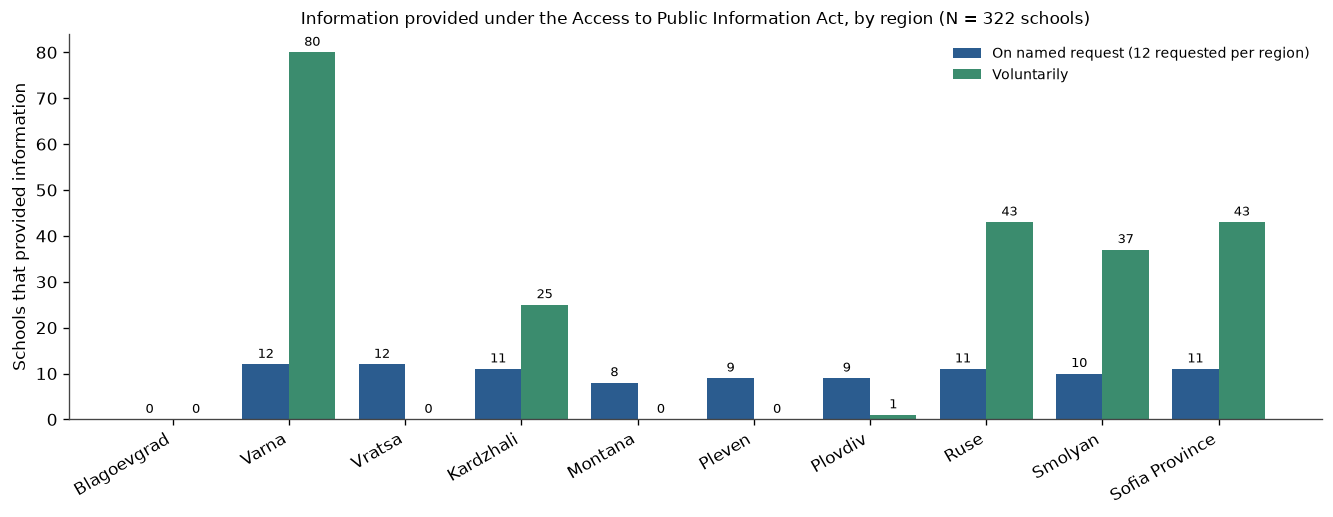

In [3]:
zdoi_regions = zdoi_oblasti[zdoi_oblasti["oblast"] != "Общо"].set_index("oblast")
zdoi_total = zdoi_oblasti[zdoi_oblasti["oblast"] == "Общо"].iloc[0]

assert zdoi_schools["school"].is_unique
assert set(schools["school"]) <= set(zdoi_schools["school"])
zdoi_by_school = zdoi_schools.set_index("school")
for column, source in [
    ("n_dogovori", contracts.groupby("school").size()),
    ("n_dogovori_bez_stoynost", contracts.groupby("school")["amount_excl_vat_num"].apply(lambda s: int(s.isna().sum()))),
]:
    assert (source.reindex(zdoi_by_school.index).fillna(0).astype(int) == zdoi_by_school[column]).all()
eur_by_school = contracts.groupby("school")["amount_excl_vat_num"].sum().reindex(zdoi_by_school.index).fillna(0.0)
assert ((eur_by_school - zdoi_by_school["stoynost_dogovori_bez_dds_eur"]).abs() < 0.005).all()

by_region = zdoi_schools.groupby("oblast").agg(
    requested=("izyskano_poimenno", lambda s: int((s == "да").sum())),
    contracts=("n_dogovori", "sum"),
).reindex(zdoi_regions.index)
assert (by_region["requested"] == zdoi_regions["izyskani_poimenno"]).all()
assert (by_region["contracts"] == zdoi_regions["n_dogovori"]).all()
assert int(zdoi_total["obshto_predostavili"]) == len(schools) == 322

provided = zdoi_regions[
    [
        "izyskani_poimenno", "poimenno_predostavili", "dobrovolni_predostavili", "obshto_predostavili",
        "n_dogovori", "stoynost_dogovori_bez_dds_eur",
    ]
].copy()
provided.columns = [
    "requested by name", "provided on named request", "provided voluntarily", "provided in total",
    "contracts", "contracts, EUR excl. VAT",
]
provided.index = provided.index.str.replace("Област ", "", regex=False)
oblast_en = {
    "Благоевград": "Blagoevgrad", "Варна": "Varna", "Враца": "Vratsa", "Кърджали": "Kardzhali",
    "Монтана": "Montana", "Плевен": "Pleven", "Пловдив": "Plovdiv", "Русе": "Ruse",
    "Смолян": "Smolyan", "София-област": "Sofia Province",
}
assert set(provided.index) == set(oblast_en)
provided = provided.rename(index=oblast_en)
provided.loc["Total"] = provided.sum()
display(provided)

FIG_DIR.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(11, 4.2), constrained_layout=True)
positions = np.arange(len(provided) - 1)
width = 0.4
named = ax.bar(positions - width / 2, provided["provided on named request"].iloc[:-1], width, color="#2b5c8f", label="On named request (12 requested per region)")
voluntary = ax.bar(positions + width / 2, provided["provided voluntarily"].iloc[:-1], width, color="#3b8c6e", label="Voluntarily")
ax.bar_label(named, padding=2, fontsize=8)
ax.bar_label(voluntary, padding=2, fontsize=8)
ax.set_xticks(positions)
ax.set_xticklabels(provided.index[:-1], rotation=30, ha="right")
ax.set_ylabel("Schools that provided information")
ax.set_title("Information provided under the Access to Public Information Act, by region (N = 322 schools)", fontsize=10)
ax.legend(loc="upper right", fontsize=8.5, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
save_fig_300(fig, "F0_foi_provided_by_region.png")
plt.show()
plt.close(fig)

### 1.2 Structural characteristics of the corpus

The next cell documents the four structural characteristics that govern the economic reading of the control files: the origin of class 10.03 (*Unestablished procedure for ex-ante control*, `class_10_03`) for each school, the dating of checklists before commitment, the checklists that name no contract, and the split of linked contracts by dating.

In [4]:
assert (schools["internal_rules_present"] == MISSING_MARKER).all()
rules_by_school = control_actions.groupby("school")["internal_rules_present"].apply(list)


def rules_source_state(values: list) -> str:
    if not values:
        return "no control actions"
    if "ДА" in values:
        return "ДА"
    if "НЕ" in values:
        return "НЕ"
    return MISSING_MARKER


rules_source = schools["school"].map(lambda s: rules_source_state(rules_by_school.get(s, [])))
rules_map = (
    pd.DataFrame({"internal_rules_present in control_actions": rules_source, "class_10_03": schools["class_10_03"]})
    .value_counts()
    .rename("schools")
    .reset_index()
    .sort_values("schools", ascending=False)
    .reset_index(drop=True)
)
rules_pairs = {
    (r["internal_rules_present in control_actions"], r["class_10_03"]): int(r["schools"])
    for _, r in rules_map.iterrows()
}
assert rules_pairs == {
    ("ДА", "НЕ"): 199,
    ("НЕ", "ДА"): 3,
    (MISSING_MARKER, "ДА"): 69,
    ("no control actions", MISSING_MARKER): 51,
}

last_pc = control_actions[
    (control_actions["control_type"] == "преди_поемане")
    & (control_actions["is_last_of_type"] == "ДА")
    & (control_actions["contract_rec_id"] != MISSING_MARKER)
]
assert last_pc["contract_rec_id"].is_unique
ct_pc = contracts.merge(
    last_pc[["contract_rec_id", "checklist_present", "checklist_date", "delta_t_num"]],
    on="contract_rec_id",
    how="left",
)
assert len(ct_pc) == len(contracts)

has_action = ct_pc["checklist_present"].notna()
undated = ct_pc["pre_commitment_checklist_dating"] == "недатиран"
raw_missing = ct_pc["checklist_date"] == MISSING_MARKER
present_yes = ct_pc["checklist_present"] == "ДА"
late = ct_pc["delta_t_num"] > 0
dated = has_action & ~undated

dating = pd.DataFrame(
    [
        ("contracts with a linked last pre-commitment action", 291, int(has_action.sum())),
        ("dated, checklist present, not late (Δt <= 0)", 50, int((dated & present_yes & ~late).sum())),
        (
            "of which raw checklist_date is the missing marker",
            4,
            int((dated & present_yes & ~late & raw_missing).sum()),
        ),
        (
            "checklists present with raw checklist_date = missing marker (undated and dated)",
            136,
            int((has_action & present_yes & raw_missing).sum()),
        ),
        ("dated, checklist present, late (Δt > 0)", 97, int((dated & present_yes & late).sum())),
        ("dated, checklist not present", 1, int((dated & ~present_yes).sum())),
        ("undated, checklist present", 132, int((undated & present_yes).sum())),
        (
            "undated, checklist present, Δt = 0 and class_10_01 = НЕ",
            132,
            int((undated & present_yes & (ct_pc["delta_t_num"] == 0) & (ct_pc["class_10_01"] == "НЕ")).sum()),
        ),
        ("undated, checklist not present", 11, int((undated & ~present_yes).sum())),
        ("contracts without a linked pre-commitment action", 1104, int((~has_action).sum())),
    ],
    columns=["measure", "expected", "computed"],
)
dating["match"] = dating["expected"] == dating["computed"]
assert dating["match"].all()
assert int((dated & present_yes & ~late).sum() + (dated & present_yes & late).sum() + (dated & ~present_yes).sum()) == 148
assert int(undated.sum()) == 143

link_rows = []
for ctype in ["чл_237б_ЗОП", "преди_поемане", "преди_разход"]:
    sub = control_actions[control_actions["control_type"] == ctype]
    link_rows.append(
        {
            "control_type": ctype,
            "actions": len(sub),
            "unlinked (contract_rec_id = missing marker)": int((sub["contract_rec_id"] == MISSING_MARKER).sum()),
        }
    )
unlinked_table = pd.DataFrame(link_rows)
unlinked_237b, unlinked_pre_commit, unlinked_pre_pay = (int(v) for v in unlinked_table.iloc[:, 2])
assert (unlinked_pre_commit, unlinked_pre_pay, unlinked_237b) == (853, 691, 12)
assert tuple(int(v) for v in unlinked_table["actions"]) == (18, 1328, 1146)

display(en_view(rules_map))
display(dating)
display(en_view(unlinked_table))

,internal_rules_present in control_actions,class_10_03,schools
0,yes,no,199
1,no document,yes,69
2,no control actions,no document,51
3,no,yes,3


,measure,expected,computed,match
0,contracts with a linked last pre-commitment ac...,291,291,True
1,"dated, checklist present, not late (Δt <= 0)",50,50,True
2,of which raw checklist_date is the missing marker,4,4,True
3,checklists present with raw checklist_date = m...,136,136,True
4,"dated, checklist present, late (Δt > 0)",97,97,True
5,"dated, checklist not present",1,1,True
6,"undated, checklist present",132,132,True
7,"undated, checklist present, Δt = 0 and class_1...",132,132,True
8,"undated, checklist not present",11,11,True
9,contracts without a linked pre-commitment action,1104,1104,True


,control_type,actions,unlinked (contract_rec_id = missing marker)
0,Art. 237b PPA,18,12
1,before commitment,1328,853
2,before expenditure,1146,691


### 1.3 Internal consistency tests

Because the raw scanned documents are not part of the public repository, verification rests on three reproducible deterministic tests: the dating label of the checklist before commitment (`pre_commitment_checklist_dating`) against the interval in days between the checklist and the contract (`delta_t_days`) and the raw date written on the checklist (`checklist_date`); the exact reconciliation of class 10.01 (`class_10_01`) from its components (the presence of the checklist, its timing Δt, and the last linked checklist); and the check of the domain of the four flags (`flag_split_30d`, `flag_predated`, `flag_bunching_50k`, `flag_regime_mismatch`) and of the readability of the contract dates for the 1,167 contracts linked to the ISUN open data (ISUN 2020, 2026), together with the check that the flags hold the missing marker for the remaining contracts.

In [5]:
undated_ct = ct_pc[undated]
test1_mismatch = int(
    (~(undated_ct["delta_t_num"].fillna(0) == 0)).sum()
    + (undated_ct["checklist_date"] != MISSING_MARKER).sum()
)
raw_missing_present = int((raw_missing & present_yes).sum())
dated_raw_missing = int((dated & present_yes & raw_missing).sum())
undated_present = int((undated & present_yes).sum())
test1_mismatch += int(raw_missing_present != undated_present + dated_raw_missing)

repro_10_01 = np.where(
    ct_pc["checklist_present"].isna() | (ct_pc["checklist_present"] != "ДА") | (ct_pc["delta_t_num"] > 0),
    "ДА",
    "НЕ",
)
test2_mismatch = int((repro_10_01 != ct_pc["class_10_01"].values).sum())

isun_linked = contracts[contracts["isun_contract_id"] != MISSING_MARKER]
flag_cols = ["flag_split_30d", "flag_predated", "flag_bunching_50k", "flag_regime_mismatch"]
test3_mismatch = int(pd.to_datetime(isun_linked["contract_date_effective"], errors="coerce").isna().sum())
for fcol in flag_cols:
    test3_mismatch += int((~isun_linked[fcol].isin(["True", "False"])).sum())
    test3_mismatch += int((contracts[fcol] != MISSING_MARKER).sum() != len(isun_linked))
    test3_mismatch += int((contracts[fcol] == MISSING_MARKER).sum() != len(contracts) - len(isun_linked))

consistency_tests = pd.DataFrame(
    [
        ("1. dating label vs delta_t_days and raw checklist_date", len(undated_ct), test1_mismatch),
        ("2. class_10_01 vs its components", len(ct_pc), test2_mismatch),
        ("3. ISUN-linked contracts: flag domain and contract dates", len(isun_linked), test3_mismatch),
    ],
    columns=["test", "contracts checked", "mismatches"],
)
consistency_tests["passed"] = consistency_tests["mismatches"] == 0
assert consistency_tests["passed"].all()
assert (len(undated_ct), len(isun_linked)) == (143, 1167)

record_conclusion("Section 1", "invariants", "schools in the corpus", len(schools))
record_conclusion("Section 1", "invariants", "contracts in the corpus", len(contracts))
record_conclusion("Section 1", "invariants", "contracts with numeric amount_excl_vat", int(contracts["amount_excl_vat_num"].notna().sum()))
record_conclusion("Section 1", "invariants", "contracts with missing amount_excl_vat", int(contracts["amount_excl_vat_num"].isna().sum()))
record_conclusion("Section 1", "invariants", "total contracted EUR excl VAT", f"{total_eur_excl_vat:.2f}")
record_conclusion("Section 1", "invariants", "control actions total", len(control_actions))
record_conclusion("Section 1", "invariants", "unlinked art_237b actions", unlinked_237b)
record_conclusion("Section 1", "invariants", "unlinked pre_commitment actions", unlinked_pre_commit)
record_conclusion("Section 1", "invariants", "unlinked pre_expenditure actions", unlinked_pre_pay)
record_conclusion("Section 1", "invariants", "ISUN-linked contracts", len(isun_linked))

display(consistency_tests)
print(
    f"Data verification passed | {len(sha_rows)}/{len(csv_names)} SHA-256 matched | {len(schools)} schools | "
    f"{len(contracts):,} contracts ({int(contracts['amount_excl_vat_num'].notna().sum()):,} numeric = "
    f"{fmt_eur(total_eur_excl_vat)} excl. VAT; {int(contracts['amount_excl_vat_num'].isna().sum())} missing) | "
    f"Unlinked actions: {unlinked_237b}/{int(unlinked_table['actions'].iloc[0])} Art.237b, "
    f"{unlinked_pre_commit}/{int(unlinked_table['actions'].iloc[1]):,} pre-commitment, "
    f"{unlinked_pre_pay}/{int(unlinked_table['actions'].iloc[2]):,} pre-expenditure | "
    f"{int(consistency_tests['passed'].sum())}/{len(consistency_tests)} consistency tests PASSED."
)

,test,contracts checked,mismatches,passed
0,1. dating label vs delta_t_days and raw checkl...,143,0,True
1,2. class_10_01 vs its components,1395,0,True
2,3. ISUN-linked contracts: flag domain and cont...,1167,0,True


Data verification passed | 9/9 SHA-256 matched | 322 schools | 1,395 contracts (1,233 numeric = EUR 28,062,137.01 excl. VAT; 162 missing) | Unlinked actions: 12/18 Art.237b, 853/1,328 pre-commitment, 691/1,146 pre-expenditure | 3/3 consistency tests PASSED.


**Economic & Financial Control Implication:** The corpus holds **1,395 contracts** worth **EUR 28,062,137.01 excl. VAT**; 162 contracts have no documented amount, so every EUR figure in this study covers **1,233 priced contracts**.

**Checklists before commitment (Indicator 1).** Of the 1,328 checklists before commitment, **853 name no contract**. A contract without a linked checklist may still be covered by one of them, so these 853 checklists raise the share of contracts counted as having no control. In the opposite direction, **136 checklists** are counted as timely without a raw date, in two groups among the 291 contracts with a linked checklist before commitment: **132 undated checklists**, whose date was set equal to the contract date, and **4 checklists labelled dated**, whose raw date (`checklist_date`) is the missing marker and whose date comes from `checklist_date_effective`. These checklists lower the share, which is why sensitivity 4 treats an undated checklist as not proving ex-ante control.

**Checklists before expenditure (Indicator 3).** Of the 1,146 checklists before expenditure, **691 name no contract**. This limits Indicator 3: a contract without a linked checklist before expenditure may still be covered by one of them, so the contracts with a documented checklist before expenditure may be undercounted. It does not enter the reasoning on Indicator 1.

**Checklists under Art. 237b PPA (Indicator 2).** Of the 18 checklists under Art. 237b, **12 name no contract**. This limits Indicator 2 in the same way: a contract without a linked checklist under Art. 237b may still be covered by one of them, so the contracts with a documented checklist under Art. 237b may be undercounted.

**Class 10.03 (`class_10_03`).** The class is assessed for each of the 322 schools from the field on internal rules in the checklists of the school. For **199** schools the checklists state that rules exist (`class_10_03` equals `НЕ`); for **3** schools they state that rules do not exist (`ДА`); for **69** schools the checklists hold no document on internal rules, and the missing document gives `class_10_03` equal to `ДА`; the **51** schools without any checklist remain `няма_документ` and are not counted among the schools without an established procedure.

The answer to the financial-control question of this section: the distortions exist but are documented, namely **136** checklists counted as timely without a raw date and **853** checklists before commitment that name no contract. The three consistency tests found no mismatch, so the figures in the next sections rest on intact and internally consistent tables.

## 2. Coverage of the Documentary Corpus and Territorial Concentration

**Financial-control question:** What share of the national population of schools with a contract under procedure `BG-RRP-1.015` and of the contracted value (EUR excl. VAT) reported by Beluhov (2026a) is observable through the files obtained under the Access to Public Information Act, and how does the territorial concentration of these files limit the generalization of the control findings?

,ADFI directorate,schools in the corpus
0,FID7,146
1,FID4,101
2,FID6,36
3,FID3,29
4,FID5,10


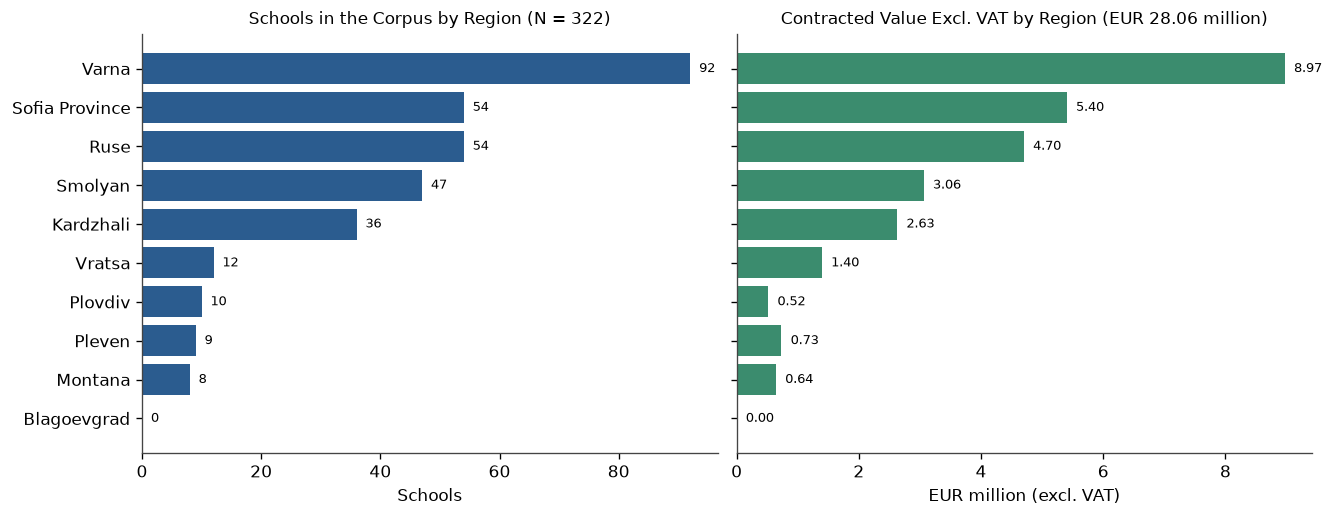

Coverage | Named request: 93/120 (77.50%) | Voluntarily: 229 | 322 schools (278 with contract, 276 STEM, 44 without) | National: 278/2222 (12.51%) | EUR 28,062,137.01 / EUR 240,494,471.77 (11.67%) | ISUN-linked EUR 23,133,141.57 (9.62%)


In [6]:
national_schools = int(
    e2_summary.loc[
        (e2_summary["part"] == "Section 2") & (e2_summary["measure"] == "schools with contract"), "value"
    ].iloc[0]
)
national_eur_excl_vat = float(
    e2_summary.loc[
        (e2_summary["part"] == "Section 2") & (e2_summary["measure"] == "total contracted EUR excl VAT"), "value"
    ].iloc[0]
)
assert national_schools == 2222 and round(national_eur_excl_vat, 2) == 240494471.77

schools_with_contract = int(contracts["school"].nunique())
stem_schools = int(contracts.loc[contracts["is_stem_project"] == "ДА", "school"].nunique())
schools_no_contract = len(schools) - schools_with_contract
assert (schools_with_contract, stem_schools, schools_no_contract) == (278, 276, 44)
assert schools_with_contract == int(zdoi_total["uchilishta_s_dogovori"])

region_rows = provided.drop(index="Total")
named_req = int(provided.loc["Total", "requested by name"])
named_prov = int(provided.loc["Total", "provided on named request"])
vol_prov = int(provided.loc["Total", "provided voluntarily"])
assert (named_req, named_prov, vol_prov) == (120, 93, 229)
assert named_prov + vol_prov == len(schools) == 322

named_stats = [
    wilson_ci(int(k), int(n))
    for k, n in zip(region_rows["provided on named request"], region_rows["requested by name"])
]
coverage_by_region = region_rows.copy()
coverage_by_region["named_response_rate"] = [round(s[0], 6) for s in named_stats]
coverage_by_region["named_wilson_low"] = [round(s[1], 6) for s in named_stats]
coverage_by_region["named_wilson_high"] = [round(s[2], 6) for s in named_stats]
DERIVED_DIR.mkdir(parents=True, exist_ok=True)
coverage_by_region.to_csv(
    DERIVED_DIR / "foi_coverage_by_region.csv", sep=";", encoding="utf-8", lineterminator="\n"
)

directorate_counts = schools["fid_directorate"].value_counts().to_dict()
assert directorate_counts == {"FID7": 146, "FID4": 101, "FID6": 36, "FID3": 29, "FID5": 10}
directorates = (
    schools["fid_directorate"]
    .value_counts()
    .rename_axis("ADFI directorate")
    .reset_index(name="schools in the corpus")
)
display(directorates)

assert provided.loc["Varna", "provided in total"] == 92
assert tuple(provided.loc["Blagoevgrad", ["provided on named request", "requested by name"]]) == (0, 12)
regions_with_schools = int((region_rows["provided in total"] > 0).sum())
assert (regions_with_schools, len(directorate_counts)) == (9, 5)

isun_eur = round(float(isun_linked["amount_excl_vat_num"].sum()), 2)
assert (len(isun_linked), isun_eur) == (1167, 23133141.57)
assert abs(provided.loc["Total", "contracts, EUR excl. VAT"] - total_eur_excl_vat) < 0.005

share_schools = schools_with_contract / national_schools
share_eur_all = total_eur_excl_vat / national_eur_excl_vat
share_eur_isun = isun_eur / national_eur_excl_vat
assert (round(share_schools * 100, 2), round(share_eur_all * 100, 2), round(share_eur_isun * 100, 2)) == (12.51, 11.67, 9.62)

named_p, named_lo, named_hi = wilson_ci(named_prov, named_req)
record_conclusion("Section 2", "coverage", "schools provided on named request", f"{named_prov}/{named_req}", round(named_lo, 6), round(named_hi, 6), "Wilson")
record_conclusion("Section 2", "coverage", "schools provided voluntarily", vol_prov)
record_conclusion("Section 2", "coverage", "schools in the corpus", len(schools))
record_conclusion("Section 2", "coverage", "schools with contract", schools_with_contract)
record_conclusion("Section 2", "coverage", "schools with STEM project contract", stem_schools)
record_conclusion("Section 2", "coverage", "schools without contract", schools_no_contract)
record_conclusion("Section 2", "coverage", "national schools with contract", national_schools)
record_conclusion("Section 2", "coverage", "national contracted EUR excl VAT", f"{national_eur_excl_vat:.2f}")
record_conclusion("Section 2", "coverage", "share of national schools with contract", f"{share_schools:.6f}")
record_conclusion("Section 2", "coverage", "share of national contracted EUR excl VAT, all contracts", f"{share_eur_all:.6f}")
record_conclusion("Section 2", "coverage", "share of national contracted EUR excl VAT, ISUN-linked contracts", f"{share_eur_isun:.6f}")

plot_rows = region_rows.sort_values("provided in total", ascending=True)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True, constrained_layout=True)
ax1.barh(plot_rows.index, plot_rows["provided in total"], color="#2b5c8f")
ax1.set_title(f"Schools in the Corpus by Region (N = {len(schools)})", fontsize=10)
ax1.set_xlabel("Schools")
for i, v in enumerate(plot_rows["provided in total"]):
    ax1.text(v + 1.5, i, str(int(v)), va="center", fontsize=8)
eur_millions = plot_rows["contracts, EUR excl. VAT"] / 1e6
ax2.barh(plot_rows.index, eur_millions, color="#3b8c6e")
ax2.set_title(f"Contracted Value Excl. VAT by Region (EUR {total_eur_excl_vat / 1e6:.2f} million)", fontsize=10)
ax2.set_xlabel("EUR million (excl. VAT)")
for i, v in enumerate(eur_millions):
    ax2.text(v + 0.15, i, f"{v:.2f}", va="center", fontsize=8)
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
save_fig_300(fig, "F1_corpus_schools_and_value_by_region.png")
plt.show()
plt.close(fig)

print(
    f"Coverage | Named request: {named_prov}/{named_req} ({named_p:.2%}) | Voluntarily: {vol_prov} | "
    f"{len(schools)} schools ({schools_with_contract} with contract, {stem_schools} STEM, {schools_no_contract} without) | "
    f"National: {schools_with_contract}/{national_schools} ({share_schools:.2%}) | "
    f"{fmt_eur(total_eur_excl_vat)} / {fmt_eur(national_eur_excl_vat)} ({share_eur_all:.2%}) | "
    f"ISUN-linked {fmt_eur(isun_eur)} ({share_eur_isun:.2%})"
)

**Economic & Financial Control Implication:** The documentary corpus covers **278 schools with a contract**, or **12.51%** of the **2,222** schools with a contract nationwide (Beluhov, 2026a). By value, the **1,167 contracts linked to ISUN** (EUR 23,133,141.57 excl. VAT) represent **9.62%** of the national contracted value of **EUR 240,494,471.77 excl. VAT**; all **1,395** contracts of the corpus (EUR 28,062,137.01) correspond to **11.67%**, but this base also includes contracts not reported in ISUN. The corpus is territorially concentrated: **92 of the 322 schools** are in Varna, the schools come from **9 regions** and **5 ADFI directorates**, and Blagoevgrad provided no documents on named request (0 of 12).

The answer to the financial-control question of this section: the files cover about one eighth of the national schools with a contract and about one tenth of the contracted value, concentrated in a few regions; the control findings in the next sections describe this observable sub-population and are not a national random sample.

## 3. Timing of the Checklist before Commitment and Hypothesis H3 (Indicator 1)

**Financial-control question:** How much public funding (EUR excl. VAT) did the schools commit by contract without a timely documented checklist before commitment (Δt ≤ 0), and does the share of such contracts exceed the pre-specified 5% threshold under both the Wilson score (Wilson, 1927) and the school-cluster bootstrap (Efron and Tibshirani, 1994) lower bounds, for the main rule, the five sensitivities, and the three sub-populations?

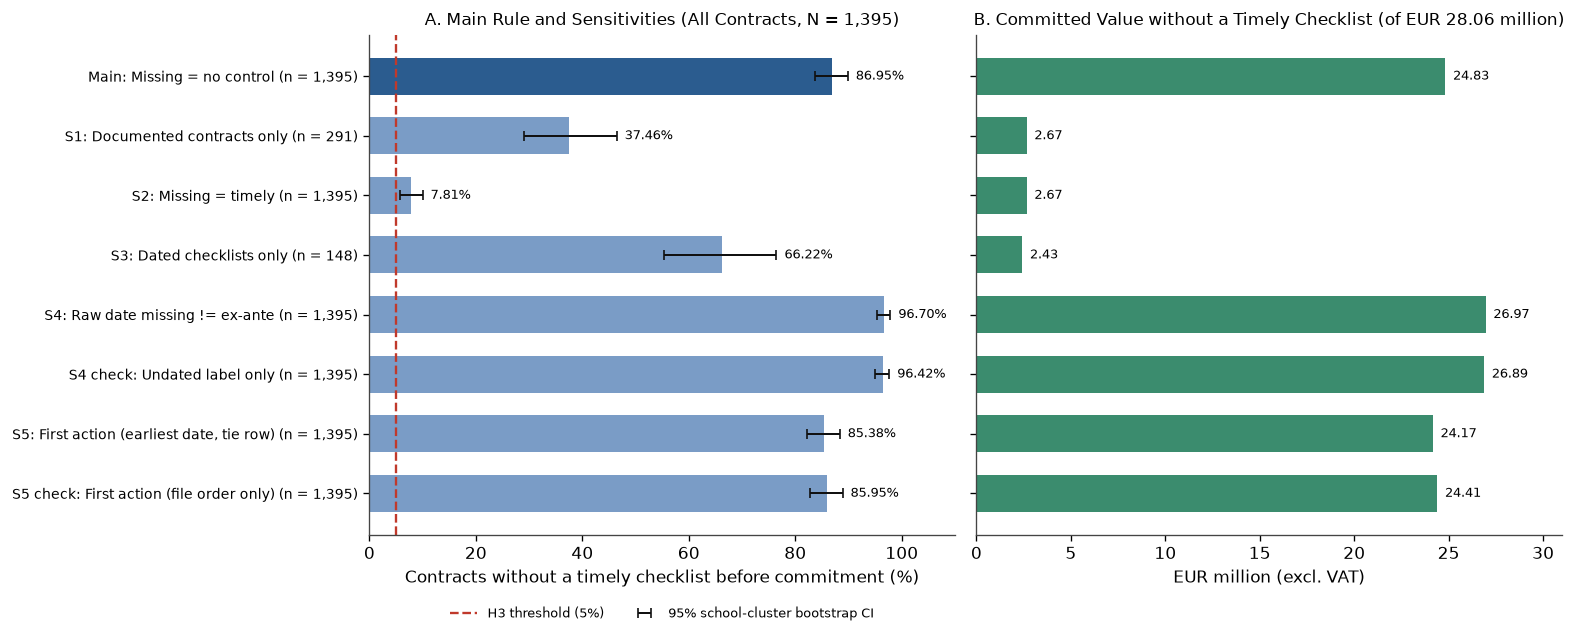

,rule,k_no_control,n_total,share,wilson_low,boot_low,h3_confirmed,eur_excl_vat_no_control
0,Main: Missing = no control,1213,1395,0.869534,0.850840,0.837739,True,24831164.29
3,S1: Documented contracts only,109,291,0.374570,0.320933,0.290218,True,2667854.19
6,S2: Missing = timely,109,1395,0.078136,0.065183,0.058446,True,2667854.19
9,S3: Dated checklists only,98,148,0.662162,0.582718,0.553333,True,2434301.81
12,S4: Raw date missing != ex-ante,1349,1395,0.967025,0.956297,0.953868,True,26966756.59
15,S4 check: Undated label only,1345,1395,0.964158,0.953058,0.949929,True,26885215.33
18,"S5: First action (earliest date, tie row)",1191,1395,0.853763,0.834250,0.821588,True,24171776.08
21,S5 check: First action (file order only),1199,1395,0.859498,0.840274,0.828003,True,24405784.21


subpopulation,"All contracts (N=1,395)","STEM contracts (N=1,226)","STEM + unconfirmed (N=1,382)"
rule,,,
Main: Missing = no control,True,True,True
S1: Documented contracts only,True,True,True
S2: Missing = timely,True,True,True
S3: Dated checklists only,True,True,True
S4: Raw date missing != ex-ante,True,True,True
S4 check: Undated label only,True,True,True
"S5: First action (earliest date, tie row)",True,True,True
S5 check: First action (file order only),True,True,True


H3 | Main rule: 1,213/1,395 (86.95%), Wilson low 85.08%, bootstrap low 83.77% | EUR 24,831,164.29 of EUR 28,062,137.01 | No linked checklist before commitment: 1,104 contracts, EUR 22,163,310.10 | Contracts with several linked checklists: 81 | H3 confirmed in 24/24 specifications


In [7]:
pc_all = control_actions[
    (control_actions["control_type"] == "преди_поемане") & (control_actions["contract_rec_id"] != MISSING_MARKER)
].copy()
pc_all["row_order"] = np.arange(len(pc_all))
pc_all["eff_dt_sort"] = pd.to_datetime(pc_all["checklist_date_effective"], errors="coerce").fillna(pd.Timestamp("2099-12-31"))
pc_first_det = pc_all.sort_values(["contract_rec_id", "eff_dt_sort", "row_order"]).drop_duplicates("contract_rec_id", keep="first")
pc_first_ord = pc_all.sort_values(["contract_rec_id", "row_order"]).drop_duplicates("contract_rec_id", keep="first")
multi_linked = int((pc_all.groupby("contract_rec_id").size() > 1).sum())

m = ct_pc.merge(
    pc_first_det[["contract_rec_id", "checklist_present", "delta_t_num"]].rename(
        columns={"checklist_present": "first_det_present", "delta_t_num": "first_det_dt"}
    ),
    on="contract_rec_id",
    how="left",
).merge(
    pc_first_ord[["contract_rec_id", "checklist_present", "delta_t_num"]].rename(
        columns={"checklist_present": "first_ord_present", "delta_t_num": "first_ord_dt"}
    ),
    on="contract_rec_id",
    how="left",
)
assert len(m) == len(contracts) and (m["contract_rec_id"].values == ct_pc["contract_rec_id"].values).all()

has_action = m["checklist_present"].notna()
no_action = ~has_action
class_gap = m["class_10_01"] == "ДА"
undated_m = m["pre_commitment_checklist_dating"] == "недатиран"
raw_missing_m = m["checklist_date"] == MISSING_MARKER
assert int(has_action.sum()) == 291 and int(no_action.sum()) == 1104
assert int((has_action & ~undated_m).sum()) == 148 and int((undated_m & ~raw_missing_m).sum()) == 0
no_action_eur = float(m.loc[no_action, "amount_excl_vat_num"].sum())
c10_01_eur = float(m.loc[class_gap, "amount_excl_vat_num"].sum())
assert round(no_action_eur, 2) == 22163310.10
assert round(c10_01_eur, 2) == 24831164.29

subpops = [
    ("All contracts (N=1,395)", np.ones(len(m), dtype=bool)),
    ("STEM contracts (N=1,226)", (m["is_stem_project"] == "ДА").values),
    ("STEM + unconfirmed (N=1,382)", (m["is_stem_project"].isin(["ДА", "непотвърден"])).values),
]

every = np.ones(len(m), dtype=bool)
rules = [
    ("Main: Missing = no control", every, class_gap.values),
    ("S1: Documented contracts only", has_action.values, class_gap.values),
    ("S2: Missing = timely", every, (has_action & class_gap).values),
    ("S3: Dated checklists only", (has_action & ~undated_m).values, class_gap.values),
    ("S4: Raw date missing != ex-ante", every, (class_gap | (has_action & raw_missing_m)).values),
    ("S4 check: Undated label only", every, (class_gap | (has_action & undated_m)).values),
    ("S5: First action (earliest date, tie row)", every, (m["first_det_present"].isna() | (m["first_det_present"] != "ДА") | (m["first_det_dt"] > 0)).values),
    ("S5 check: First action (file order only)", every, (m["first_ord_present"].isna() | (m["first_ord_present"] != "ДА") | (m["first_ord_dt"] > 0)).values),
]

t1_rows = []
for rule_name, elig_mask, fail_mask in rules:
    for sub_name, sub_mask in subpops:
        mask = elig_mask & sub_mask
        sub_df = m.loc[mask]
        ind = fail_mask[mask].astype(int)
        n = len(sub_df)
        k = int(ind.sum())
        p_w, w_lo, w_hi = wilson_ci(k, n)
        p_b, b_lo, b_hi = cluster_bootstrap_ci(sub_df["school"].values, ind)
        h3_conf = (w_lo > H3_THRESHOLD) and (b_lo > H3_THRESHOLD)
        fail_eur = float(sub_df.loc[ind == 1, "amount_excl_vat_num"].sum())
        fail_missing_amt = int(sub_df.loc[ind == 1, "amount_excl_vat_num"].isna().sum())
        tot_eur = float(sub_df["amount_excl_vat_num"].sum())
        t1_rows.append({
            "rule": rule_name,
            "subpopulation": sub_name,
            "k_no_control": k,
            "n_total": n,
            "share": round(p_w, 6),
            "wilson_low": round(w_lo, 6),
            "wilson_high": round(w_hi, 6),
            "boot_low": round(b_lo, 6),
            "boot_high": round(b_hi, 6),
            "h3_confirmed": h3_conf,
            "eur_excl_vat_no_control": round(fail_eur, 2),
            "eur_excl_vat_total": round(tot_eur, 2),
            "eur_share": round(fail_eur / tot_eur, 6) if tot_eur > 0 else 0.0,
            "missing_amount_contracts_no_control": fail_missing_amt,
        })
        if sub_name.startswith("All") or sub_name.startswith("STEM contracts"):
            record_conclusion(
                "Section 3", "H3_pre_commitment",
                f"{rule_name} | {sub_name} | share",
                f"{p_w:.6f}", f"{w_lo:.6f}/{b_lo:.6f}", f"{w_hi:.6f}/{b_hi:.6f}",
                "Wilson/ClusterBootstrap", str(h3_conf)
            )
            record_conclusion(
                "Section 3", "H3_pre_commitment",
                f"{rule_name} | {sub_name} | EUR excl VAT",
                f"{fail_eur:.2f}"
            )

t1 = pd.DataFrame(t1_rows)
t1.to_csv(DERIVED_DIR / "T1_h3_pre_commitment.csv", sep=";", index=False, encoding="utf-8", lineterminator="\n")

all_rows = t1[t1["subpopulation"].str.startswith("All")].set_index("rule")
stem_rows = t1[t1["subpopulation"].str.startswith("STEM contracts")].set_index("rule")
assert round(all_rows.loc["Main: Missing = no control", "share"] * 100, 2) == 86.95
assert round(all_rows.loc["Main: Missing = no control", "wilson_low"] * 100, 2) == 85.08
assert round(stem_rows.loc["Main: Missing = no control", "share"] * 100, 2) == 85.64
assert round(stem_rows.loc["Main: Missing = no control", "wilson_low"] * 100, 2) == 83.57
assert round(all_rows.loc["S1: Documented contracts only", "share"] * 100, 2) == 37.46
assert round(all_rows.loc["S1: Documented contracts only", "wilson_low"] * 100, 2) == 32.09
assert round(all_rows.loc["S2: Missing = timely", "share"] * 100, 2) == 7.81
assert round(all_rows.loc["S2: Missing = timely", "wilson_low"] * 100, 2) == 6.52
assert round(stem_rows.loc["S2: Missing = timely", "share"] * 100, 2) == 8.65
assert round(stem_rows.loc["S2: Missing = timely", "wilson_low"] * 100, 2) == 7.20
assert round(all_rows.loc["S3: Dated checklists only", "share"] * 100, 2) == 66.22
assert round(all_rows.loc["S3: Dated checklists only", "wilson_low"] * 100, 2) == 58.27
assert round(all_rows.loc["S4: Raw date missing != ex-ante", "share"] * 100, 2) == 96.70
assert round(all_rows.loc["S4 check: Undated label only", "share"] * 100, 2) == 96.42
assert round(stem_rows.loc["S4 check: Undated label only", "share"] * 100, 2) == 96.00
assert round(all_rows.loc["S5: First action (earliest date, tie row)", "share"] * 100, 2) == 85.38
assert round(all_rows.loc["S5 check: First action (file order only)", "share"] * 100, 2) == 85.95

plot_df = t1[t1["subpopulation"].str.startswith("All")].iloc[::-1].reset_index(drop=True)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True, constrained_layout=True)
y = np.arange(len(plot_df))
colors = ["#2b5c8f" if r.startswith("Main") else "#7a9cc6" for r in plot_df["rule"]]
ax1.barh(y, plot_df["share"] * 100, color=colors, height=0.62)
ax1.errorbar(
    plot_df["share"] * 100, y,
    xerr=[
        (plot_df["share"] - plot_df["boot_low"]) * 100,
        (plot_df["boot_high"] - plot_df["share"]) * 100,
    ],
    fmt="none", ecolor="#111111", elinewidth=1.2, capsize=3, label="95% school-cluster bootstrap CI",
)
ax1.axvline(H3_THRESHOLD * 100, color="#c0392b", linestyle="--", linewidth=1.4, label=f"H3 threshold ({H3_THRESHOLD:.0%})")
ax1.set_yticks(y)
ax1.set_yticklabels([f"{r} (n = {n:,})" for r, n in zip(plot_df["rule"], plot_df["n_total"])], fontsize=8.5)
ax1.set_xlabel("Contracts without a timely checklist before commitment (%)")
ax1.set_title(f"A. Main Rule and Sensitivities (All Contracts, N = {len(m):,})", fontsize=10)
ax1.set_xlim(0, 110)
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=8, frameon=False)
for i, r in plot_df.iterrows():
    ax1.text(r["boot_high"] * 100 + 1.5, i, f"{r['share'] * 100:.2f}%", va="center", fontsize=8)
ax2.barh(y, plot_df["eur_excl_vat_no_control"] / 1e6, color="#3b8c6e", height=0.62)
ax2.set_xlabel("EUR million (excl. VAT)")
ax2.set_title(f"B. Committed Value without a Timely Checklist (of EUR {total_eur_excl_vat / 1e6:.2f} million)", fontsize=10)
ax2.set_xlim(0, 31)
for i, r in plot_df.iterrows():
    ax2.text(r["eur_excl_vat_no_control"] / 1e6 + 0.4, i, f"{r['eur_excl_vat_no_control'] / 1e6:.2f}", va="center", fontsize=8)
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
save_fig_300(fig, "F2_h3_pre_commitment_control.png")
plt.show()
plt.close(fig)

decisions = (
    t1.pivot(index="rule", columns="subpopulation", values="h3_confirmed")
    .reindex(index=[r[0] for r in rules], columns=[s[0] for s in subpops])
)
display(t1[t1["subpopulation"].str.startswith("All")][
    ["rule", "k_no_control", "n_total", "share", "wilson_low", "boot_low", "h3_confirmed", "eur_excl_vat_no_control"]
])
display(decisions)

main_row = all_rows.loc["Main: Missing = no control"]
print(
    f"H3 | Main rule: {int(main_row['k_no_control']):,}/{int(main_row['n_total']):,} ({main_row['share']:.2%}), "
    f"Wilson low {main_row['wilson_low']:.2%}, bootstrap low {main_row['boot_low']:.2%} | "
    f"{fmt_eur(c10_01_eur)} of {fmt_eur(total_eur_excl_vat)} | "
    f"No linked checklist before commitment: {int(no_action.sum()):,} contracts, {fmt_eur(no_action_eur)} | "
    f"Contracts with several linked checklists: {multi_linked} | "
    f"H3 confirmed in {int(t1['h3_confirmed'].sum())}/{len(t1)} specifications"
)

**Economic & Financial Control Implication:** Under the main rule (*"missing = no control"*), **1,213 of 1,395 contracts (86.95%)** representing **EUR 24,831,164.29 excl. VAT** out of **EUR 28,062,137.01** were legally committed without a timely documented checklist before commitment—including **1,104 contracts (EUR 22,163,310.10)** with no linked checklist before commitment at all. The EUR figures cover the priced contracts: 156 of the 1,213 contracts have no documented amount. Hypothesis **H3 is confirmed** across the main rule and sensitivities 1, 3, 4, and 5 (both Wilson and school-cluster bootstrap lower bounds far exceed 5%); only under the extreme conservative sensitivity 2 (*"missing = timely"*, 7.81%, Wilson lower 6.52%) is the bootstrap lower bound reported transparently against the 5% threshold. Even among the **291 contracts with a linked checklist**, **109 (37.46%)** have no timely checklist (sensitivity 1), and among the **148 contracts with a dated checklist**, **98 (66.22%)** (sensitivity 3). Sensitivity 4, which does not accept a checklist without a raw date as proof of ex-ante control, raises the share to **96.70%** (EUR 26,966,756.59). Crucially, **the formal checklist before expenditure (Indicator 3), a condition of the Managing Authority for recognition of the expenditure (Ministry of Education and Science, 2023), does not compensate for the absence of ex-ante control before commitment (Indicator 1)** (Bulgaria, 2006a; Ministry of Finance, 2020), because the legal obligation has already bound the school's budget prior to signature.

The answer to the financial-control question of this section: EUR 24,831,164.29 excl. VAT, or 88.49% of the priced contracted value, was committed without a timely documented checklist before commitment, and the share of such contracts exceeds the 5% threshold under both lower bounds in all 24 specifications (main rule, five sensitivities with the two checks, and three sub-populations).

## 4. Checklist Formality and Segregation of Duties

**Financial-control question:** When a checklist is present, does it act as an independent preventive barrier of financial control, which the model of the three lines of defense places in the second line (Lecheva, 2026a, slide 25) and the COSO model treats as a control activity (Lecheva, 2026a, slide 5), or as formal completion of a template; how much contracted value (EUR excl. VAT) is covered by formal and by not formal checklists before commitment and before expenditure; and how often is the role of the financial controller documented as combined with that of the contracting authority?

*Definition:* In the codebook of the source corpus (`practice_codebook.csv`, `EXT_FORMAL_CHECKLIST`), a checklist is formal (`ext_formal_checklist` equals `ДА`) when it is issued for several contracts (`contracts_per_checklist_count > 1`), when the financial controller is also the contracting authority (`controller_equals_contracting_authority` equals `ДА`), or when it gives a formal approval although a risk practice is present. The contract value is measured by the last linked checklist of each type (`is_last_of_type` equals `ДА`), as in the main rule of Section 3.

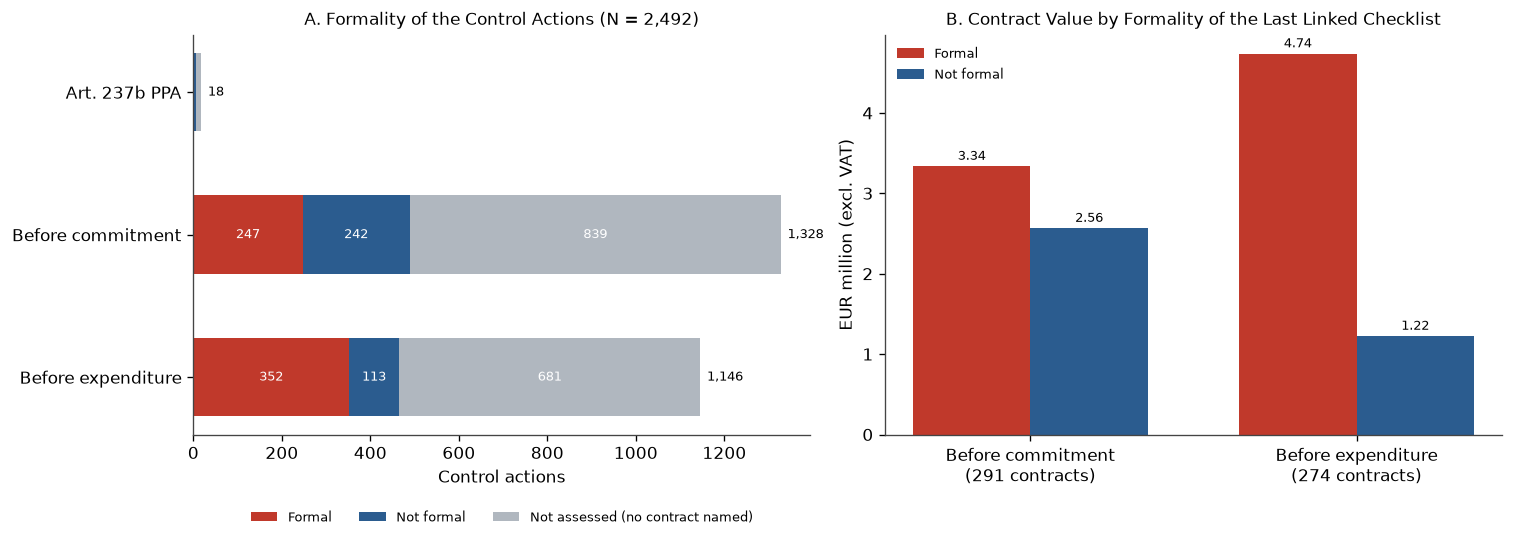

ext_formal_checklist,yes,no,not assessed,actions
control_type,,,,
Art. 237b PPA,0,6,12,18
before commitment,247,242,839,1328
before expenditure,352,113,681,1146


controller_opinion,unqualified approval,approval with reservations,refusal,refusal to give an opinion,no document
ext_formal_checklist,,,,,
yes,593,3,2,0,1
no,182,122,6,2,49
not assessed,1113,189,4,1,225


contracts  eur_excl_vat  \
control_type       ext_formal_checklist                            
Art. 237b PPA      no                            4      62086.36   
before commitment  yes                         135    3335052.07   
                   no                          156    2563774.84   
before expenditure yes                         206    4735318.06   
                   no                           68    1221972.17   

                                         contracts_without_amount  
control_type       ext_formal_checklist                            
Art. 237b PPA      no                                           1  
before commitment  yes                                          4  
                   no                                           6  
before expenditure yes                                          7  
                   no                                           3

contracts  eur_excl_vat  \
ext_formal_checklist class_10_01                            
yes                  yes                 89    2192013.11   
                     no                  46    1143038.96   
no                   yes                 20     475841.08   
                     no                 136    2087933.76   

                                  contracts_without_amount  
ext_formal_checklist class_10_01                            
yes                  yes                                 3  
                     no                                  1  
no                   yes                                 1  
                     no                                  5

,specification,k,n,share,wilson_low,wilson_high,boot_low,boot_high
0,"Formal checklists, control actions with assess...",599,960,0.623958,0.592880,0.654048,0.552574,0.698365
1,"Formal checklists, contracts by last linked ch...",135,291,0.463918,0.407463,0.521313,0.380328,0.549824
2,"Formal checklists, contracts by last linked ch...",206,274,0.751825,0.697433,0.799253,0.679842,0.817877
3,"Role conflict, control actions with confirmed ...",16,617,0.025932,0.016024,0.041706,0.012433,0.042654


Formality | Formal checklists: 599/960 assessed actions (62.40%; Wilson 59.29%-65.40%, bootstrap 55.26%-69.84%) | Batch checklists: 41 (5 with a count above 1,395) | Timely checklist before commitment that is not formal: 136 contracts, EUR 2,087,933.76 (7.44% of EUR 28,062,137.01) | Role conflict: 16/617 confirmed actions (2.59%), 3 contracts, EUR 90,640.22


In [8]:
formal_counts = control_actions["ext_formal_checklist"].value_counts().to_dict()
role_counts = control_actions["controller_equals_contracting_authority"].value_counts().to_dict()
opinion_counts = control_actions["controller_opinion"].value_counts().to_dict()
assert formal_counts == {"ДА": 599, "НЕ": 361, MISSING_MARKER: 1532}
assert role_counts == {"непотвърден": 1870, "НЕ": 601, "ДА": 16, MISSING_MARKER: 5}
assert opinion_counts == {"одобрено": 1888, "с_резерви": 314, "отказ": 12, "отказ_от_мнение": 3, MISSING_MARKER: 275}

action_linked = control_actions["contract_rec_id"] != MISSING_MARKER
formal_yes = control_actions["ext_formal_checklist"] == "ДА"
formal_assessed = control_actions["ext_formal_checklist"].isin(["ДА", "НЕ"])
role_conflict = control_actions["controller_equals_contracting_authority"] == "ДА"
role_confirmed = control_actions["controller_equals_contracting_authority"].isin(["ДА", "НЕ"])
assert int((~formal_assessed & ~action_linked).sum()) == 1532 and int((~formal_assessed & action_linked).sum()) == 0
assert int((formal_yes & ~action_linked).sum()) == 24

contracts_per_checklist = pd.to_numeric(control_actions["contracts_per_checklist_count"], errors="coerce")
batch = contracts_per_checklist > 1
batch_actions = int(batch.sum())
batch_above_corpus = int((contracts_per_checklist > len(contracts)).sum())
assert (batch_actions, batch_above_corpus) == (41, 5)
assert formal_yes[batch].all() and formal_yes[role_conflict].all()

type_order = ["чл_237б_ЗОП", "преди_поемане", "преди_разход"]
formality_by_type = pd.crosstab(control_actions["control_type"], control_actions["ext_formal_checklist"]).reindex(
    index=type_order, columns=["ДА", "НЕ", MISSING_MARKER], fill_value=0
)
formality_by_type["actions"] = formality_by_type.sum(axis=1)
assert formality_by_type.values.tolist() == [[0, 6, 12, 18], [247, 242, 839, 1328], [352, 113, 681, 1146]]

opinion_by_formality = pd.crosstab(control_actions["ext_formal_checklist"], control_actions["controller_opinion"]).reindex(
    index=["ДА", "НЕ", MISSING_MARKER], columns=["одобрено", "с_резерви", "отказ", "отказ_от_мнение", MISSING_MARKER], fill_value=0
)
assert opinion_by_formality.loc["ДА"].tolist() == [593, 3, 2, 0, 1]
assert opinion_by_formality.loc["НЕ"].tolist() == [182, 122, 6, 2, 49]

amount_by_contract = contracts.set_index("contract_rec_id")["amount_excl_vat_num"]
class_10_01_by_contract = contracts.set_index("contract_rec_id")["class_10_01"]
last_linked = control_actions[(control_actions["is_last_of_type"] == "ДА") & action_linked].copy()
last_linked["amount_excl_vat_num"] = last_linked["contract_rec_id"].map(amount_by_contract)
last_linked["class_10_01"] = last_linked["contract_rec_id"].map(class_10_01_by_contract)
assert not last_linked.duplicated(["control_type", "contract_rec_id"]).any()
for ctype in type_order:
    linked_of_type = control_actions.loc[action_linked & (control_actions["control_type"] == ctype), "contract_rec_id"]
    assert set(last_linked.loc[last_linked["control_type"] == ctype, "contract_rec_id"]) == set(linked_of_type)


def contract_value(df: pd.DataFrame, keys: list[str]) -> pd.DataFrame:
    return (
        df.groupby(keys)
        .agg(
            contracts=("contract_rec_id", "size"),
            eur_excl_vat=("amount_excl_vat_num", "sum"),
            contracts_without_amount=("amount_excl_vat_num", lambda s: int(s.isna().sum())),
        )
        .round({"eur_excl_vat": 2})
    )


contract_formality = contract_value(last_linked, ["control_type", "ext_formal_checklist"]).reindex(
    [(t, f) for t in type_order for f in ["ДА", "НЕ"] if (t, f) in set(zip(last_linked["control_type"], last_linked["ext_formal_checklist"]))]
)
pc_last = last_linked[last_linked["control_type"] == "преди_поемане"]
pe_last = last_linked[last_linked["control_type"] == "преди_разход"]
pc_formality_timing = contract_value(pc_last, ["ext_formal_checklist", "class_10_01"])
assert (len(pc_last), len(pe_last)) == (291, 274)
assert pc_formality_timing["contracts"].tolist() == [89, 46, 20, 136]
assert round(pc_formality_timing.loc[("ДА", "НЕ"), "eur_excl_vat"], 2) == 1143038.96
assert round(pc_formality_timing.loc[("НЕ", "НЕ"), "eur_excl_vat"], 2) == 2087933.76
substantive_timely_eur = float(pc_formality_timing.loc[("НЕ", "НЕ"), "eur_excl_vat"])
substantive_timely_share = substantive_timely_eur / total_eur_excl_vat

role_conflict_contracts = control_actions.loc[role_conflict & action_linked, "contract_rec_id"].drop_duplicates()
role_conflict_eur = round(float(role_conflict_contracts.map(amount_by_contract).sum()), 2)
assert (len(role_conflict_contracts), role_conflict_eur) == (3, 90640.22)

share_specs = [
    ("Formal checklists, control actions with assessed formality", control_actions.loc[formal_assessed, "school"], formal_yes[formal_assessed]),
    ("Formal checklists, contracts by last linked checklist before commitment", pc_last["school"], pc_last["ext_formal_checklist"] == "ДА"),
    ("Formal checklists, contracts by last linked checklist before expenditure", pe_last["school"], pe_last["ext_formal_checklist"] == "ДА"),
    ("Role conflict, control actions with confirmed role status", control_actions.loc[role_confirmed, "school"], role_conflict[role_confirmed]),
]
share_rows = []
for spec, clusters, ind in share_specs:
    k, n = int(ind.sum()), len(ind)
    p_w, w_lo, w_hi = wilson_ci(k, n)
    _, b_lo, b_hi = cluster_bootstrap_ci(clusters.values, ind.astype(int).values)
    share_rows.append({
        "specification": spec, "k": k, "n": n, "share": round(p_w, 6),
        "wilson_low": round(w_lo, 6), "wilson_high": round(w_hi, 6),
        "boot_low": round(b_lo, 6), "boot_high": round(b_hi, 6),
    })
    record_conclusion("Section 4", "formality_and_roles", f"{spec} | share", f"{p_w:.6f}", f"{w_lo:.6f}/{b_lo:.6f}", f"{w_hi:.6f}/{b_hi:.6f}", "Wilson/ClusterBootstrap")
formality_shares = pd.DataFrame(share_rows)
assert formality_shares["k"].tolist() == [599, 135, 206, 16] and formality_shares["n"].tolist() == [960, 291, 274, 617]

record_conclusion("Section 4", "formality", "ext_formal_checklist ДА / НЕ / missing", f"{formal_counts['ДА']} / {formal_counts['НЕ']} / {formal_counts[MISSING_MARKER]}")
record_conclusion("Section 4", "formality", "batch checklists (contracts_per_checklist_count > 1)", batch_actions)
record_conclusion("Section 4", "formality", "batch checklists with a count above the corpus contracts", batch_above_corpus)
record_conclusion("Section 4", "formality", "controller_opinion одобрено / с_резерви / отказ / отказ_от_мнение / missing", " / ".join(str(opinion_counts[k]) for k in ["одобрено", "с_резерви", "отказ", "отказ_от_мнение", MISSING_MARKER]))
for (ctype, fval), r in contract_formality.iterrows():
    record_conclusion("Section 4", "formality", f"contracts by last linked checklist | {ctype} | ext_formal_checklist={fval} | EUR excl VAT", f"{r['eur_excl_vat']:.2f}")
record_conclusion("Section 4", "formality", "timely checklist before commitment that is not formal | contracts", int(pc_formality_timing.loc[("НЕ", "НЕ"), "contracts"]))
record_conclusion("Section 4", "formality", "timely checklist before commitment that is not formal | EUR excl VAT", f"{substantive_timely_eur:.2f}")
record_conclusion("Section 4", "role_separation", "controller_equals_contracting_authority ДА / НЕ / непотвърден / missing", f"{role_counts['ДА']} / {role_counts['НЕ']} / {role_counts['непотвърден']} / {role_counts[MISSING_MARKER]}")
record_conclusion("Section 4", "role_separation", "role conflict | linked contracts | EUR excl VAT", f"{len(role_conflict_contracts)} | {role_conflict_eur:.2f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.4), constrained_layout=True)
type_labels = ["Art. 237b PPA", "Before commitment", "Before expenditure"]
seg_specs = [("ДА", "Formal", "#c0392b"), ("НЕ", "Not formal", "#2b5c8f"), (MISSING_MARKER, "Not assessed (no contract named)", "#b0b7bf")]
left = np.zeros(len(type_order))
for code, label, color in seg_specs:
    vals = formality_by_type[code].values
    ax1.barh(type_labels, vals, left=left, color=color, height=0.55, label=label)
    for i, v in enumerate(vals):
        if v >= 60:
            ax1.text(left[i] + v / 2, i, f"{v:,}", ha="center", va="center", fontsize=8, color="white")
    left += vals
for i, total in enumerate(formality_by_type["actions"].values):
    ax1.text(total + 15, i, f"{total:,}", va="center", fontsize=8)
ax1.invert_yaxis()
ax1.set_xlabel("Control actions")
ax1.set_title(f"A. Formality of the Control Actions (N = {len(control_actions):,})", fontsize=10)
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3, fontsize=8, frameon=False)
group_specs = [("преди_поемане", "Before commitment"), ("преди_разход", "Before expenditure")]
x = np.arange(len(group_specs))
width = 0.36
for offset, (code, label, color) in zip([-width / 2, width / 2], seg_specs[:2]):
    vals = [contract_formality.loc[(t, code), "eur_excl_vat"] / 1e6 for t, _ in group_specs]
    bars = ax2.bar(x + offset, vals, width, color=color, label=label)
    ax2.bar_label(bars, labels=[f"{v:.2f}" for v in vals], padding=2, fontsize=8)
ax2.set_xticks(x)
ax2.set_xticklabels([f"{label}\n({len(pc_last if t == 'преди_поемане' else pe_last)} contracts)" for t, label in group_specs])
ax2.set_ylabel("EUR million (excl. VAT)")
ax2.set_title("B. Contract Value by Formality of the Last Linked Checklist", fontsize=10)
ax2.legend(loc="upper left", fontsize=8, frameon=False)
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
plt.show()
plt.close(fig)

formality_terms = {**TERMS_EN, "няма_документ": "not assessed"}
display(en_view(formality_by_type, formality_terms))
display(en_view(opinion_by_formality, formality_terms, TERMS_EN))
display(en_view(contract_formality, formality_terms))
display(en_view(pc_formality_timing, formality_terms))
display(formality_shares)

fs = formality_shares.set_index("specification")
print(
    f"Formality | Formal checklists: {formal_counts['ДА']}/{int(formal_assessed.sum())} assessed actions "
    f"({fs['share'].iloc[0]:.2%}; Wilson {fs['wilson_low'].iloc[0]:.2%}-{fs['wilson_high'].iloc[0]:.2%}, "
    f"bootstrap {fs['boot_low'].iloc[0]:.2%}-{fs['boot_high'].iloc[0]:.2%}) | "
    f"Batch checklists: {batch_actions} ({batch_above_corpus} with a count above {len(contracts):,}) | "
    f"Timely checklist before commitment that is not formal: {int(pc_formality_timing.loc[('НЕ', 'НЕ'), 'contracts'])} contracts, "
    f"{fmt_eur(substantive_timely_eur)} ({substantive_timely_share:.2%} of {fmt_eur(total_eur_excl_vat)}) | "
    f"Role conflict: {role_counts['ДА']}/{int(role_confirmed.sum())} confirmed actions ({fs['share'].iloc[3]:.2%}), "
    f"{len(role_conflict_contracts)} contracts, {fmt_eur(role_conflict_eur)}"
)

**Economic & Financial Control Implication:** The formality of **960 of the 2,492** control actions could be assessed: **599 (62.40%; Wilson 59.29%–65.40%, school-cluster bootstrap 55.26%–69.84%)** are formal checklists and **361** are not formal. All **1,532** actions without an assessment name no contract, so their formality cannot be judged against a contract. **593 of the 599** formal checklists are unqualified approvals (`одобрено`), which partly follows from the definition of the label, while the 361 checklists that are not formal include **122** approvals with reservations (`с_резерви`) and **6** refusals (`отказ`). The **41** batch checklists are all formal; **5** of them record a number of contracts above the 1,395 contracts of the corpus (from 29,699 to 5,068,169), so this count is reported as recorded in the source corpus.

**Before commitment (Indicator 1)** the last linked checklist is formal for **135 of the 291** contracts (46.39%; EUR 3,335,052.07 excl. VAT) and not formal for **156** (EUR 2,563,774.84). Of the **182** contracts with a timely checklist before commitment, **46** (EUR 1,143,038.96) rest on a formal checklist, so a timely checklist that is not formal covers only **136 contracts (EUR 2,087,933.76)**, or **7.44%** of the contracted value of EUR 28,062,137.01. **Before expenditure (Indicator 3)** the share of formal checklists is higher, **206 of 274** contracts (75.18%; EUR 4,735,318.06), which is consistent with the formal nature of this requirement of the Managing Authority (Ministry of Education and Science, 2023).

**Segregation of duties.** Combination of the roles of the contracting authority and of the financial controller is documented for **16 of the 617** actions with a confirmed role status (2.59%; Wilson 1.60%–4.17%, bootstrap 1.24%–4.27%), linked to **3 contracts (EUR 90,640.22)**, while the role status of **1,870** actions (75.04%) is unconfirmed. Segregation of duties is a control activity under the FMCPSA (Bulgaria, 2006a); with three quarters of the actions unconfirmed, the corpus neither proves nor excludes its breach.

The answer to the financial-control question of this section: the checklist acts as an independent preventive barrier, able to stop an irregular commitment before it occurs (Lecheva, 2026b, slide 3), for only 136 contracts worth EUR 2,087,933.76 excl. VAT, those with a timely checklist before commitment that is not formal; formal checklists cover EUR 3,335,052.07 before commitment and EUR 4,735,318.06 before expenditure, and the documented weakness of the second line of defense is formal completion of the checklist rather than documented combination of roles.

## 5. Internal Rules for Ex-Ante Control (Class 10.03)

**Financial-control question:** Under Art. 13(1) and (3)(3) of the FMCPSA, control activities include written policies and procedures for ex-ante control of legality, and under Art. 13(4) the head of the organisation determines the procedure and manner of this control on the basis of a risk assessment and in line with the guidelines of the Minister of Finance (Bulgaria, 2006a; Ministry of Finance, 2020). In how many schools is this procedure documented by internal rules, across the three school denominators (322 schools, 271 with control actions, 278 with contracts), and how many contracts and how much contracted value (EUR excl. VAT) are managed in schools without documented rules?

*Definition:* In the codebook of the source corpus (`practice_codebook.csv`, `10.03`), class 10.03 (*Unestablished procedure for ex-ante control*) applies (`class_10_03` equals `ДА`) when the field on internal rules in the checklists of the school (`internal_rules_present`) equals `НЕ` or the missing marker. Section 1.2 shows that `class_10_03` is reproduced from this field for all 322 schools; each school with control actions carries a single value of the field. The four statuses used below are: *rules documented* (`internal_rules_present` equals `ДА`, `class_10_03` equals `НЕ`); *rules stated absent* (`НЕ`, `class_10_03` equals `ДА`); *no document on rules* (the missing marker, `class_10_03` equals `ДА`); and *no control actions* (`class_10_03` equals `няма_документ`). The presence of rules rests on the statement in the checklists: the corpus holds no reference to the document of the rules (`internal_rules_doc_id` and `internal_rules_page` equal the missing marker for all 322 schools).

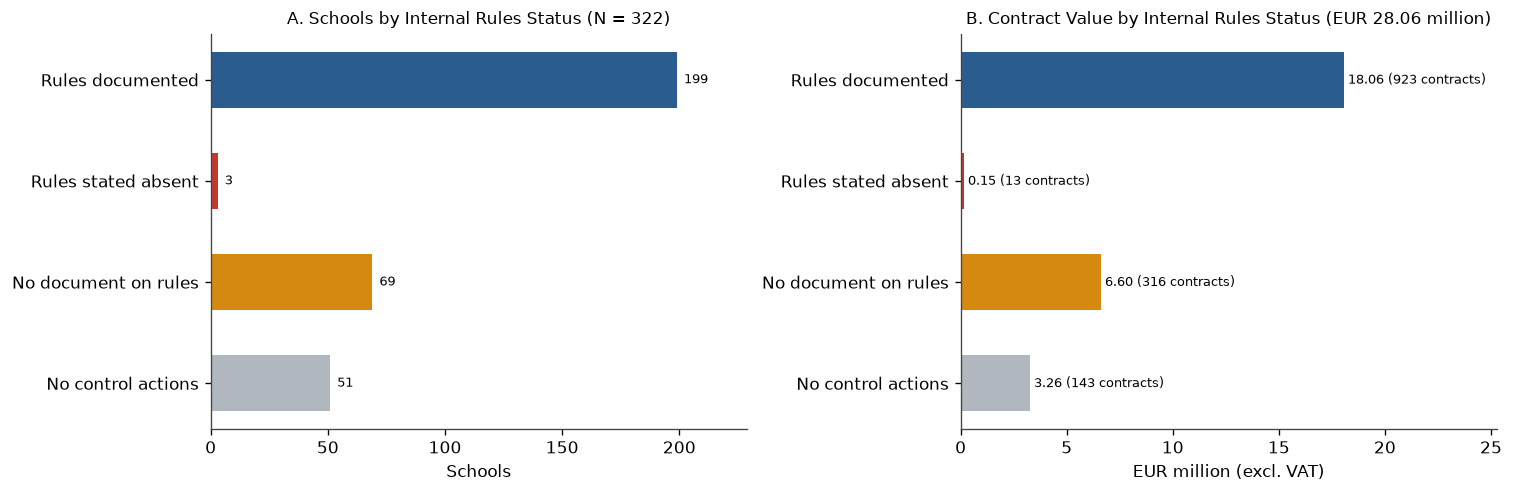

,class_10_03,schools,schools_with_actions,schools_with_contracts,contracts,contracts_without_amount,eur_excl_vat,eur_share
status,,,,,,,,
Rules documented,no,199,199,178,923,112,18056007.03,0.643430
Rules stated absent,yes,3,3,2,13,0,145923.42,0.005200
No document on rules,yes,69,69,66,316,38,6602935.56,0.235297
No control actions,no document,51,0,32,143,12,3257271.00,0.116074


,denominator,k,n,share,wilson_low,wilson_high
0,All schools,72,322,0.223602,0.181504,0.272218
1,Schools with control actions,72,271,0.265683,0.216636,0.321279
2,Schools with contracts,68,278,0.244604,0.197781,0.298390


Internal rules | Rules documented: 199 schools | class_10_03 = ДА: 72 schools (3 rules stated absent, 69 no document on rules), 26.57% of 271 schools with control actions (Wilson 21.66%-32.13%) | 329 contracts, EUR 6,748,858.98 (24.05%) | No control actions: 51 schools, 143 contracts, EUR 3,257,271.00 (11.61%)


In [9]:
assert (schools["internal_rules_doc_id"] == MISSING_MARKER).all() and (schools["internal_rules_page"] == MISSING_MARKER).all()
assert control_actions.groupby("school")["internal_rules_present"].nunique().eq(1).all()

status_specs = [
    ("Rules documented", "ДА", "НЕ"),
    ("Rules stated absent", "НЕ", "ДА"),
    ("No document on rules", MISSING_MARKER, "ДА"),
    ("No control actions", "no control actions", MISSING_MARKER),
]
status_order = [label for label, _, _ in status_specs]
rules_status = schools[["school", "class_10_03"]].assign(
    status=rules_source.map({source: label for label, source, _ in status_specs}),
    has_actions=schools["school"].isin(set(control_actions["school"])),
)
assert rules_status["status"].notna().all()
for label, source, class_value in status_specs:
    assert ((rules_status["status"] == label) == ((rules_source == source) & (schools["class_10_03"] == class_value))).all()

contracts_by_school = contracts.groupby("school").agg(
    contracts=("contract_rec_id", "size"),
    contracts_without_amount=("amount_excl_vat_num", lambda s: int(s.isna().sum())),
    eur_excl_vat=("amount_excl_vat_num", "sum"),
)
rules_status = rules_status.join(contracts_by_school, on="school")
rules_status[["contracts", "contracts_without_amount"]] = rules_status[["contracts", "contracts_without_amount"]].fillna(0).astype(int)
rules_status["eur_excl_vat"] = rules_status["eur_excl_vat"].fillna(0.0)
rules_status["has_contracts"] = rules_status["contracts"] > 0

rules_by_status = (
    rules_status.groupby("status")
    .agg(
        schools=("school", "size"),
        schools_with_actions=("has_actions", "sum"),
        schools_with_contracts=("has_contracts", "sum"),
        contracts=("contracts", "sum"),
        contracts_without_amount=("contracts_without_amount", "sum"),
        eur_excl_vat=("eur_excl_vat", "sum"),
    )
    .reindex(status_order)
)
rules_by_status["eur_excl_vat"] = rules_by_status["eur_excl_vat"].round(2)
rules_by_status["eur_share"] = (rules_by_status["eur_excl_vat"] / total_eur_excl_vat).round(6)
rules_by_status.insert(0, "class_10_03", [class_value for _, _, class_value in status_specs])
count_columns = ["schools", "schools_with_actions", "schools_with_contracts", "contracts", "contracts_without_amount"]
assert rules_by_status[count_columns].values.tolist() == [[199, 199, 178, 923, 112], [3, 3, 2, 13, 0], [69, 69, 66, 316, 38], [51, 0, 32, 143, 12]]
assert rules_by_status["eur_excl_vat"].tolist() == [18056007.03, 145923.42, 6602935.56, 3257271.0]
assert round(float(rules_by_status["eur_excl_vat"].sum()), 2) == total_eur_excl_vat

missing_rules = rules_status["class_10_03"] == "ДА"
denominator_specs = [
    ("All schools", pd.Series(True, index=rules_status.index)),
    ("Schools with control actions", rules_status["has_actions"]),
    ("Schools with contracts", rules_status["has_contracts"]),
]
share_rows = []
for spec, mask in denominator_specs:
    k, n = int((missing_rules & mask).sum()), int(mask.sum())
    p_w, w_lo, w_hi = wilson_ci(k, n)
    share_rows.append({"denominator": spec, "k": k, "n": n, "share": round(p_w, 6), "wilson_low": round(w_lo, 6), "wilson_high": round(w_hi, 6)})
    record_conclusion("Section 5", "internal_rules_10_03", f"class_10_03=ДА | {spec} | share", f"{p_w:.6f}", f"{w_lo:.6f}", f"{w_hi:.6f}", "Wilson")
missing_rules_shares = pd.DataFrame(share_rows)
assert missing_rules_shares[["k", "n"]].values.tolist() == [[72, 322], [72, 271], [68, 278]]

missing_statuses = ["Rules stated absent", "No document on rules"]
missing_contracts = int(rules_by_status.loc[missing_statuses, "contracts"].sum())
missing_eur = round(float(rules_by_status.loc[missing_statuses, "eur_excl_vat"].sum()), 2)
no_actions = rules_by_status.loc["No control actions"]
undocumented_eur = round(missing_eur + float(no_actions["eur_excl_vat"]), 2)
assert (missing_contracts, missing_eur, undocumented_eur) == (329, 6748858.98, 10006129.98)

for status, r in rules_by_status.iterrows():
    record_conclusion("Section 5", "internal_rules_10_03", f"{status} (class_10_03={r['class_10_03']}) | schools / contracts / EUR excl VAT", f"{int(r['schools'])} / {int(r['contracts'])} / {r['eur_excl_vat']:.2f}")
record_conclusion("Section 5", "internal_rules_10_03", "class_10_03=ДА | contracts / EUR excl VAT", f"{missing_contracts} / {missing_eur:.2f}")
record_conclusion("Section 5", "internal_rules_10_03", "class_10_03=ДА or no control actions | EUR excl VAT", f"{undocumented_eur:.2f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.0), constrained_layout=True)
status_colors = ["#2b5c8f", "#c0392b", "#d68910", "#b0b7bf"]
school_counts = rules_by_status["schools"].values
ax1.barh(status_order, school_counts, color=status_colors, height=0.55)
for i, v in enumerate(school_counts):
    ax1.text(v + 3, i, f"{v:,}", va="center", fontsize=8)
ax1.set_xlim(0, school_counts.max() * 1.15)
ax1.set_xlabel("Schools")
ax1.set_title(f"A. Schools by Internal Rules Status (N = {len(schools):,})", fontsize=10)
eur_million = rules_by_status["eur_excl_vat"].values / 1e6
ax2.barh(status_order, eur_million, color=status_colors, height=0.55)
for i, (v, n) in enumerate(zip(eur_million, rules_by_status["contracts"].values)):
    ax2.text(v + 0.2, i, f"{v:.2f} ({n:,} contracts)", va="center", fontsize=8)
ax2.set_xlim(0, eur_million.max() * 1.4)
ax2.set_xlabel("EUR million (excl. VAT)")
ax2.set_title(f"B. Contract Value by Internal Rules Status (EUR {total_eur_excl_vat / 1e6:.2f} million)", fontsize=10)
for ax in (ax1, ax2):
    ax.invert_yaxis()
    ax.spines[["top", "right"]].set_visible(False)
plt.show()
plt.close(fig)

display(en_view(rules_by_status))
display(missing_rules_shares)

ms = missing_rules_shares.set_index("denominator")
print(
    f"Internal rules | Rules documented: {int(rules_by_status.loc['Rules documented', 'schools'])} schools | "
    f"class_10_03 = ДА: {int(missing_rules.sum())} schools ({int(rules_by_status.loc['Rules stated absent', 'schools'])} rules stated absent, "
    f"{int(rules_by_status.loc['No document on rules', 'schools'])} no document on rules), "
    f"{ms.loc['Schools with control actions', 'share']:.2%} of {int(ms.loc['Schools with control actions', 'n'])} schools with control actions "
    f"(Wilson {ms.loc['Schools with control actions', 'wilson_low']:.2%}-{ms.loc['Schools with control actions', 'wilson_high']:.2%}) | "
    f"{missing_contracts} contracts, {fmt_eur(missing_eur)} ({missing_eur / total_eur_excl_vat:.2%}) | "
    f"No control actions: {int(no_actions['schools'])} schools, {int(no_actions['contracts'])} contracts, "
    f"{fmt_eur(float(no_actions['eur_excl_vat']))} ({float(no_actions['eur_excl_vat']) / total_eur_excl_vat:.2%})"
)

**Economic & Financial Control Implication:** Internal rules for ex-ante control are documented in **199 of the 322 schools**, which hold **923 contracts (EUR 18,056,007.03 excl. VAT, 64.34% of the contracted value)**. Class 10.03 applies to **72 schools**: in **3** the checklists state that rules do not exist, and in **69** the checklists hold no document on internal rules. The share of schools without documented rules is **26.57% of the 271 schools with control actions (Wilson 21.66%–32.13%)**, **22.36% of all 322 schools (Wilson 18.15%–27.22%)**, and **24.46% of the 278 schools with contracts (68 schools; Wilson 19.78%–29.84%)**. The share of all 322 schools is a lower bound, because the 51 schools without control actions enter the denominator but not the numerator. The school is the unit of this class, so only the Wilson interval is reported.

The 72 schools to which class 10.03 applies hold **329 contracts (EUR 6,748,858.98, 24.05%)**: 13 contracts (EUR 145,923.42) in the 2 schools with contracts among the 3 that state the absence of rules, and 316 contracts (EUR 6,602,935.56) in 66 of the 69 schools without a document on rules. The **51 schools without control actions** are not counted among the schools without an established procedure, yet 32 of them hold **143 contracts (EUR 3,257,271.00, 11.61%)** for which the corpus documents neither internal rules nor a control action. The EUR figures cover the priced contracts only (291 of the 329 and 131 of the 143 contracts).

The answer to the financial-control question of this section: the procedure for ex-ante control is documented by internal rules in schools that hold EUR 18,056,007.03 (64.34%) of the contracted value; EUR 6,748,858.98 (24.05%) is managed in the 72 schools without documented rules, and with the 51 schools without control actions the value without any document on the procedure for ex-ante control reaches **EUR 10,006,129.98 (35.66%)**. Because the presence of rules rests on the statement in the checklists, the 199 schools show that rules are declared, not that the procedure determined under Art. 13(4) of the FMCPSA is applied (Bulgaria, 2006a).

## 6. Ex-Ante Control under Art. 237b PPA (Indicator 2, Class 10.04)

**Financial-control question:** Under Art. 237b(1) of the PPA, in force from 1 January 2024, the contracting authority ensures ex-ante control of legality for each procurement whose estimated value is at least BGN 5,000,000 (EUR 2,556,459.41 at EUR 1 = BGN 1.95583) or at least 10% of its last approved budget. Under Art. 237b(3), the person exercising this control submits a report on its results within 10 days of receiving the report of the evaluation committee under Art. 103(3) (Bulgaria, 2016a). The guidelines issued under Art. 237b(5) place this control before the contracting authority decides on the award or the termination of the procedure and require the checks to be documented in checklists that form an integral part of this report (Ministry of Finance, 2023). Among the 122 schools with at least one contract that meets this condition, in how many schools does no applicable contract have documented control under Art. 237b (Indicator 2), how many contracts and how much contracted value (EUR excl. VAT) proceed without it, and how much of this value also lacks control before commitment (Indicator 1)?

*Definition:* A contract is applicable (`art_237b_applicable` equals `ДА`) when its date (`contract_date_effective`) is on or after 1 January 2024 and its contracted amount excl. VAT is at least EUR 2,556,459.41 or at least 10% of the budget used for the test (`budget_amount_for_237b_eur`, the budget of the year before the year of the contract). Contracts dated before 1 January 2024 are `неприложимо`, and contracts without an amount carry the missing marker, because the condition cannot be tested. The next cell reproduces this rule for all 1,395 contracts. Class 10.04 (*Unperformed ex-ante control for legality of a procurement above the threshold*, `class_10_04`) equals `ДА` for an applicable contract without documented control under Art. 237b; its value `НЕ` joins contracts without the condition and applicable contracts with control, so class 10.04 is reported descriptively. Indicator 2 is measured for each school: a school counts as without control when none of its applicable contracts has documented control under Art. 237b; schools without an applicable contract stay outside the denominator.

*Methodological limitation:* The thresholds of Art. 237b(1) apply to the **estimated value** of the procurement, whereas the corpus uses the **contracted amount excl. VAT** (`amount_excl_vat`) as a proxy. The budget used for the test is documented (`05_budgets`) for part of the contracts and estimated for the others (standard cost per pupil multiplied by the number of pupils, the nearest available year, or a budget still to be verified; column `budget_source_for_237b`), so the result is also reported for the documented budgets only.

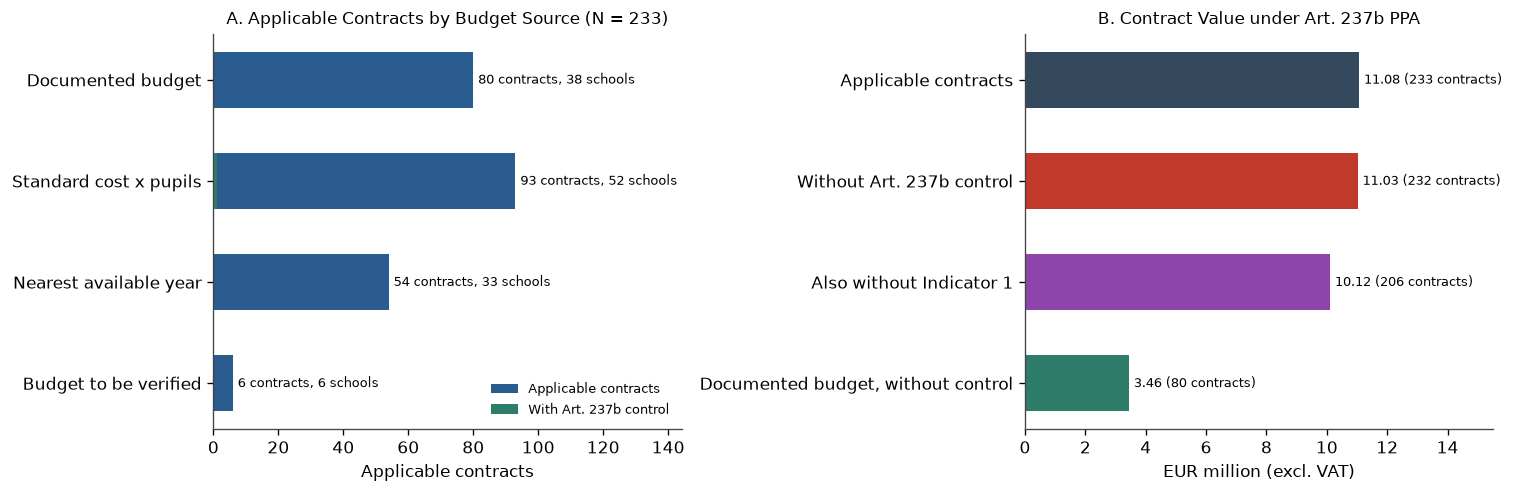

,contracts,applicable_contracts,schools,contracts_without_amount,eur_excl_vat,eur_share
class_10_04,,,,,,
yes,232,232,121,0,11033935.84,0.393197
no,979,1,252,0,16593475.56,0.591312
not applicable,47,0,26,25,434725.61,0.015492
no document,137,0,62,137,0.00,0.000000


,schools,applicable_contracts,without_237b_control,eur_excl_vat
budget_source_group,,,,
Documented budget,38,80,80,3455250.99
Standard cost x pupils,52,93,92,3474037.77
Nearest available year,33,54,54,3809858.96
Budget to be verified,6,6,6,341880.80
All applicable contracts,122,233,232,11081028.52


,k,n,share,wilson_low,wilson_high,bootstrap_low,bootstrap_high
specification,,,,,,,
Main: all schools with an applicable contract,121,122,0.991803,0.955029,0.998552,0.97541,1.0
Documented budget (05_budgets) only,38,38,1.000000,0.908190,1.000000,NaN,NaN
Any Art. 237b report in the school counted as control,115,122,0.942623,0.886291,0.971932,NaN,NaN


Art. 237b PPA | Applicable: 122 schools, 233 contracts, EUR 11,081,028.52 | Indicator 2: 121/122 schools without control (99.18%, Wilson 95.50%-99.86%, school-cluster bootstrap 97.54%-100.00%) | 232 contracts, EUR 11,033,935.84 | Also without Indicator 1: 206 contracts, EUR 10,119,683.21 | Documented budget: 38/38 (Wilson 90.82%-100.00%) | Any report counted: 115/122 (Wilson 88.63%-97.19%)


In [10]:
BGN_5M_EUR = round(5_000_000 / EUR_BGN, 2)
assert BGN_5M_EUR == 2556459.41

class_10_04_order = ["ДА", "НЕ", "неприложимо", MISSING_MARKER]
assert set(contracts["class_10_04"]) == set(class_10_04_order)
assert set(contracts["art_237b_applicable"]) == set(class_10_04_order)
contract_date_eff = pd.to_datetime(contracts["contract_date_effective"], errors="raise")
budget_for_237b = pd.to_numeric(contracts["budget_amount_for_237b_eur"], errors="coerce")
applicability_rule = np.select(
    [
        contract_date_eff < "2024-01-01",
        contracts["amount_excl_vat_num"].isna(),
        (contracts["amount_excl_vat_num"] >= BGN_5M_EUR) | (contracts["amount_excl_vat_num"] >= 0.10 * budget_for_237b),
    ],
    ["неприложимо", MISSING_MARKER, "ДА"],
    default="НЕ",
)
assert (applicability_rule == contracts["art_237b_applicable"].values).all()
assert pd.crosstab(contracts["class_10_04"], contracts["art_237b_applicable"]).reindex(index=class_10_04_order, columns=class_10_04_order, fill_value=0).values.tolist() == [
    [232, 0, 0, 0], [1, 978, 0, 0], [0, 0, 47, 0], [0, 0, 0, 137]
]

class_10_04_by_value = (
    contracts.assign(applicable=contracts["art_237b_applicable"] == "ДА")
    .groupby("class_10_04")
    .agg(
        contracts=("contract_rec_id", "size"),
        applicable_contracts=("applicable", "sum"),
        schools=("school", "nunique"),
        contracts_without_amount=("amount_excl_vat_num", lambda s: int(s.isna().sum())),
        eur_excl_vat=("amount_excl_vat_num", "sum"),
    )
    .reindex(class_10_04_order)
)
class_10_04_by_value["eur_excl_vat"] = class_10_04_by_value["eur_excl_vat"].round(2)
class_10_04_by_value["eur_share"] = (class_10_04_by_value["eur_excl_vat"] / total_eur_excl_vat).round(6)
assert class_10_04_by_value[["contracts", "applicable_contracts", "schools", "contracts_without_amount"]].values.tolist() == [
    [232, 232, 121, 0], [979, 1, 252, 0], [47, 0, 26, 25], [137, 0, 62, 137]
]
assert class_10_04_by_value["eur_excl_vat"].tolist() == [11033935.84, 16593475.56, 434725.61, 0.0]
assert round(float(class_10_04_by_value["eur_excl_vat"].sum()), 2) == total_eur_excl_vat

app_df = contracts[contracts["art_237b_applicable"] == "ДА"].copy()
app_df["budget_ratio"] = app_df["amount_excl_vat_num"] / budget_for_237b[app_df.index]
app_df["no_237b_control"] = app_df["class_10_04"] == "ДА"
app_eur_total = round(float(app_df["amount_excl_vat_num"].sum()), 2)
assert (len(app_df), int(app_df["school"].nunique()), app_eur_total) == (233, 122, 11081028.52)
assert int(app_df["amount_excl_vat_num"].isna().sum()) == 0
assert int((app_df["amount_excl_vat_num"] >= BGN_5M_EUR).sum()) == 0 and round(float(app_df["budget_ratio"].min()), 4) == 0.1004
assert contract_date_eff[app_df.index].min() >= pd.Timestamp("2024-03-11")

school_ind2 = app_df.groupby("school").agg(
    applicable_contracts=("contract_rec_id", "size"),
    without_237b_control=("no_237b_control", "sum"),
    eur_excl_vat=("amount_excl_vat_num", "sum"),
)
school_ind2["no_237b_control_in_school"] = (school_ind2["without_237b_control"] == school_ind2["applicable_contracts"]).astype(int)
k_ind2, n_ind2 = int(school_ind2["no_237b_control_in_school"].sum()), len(school_ind2)
assert (k_ind2, n_ind2) == (121, 122)
p_ind2, w_ind2_lo, w_ind2_hi = wilson_ci(k_ind2, n_ind2)
_, b_ind2_lo, b_ind2_hi = cluster_bootstrap_ci(school_ind2.index.values, school_ind2["no_237b_control_in_school"].values)

no_ctrl_df = app_df[app_df["no_237b_control"]]
no_ctrl_eur = round(float(no_ctrl_df["amount_excl_vat_num"].sum()), 2)
both_missing_df = no_ctrl_df[no_ctrl_df["class_10_01"] == "ДА"]
both_missing_eur = round(float(both_missing_df["amount_excl_vat_num"].sum()), 2)
controlled_df = app_df[~app_df["no_237b_control"]]
assert (len(no_ctrl_df), no_ctrl_eur, len(both_missing_df), both_missing_eur) == (232, 11033935.84, 206, 10119683.21)
assert (len(controlled_df), round(float(controlled_df["amount_excl_vat_num"].sum()), 2), controlled_df["class_10_01"].tolist()) == (1, 47092.68, ["ДА"])

ca_237b = control_actions[control_actions["control_type"] == "чл_237б_ЗОП"]
linked_237b = ca_237b[ca_237b["contract_rec_id"] != MISSING_MARKER]
assert len(ca_237b) == 18 and (ca_237b["checklist_present"] == MISSING_MARKER).all() and (ca_237b["art_237b_report_present"] == "ДА").all()
assert (control_actions.loc[control_actions["control_type"] != "чл_237б_ЗОП", "art_237b_report_present"] != "ДА").all()
assert (len(linked_237b), int(linked_237b["contract_rec_id"].nunique()), int(ca_237b["school"].nunique())) == (6, 4, 13)
linked_contracts = contracts.set_index("contract_rec_id").loc[linked_237b["contract_rec_id"].unique(), ["art_237b_applicable", "class_10_04"]]
assert sorted(linked_contracts["art_237b_applicable"].tolist()) == ["ДА", "НЕ", "НЕ", MISSING_MARKER]
report_schools = set(ca_237b["school"])
report_unmatched = school_ind2[school_ind2.index.isin(report_schools) & (school_ind2["no_237b_control_in_school"] == 1)]
report_unmatched_eur = round(float(report_unmatched["eur_excl_vat"].sum()), 2)
k_rep = k_ind2 - len(report_unmatched)
assert (int(school_ind2.index.isin(report_schools).sum()), len(report_unmatched), int(report_unmatched["applicable_contracts"].sum()), k_rep) == (7, 6, 9, 115)
p_rep, w_rep_lo, w_rep_hi = wilson_ci(k_rep, n_ind2)


def budget_source_group(source: str) -> str:
    if source == "05_budgets":
        return "Documented budget"
    if source.startswith("стандарт_"):
        return "Standard cost x pupils"
    if source.startswith("най_близка_година_"):
        return "Nearest available year"
    if source == "budgets_to_verify":
        return "Budget to be verified"
    raise ValueError(source)


budget_order = ["Documented budget", "Standard cost x pupils", "Nearest available year", "Budget to be verified"]
app_df["budget_source_group"] = app_df["budget_source_for_237b"].map(budget_source_group)
ind2_by_budget_source = (
    app_df.groupby("budget_source_group")
    .agg(
        schools=("school", "nunique"),
        applicable_contracts=("contract_rec_id", "size"),
        without_237b_control=("no_237b_control", "sum"),
        eur_excl_vat=("amount_excl_vat_num", "sum"),
    )
    .reindex(budget_order)
)
ind2_by_budget_source.loc["All applicable contracts"] = [n_ind2, len(app_df), len(no_ctrl_df), app_eur_total]
ind2_by_budget_source = ind2_by_budget_source.astype({"schools": int, "applicable_contracts": int, "without_237b_control": int})
ind2_by_budget_source["eur_excl_vat"] = ind2_by_budget_source["eur_excl_vat"].round(2)
assert ind2_by_budget_source[["schools", "applicable_contracts", "without_237b_control"]].values.tolist() == [
    [38, 80, 80], [52, 93, 92], [33, 54, 54], [6, 6, 6], [122, 233, 232]
]
assert ind2_by_budget_source["eur_excl_vat"].tolist() == [3455250.99, 3474037.77, 3809858.96, 341880.80, 11081028.52]
mixed_source_schools = int((app_df.groupby("school")["budget_source_group"].nunique() > 1).sum())
assert mixed_source_schools == 7

doc_df = app_df[app_df["budget_source_group"] == "Documented budget"]
doc_schools = doc_df.groupby("school")["no_237b_control"].all()
k_doc, n_doc = int(doc_schools.sum()), len(doc_schools)
assert (k_doc, n_doc) == (38, 38)
p_doc, w_doc_lo, w_doc_hi = wilson_ci(k_doc, n_doc)

ind2_shares = pd.DataFrame(
    [
        {"specification": "Main: all schools with an applicable contract", "k": k_ind2, "n": n_ind2, "share": round(p_ind2, 6),
         "wilson_low": round(w_ind2_lo, 6), "wilson_high": round(w_ind2_hi, 6), "bootstrap_low": round(b_ind2_lo, 6), "bootstrap_high": round(b_ind2_hi, 6)},
        {"specification": "Documented budget (05_budgets) only", "k": k_doc, "n": n_doc, "share": round(p_doc, 6),
         "wilson_low": round(w_doc_lo, 6), "wilson_high": round(w_doc_hi, 6), "bootstrap_low": np.nan, "bootstrap_high": np.nan},
        {"specification": "Any Art. 237b report in the school counted as control", "k": k_rep, "n": n_ind2, "share": round(p_rep, 6),
         "wilson_low": round(w_rep_lo, 6), "wilson_high": round(w_rep_hi, 6), "bootstrap_low": np.nan, "bootstrap_high": np.nan},
    ]
).set_index("specification")

record_conclusion("Section 6", "art_237b_10_04", "applicable schools / contracts / EUR excl VAT", f"{n_ind2} / {len(app_df)} / {app_eur_total:.2f}")
for value, r in class_10_04_by_value.iterrows():
    record_conclusion("Section 6", "art_237b_10_04", f"class_10_04={value} | contracts / schools / EUR excl VAT", f"{int(r['contracts'])} / {int(r['schools'])} / {r['eur_excl_vat']:.2f}")
record_conclusion("Section 6", "art_237b_10_04", "Indicator 2 | schools without Art. 237b control | share", f"{p_ind2:.6f}", f"{w_ind2_lo:.6f}/{b_ind2_lo:.6f}", f"{w_ind2_hi:.6f}/{b_ind2_hi:.6f}", "Wilson/SchoolClusterBootstrap")
record_conclusion("Section 6", "art_237b_10_04", "Indicator 2 | contracts / EUR excl VAT without Art. 237b control", f"{len(no_ctrl_df)} / {no_ctrl_eur:.2f}")
record_conclusion("Section 6", "art_237b_10_04", "Indicator 2 and Indicator 1 both missing | contracts / EUR excl VAT", f"{len(both_missing_df)} / {both_missing_eur:.2f}")
for source, r in ind2_by_budget_source.iterrows():
    record_conclusion("Section 6", "art_237b_10_04", f"budget source: {source} | schools / applicable contracts / without control / EUR excl VAT", f"{int(r['schools'])} / {int(r['applicable_contracts'])} / {int(r['without_237b_control'])} / {r['eur_excl_vat']:.2f}")
record_conclusion("Section 6", "art_237b_10_04", "Indicator 2 | documented budget only | share", f"{p_doc:.6f}", f"{w_doc_lo:.6f}", f"{w_doc_hi:.6f}", "Wilson")
record_conclusion("Section 6", "art_237b_10_04", "Indicator 2 | any Art. 237b report counted as control | share", f"{p_rep:.6f}", f"{w_rep_lo:.6f}", f"{w_rep_hi:.6f}", "Wilson")
record_conclusion("Section 6", "art_237b_10_04", "Art. 237b reports | actions / linked / schools / checklists", f"{len(ca_237b)} / {len(linked_237b)} / {len(report_schools)} / 0")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.0), constrained_layout=True)
src = ind2_by_budget_source.loc[budget_order]
ax1.barh(budget_order, src["applicable_contracts"], color="#2b5c8f", height=0.55, label="Applicable contracts")
ax1.barh(budget_order, src["applicable_contracts"] - src["without_237b_control"], color="#2e7d6b", height=0.55, label="With Art. 237b control")
for i, (n, sc) in enumerate(zip(src["applicable_contracts"], src["schools"])):
    ax1.text(n + 1.5, i, f"{n} contracts, {sc} schools", va="center", fontsize=8)
ax1.set_xlim(0, src["applicable_contracts"].max() * 1.55)
ax1.set_xlabel("Applicable contracts")
ax1.set_title(f"A. Applicable Contracts by Budget Source (N = {len(app_df)})", fontsize=10)
ax1.legend(fontsize=8, loc="lower right", frameon=False)
exposure_labels = ["Applicable contracts", "Without Art. 237b control", "Also without Indicator 1", "Documented budget, without control"]
exposure_eur = [app_eur_total, no_ctrl_eur, both_missing_eur, float(src.loc["Documented budget", "eur_excl_vat"])]
exposure_n = [len(app_df), len(no_ctrl_df), len(both_missing_df), int(src.loc["Documented budget", "applicable_contracts"])]
ax2.barh(exposure_labels, [v / 1e6 for v in exposure_eur], color=["#34495e", "#c0392b", "#8e44ad", "#2e7d6b"], height=0.55)
for i, (v, n) in enumerate(zip(exposure_eur, exposure_n)):
    ax2.text(v / 1e6 + 0.15, i, f"{v / 1e6:.2f} ({n} contracts)", va="center", fontsize=8)
ax2.set_xlim(0, app_eur_total / 1e6 * 1.4)
ax2.set_xlabel("EUR million (excl. VAT)")
ax2.set_title("B. Contract Value under Art. 237b PPA", fontsize=10)
for ax in (ax1, ax2):
    ax.invert_yaxis()
    ax.spines[["top", "right"]].set_visible(False)
save_fig_300(fig, "F5_art237b_ex_ante_control.png")
plt.show()
plt.close(fig)

terms_237b = {**TERMS_EN, "неприложимо": "not applicable"}
display(en_view(class_10_04_by_value, terms_237b))
display(ind2_by_budget_source)
display(ind2_shares)

print(
    f"Art. 237b PPA | Applicable: {n_ind2} schools, {len(app_df)} contracts, {fmt_eur(app_eur_total)} | "
    f"Indicator 2: {k_ind2}/{n_ind2} schools without control ({p_ind2:.2%}, Wilson {w_ind2_lo:.2%}-{w_ind2_hi:.2%}, "
    f"school-cluster bootstrap {b_ind2_lo:.2%}-{b_ind2_hi:.2%}) | {len(no_ctrl_df)} contracts, {fmt_eur(no_ctrl_eur)} | "
    f"Also without Indicator 1: {len(both_missing_df)} contracts, {fmt_eur(both_missing_eur)} | "
    f"Documented budget: {k_doc}/{n_doc} (Wilson {w_doc_lo:.2%}-{w_doc_hi:.2%}) | "
    f"Any report counted: {k_rep}/{n_ind2} (Wilson {w_rep_lo:.2%}-{w_rep_hi:.2%})"
)

**Economic & Financial Control Implication:** The condition of Art. 237b(1) is met by **233 contracts of 122 schools (EUR 11,081,028.52 excl. VAT, 39.49% of the contracted value)**. No contract reaches BGN 5,000,000, so every applicable contract meets the condition through the 10% budget criterion (lowest ratio 10.04%). Class 10.04 is distributed as follows: `ДА` for 232 contracts of 121 schools (EUR 11,033,935.84, 39.32%); `НЕ` for 979 contracts (978 without the condition and 1 applicable contract with control; EUR 16,593,475.56); `неприложимо` for 47 contracts dated in 2023 (EUR 434,725.61; 25 without an amount); and the missing marker for 137 contracts without an amount, for which the condition cannot be tested.

Under Indicator 2, in **121 of the 122 schools (99.18%; Wilson 95.50%–99.86%, school-cluster bootstrap 97.54%–100.00%)** no applicable contract has documented control under Art. 237b. These schools hold **232 of the 233 applicable contracts (EUR 11,033,935.84)**. Of them, **206 (EUR 10,119,683.21, 36.06% of the contracted value)** also lack control before commitment (Indicator 1), and 26 (EUR 914,252.63) have it. The only applicable contract with control under Art. 237b (EUR 47,092.68) has no control before commitment. The school is the unit of Indicator 2, so the school-cluster bootstrap resamples single schools (Wilson, 1927; Efron and Tibshirani, 1994).

The documented budget (`05_budgets`) supports the condition for **80 contracts of 38 schools (EUR 3,455,250.99)**, and all **38 of these schools** are without control (100%; Wilson 90.82%–100.00%). Estimated budgets support the condition for 93 contracts of 52 schools (standard cost per pupil, EUR 3,474,037.77), 54 contracts of 33 schools (nearest available year, EUR 3,809,858.96), and 6 contracts of 6 schools (budget to be verified, EUR 341,880.80). Seven schools hold applicable contracts with two budget sources, so the school counts by source do not add up to 122. Because the thresholds apply to the estimated value, a procurement with an estimated value above the threshold and a lower contracted amount stays outside the 233 contracts, and a contract above the threshold with a lower estimated value is included.

The corpus holds **18 actions under Art. 237b in 13 schools**. All 18 record a report (`art_237b_report_present` equals `ДА`) and none has a checklist, although the guidelines require the checklists to form an integral part of the report (Ministry of Finance, 2023). Only 6 actions name a contract (4 contracts, 1 of them applicable). Seven of the 122 schools hold such a report; in 6 of them the report is not linked to an applicable contract (9 applicable contracts, EUR 596,839.39). If every report in a school is counted as control of all its applicable contracts, the share of schools without control falls to **115 of 122 (94.26%; Wilson 88.63%–97.19%)**, which is the lower bound of Indicator 2.

The answer to the financial-control question of this section: control under Art. 237b, the mandatory review of the work of the evaluation committee for procurements material to the school budget, is documented for 1 of the 233 applicable contracts; **EUR 11,033,935.84 (39.32% of the contracted value)** proceeds without it, and **EUR 10,119,683.21 (36.06%)** proceeds without both Indicator 2 and Indicator 1. The result holds for the documented budgets (38 of 38 schools) and when every report is counted as control (115 of 122 schools).

## 7. Direct Awards and Possible Splitting of Purchases under Art. 20(4) PPA

**Financial-control question:** A contracting authority may award a contract directly, without an announcement or a competitive procedure, only when its estimated value is below BGN 80,000 for construction works and BGN 50,000 for supplies and services other than those listed in Annex No. 2 (as amended by State Gazette No. 88 of 2023, in force from 1 January 2024). A procurement may not be split into parts so that the rules for lower values apply, except for certain lots of limited value under Art. 21(6) (Bulgaria, 2016a). How many direct awards of the schools show signs of such splitting, how many reach the threshold on their own, and what is their value (EUR excl. VAT)?

**How each contract is assessed:** For every contract, the school's contracts in the same subject group (equipment, furniture, construction works, software, services / ineligible) are added up over the 12 months up to its date, including the contract itself and both STEM project and other contracts. Each contract then falls into one of five groups:

| Group | Meaning |
|---|---|
| **Possible splitting** | A direct award that is below the threshold on its own, while the 12-month total reaches the threshold |
| **Direct award at or above the threshold** | A direct award whose own value already reaches the threshold |
| **Direct award within limits** | A direct award where neither the contract nor the 12-month total reaches the threshold |
| **Other procedure** | The contract was not awarded directly under Art. 20(4), so the test does not apply |
| **Cannot be assessed** | The amount or the legal basis of the award is not documented |

*Illustration (hypothetical):* A school buys equipment directly for EUR 20,000 and has bought equipment for EUR 10,000 in the preceding 12 months. The contract is below the threshold of EUR 25,564.59, but the total of EUR 30,000 exceeds it. The contract is marked as possible splitting.

*Thresholds applied:* For contracts dated from 1 January 2024: EUR 40,903.35 (BGN 80,000) for construction works and EUR 25,564.59 (BGN 50,000) for the other groups. For contracts dated in 2023: EUR 25,564.59 (BGN 50,000) and EUR 15,338.76 (BGN 30,000). The next cell reproduces the thresholds and the assessment for all 1,395 contracts. Shares are reported with Wilson intervals and with a bootstrap that resamples whole schools.

*Methodological limitation:* The law applies the thresholds to the **estimated value**, including the 12-month basis for regular supplies and services under Art. 21(8), whereas the data contain the **contracted amount excl. VAT**, used here as a proxy. The subject group, not the type stated in the procurement document, determines the threshold. The separate threshold for the services in Annex No. 2 (BGN 100,000) is not applied. By CPV code, 20 contracts fall under this annex (18 for legal services, 2 for training): 18 cannot be assessed and the other 2 are not marked. As 482 contracts have no readable CPV code, further such services cannot be ruled out. Awards within 12 months are not splitting when they concern construction, or design and construction, or an identical or similar subject that was not known when the previous award started (Art. 21(16)) (Bulgaria, 2016a). These circumstances are not documented in the data. A mark is therefore a signal for verification, not an established violation.

*Data fields:* `class_1_01` (possible splitting), `class_1_02` (direct award at or above the threshold), `prev_12m_group_sum_eur` (12-month total), `art20_threshold_eur` (threshold), `cpv_group_3` (subject group), `zop_basis_norm` (legal basis).

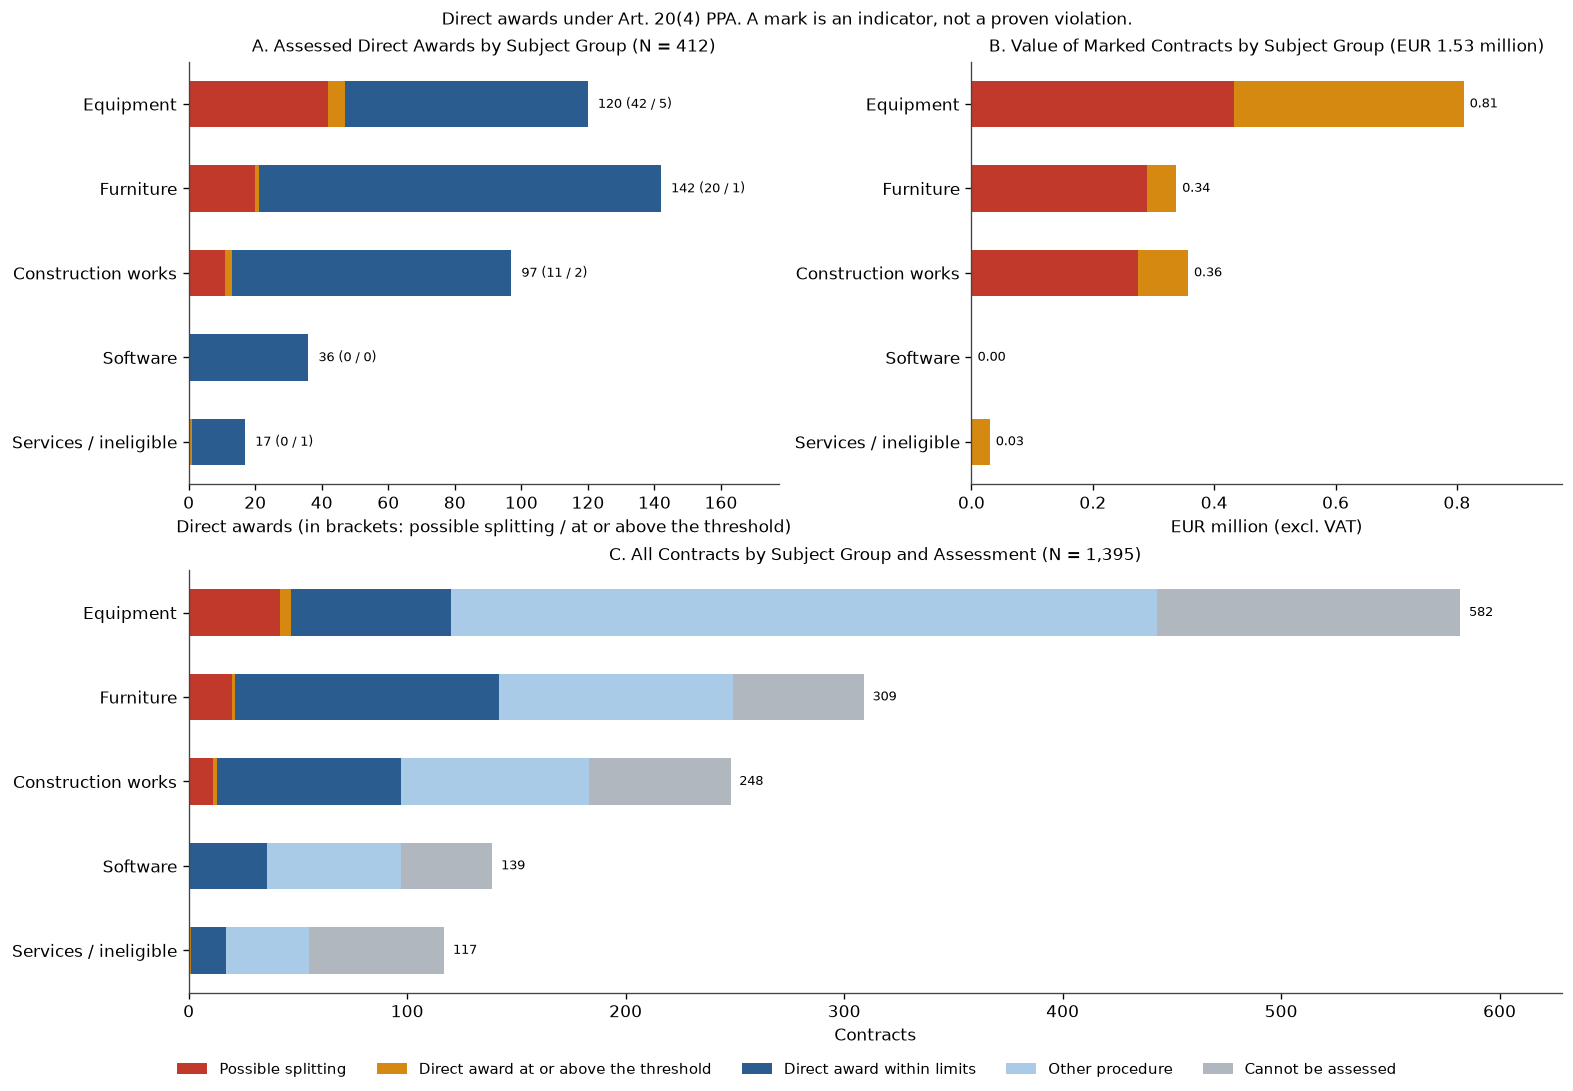

,contracts,schools,direct_awards,contracts_without_amount,eur_excl_vat,eur_share
assessment,,,,,,
Possible splitting,73,52,73,0,997248.14,0.035537
Direct award at or above the threshold,9,8,9,0,537559.86,0.019156
Direct award within limits,330,180,330,0,3601365.40,0.128335
Other procedure,615,236,0,0,19663385.87,0.700709
Cannot be assessed,368,157,18,162,3262577.74,0.116263


k  \
assessment                             denominator                                   
Possible splitting                     All assessed contracts                   73   
                                       Assessed direct awards under Art. 20(4)  73   
Direct award at or above the threshold All assessed contracts                    9   
                                       Assessed direct awards under Art. 20(4)   9   

                                                                                   n  \
assessment                             denominator                                     
Possible splitting                     All assessed contracts                   1027   
                                       Assessed direct awards under Art. 20(4)   412   
Direct award at or above the threshold All assessed contracts                   1027   
                                       Assessed direct awards under Art. 20(4)   412   

                                                                                schools  \
assessment                             denominator                                        
Possible splitting                     All assessed contracts                       268   
                                       Assessed direct awards under Art. 20(4)      193   
Direct award at or above the threshold All assessed contracts                       268   
                                       Assessed direct awards under Art. 20(4)      193   

                                                                                   share  \
assessment                             denominator                                         
Possible splitting                     All assessed contracts                   0.071081   
                                       Assessed direct awards under Art. 20(4)  0.177184   
Direct award at or above the threshold All assessed contracts                   0.008763   
                                       Assessed direct awards under Art. 20(4)  0.021845   

                                                                                wilson_low  \
assessment                             denominator                                           
Possible splitting                     All assessed contracts                     0.056912   
                                       Assessed direct awards under Art. 20(4)    0.143347   
Direct award at or above the threshold All assessed contracts                     0.004617   
                                       Assessed direct awards under Art. 20(4)    0.011534   

                                                                                wilson_high  \
assessment                             denominator                                            
Possible splitting                     All assessed contracts                      0.088447   
                                       Assessed direct awards under Art. 20(4)     0.216986   
Direct award at or above the threshold All assessed contracts                      0.016571   
                                       Assessed direct awards under Art. 20(4)     0.040989   

                                                                                bootstrap_low  \
assessment                             denominator                                              
Possible splitting                     All assessed contracts                        0.053403   
                                       Assessed direct awards under Art. 20(4)       0.136816   
Direct award at or above the threshold All assessed contracts                        0.003027   
                                       Assessed direct awards under Art. 20(4)       0.007500   

                                                                                bootstrap_high  
assessment                             denominator                                              
Possible splitting    

,contracts,schools,contracts_without_amount,eur_excl_vat,assessed,possible_splitting,eur_possible_splitting,at_or_above_threshold,eur_at_or_above_threshold
subject_group,,,,,,,,,
equipment,582,239,67,15588384.43,443,42,432523.54,5,378449.49
furniture,309,195,18,4090249.32,249,20,289804.63,1,47376.89
construction works,248,179,19,6109711.06,183,11,274919.97,2,81733.48
software,139,100,15,1278013.11,97,0,0.00,0,0.00
services / ineligible,117,59,43,995779.09,55,0,0.00,1,30000.00


,contracts,assessed,possible_splitting,eur_possible_splitting,at_or_above_threshold,eur_at_or_above_threshold
segment,,,,,,
STEM project (yes),1226,1003,71,942770.80,6,240198.70
Non-STEM (no),13,1,0,0.00,0,0.00
Unconfirmed,156,23,2,54477.34,3,297361.16


,contracts,schools,contracts_without_amount,eur_excl_vat,with_possible_splitting,with_at_or_above_threshold
description,,,,,,
Invitation to a single supplier,4,3,0,177029.11,0,0
CPV division vs procurement type,36,32,1,1456355.11,3,2
CPV ineligible under BG-RRP-1.015,83,45,37,145182.96,0,1


Art. 20(4) PPA | Possible splitting: 73 contracts, 52 schools, EUR 997,248.14 (17.72% of 412 direct awards, Wilson 14.33%-21.70%) | 12-month totals: 57 school-group pairs, EUR 4,949,738.80 | Direct award at or above the threshold: 9 contracts, 8 schools, EUR 537,559.86 | Within limits: 330 | Other procedure: 615 | Cannot be assessed: 368 contracts | Related warning signs: single invite 4, CPV mismatch 36, CPV ineligible 83


In [11]:
class_1_order = ["ДА", "НЕ", MISSING_MARKER]
group_order = ["оборудване", "обзавеждане", "СМР", "софтуер", "услуги/недопустимо"]
assert set(contracts["class_1_01"]) == set(class_1_order) and set(contracts["class_1_02"]) == set(class_1_order)
assert contracts["cpv_group_3"].value_counts().reindex(group_order).tolist() == [582, 309, 248, 139, 117]

contract_date_eff = pd.to_datetime(contracts["contract_date_effective"], errors="raise")
prev_12m_eur = pd.to_numeric(contracts["prev_12m_group_sum_eur"], errors="coerce")
art20_threshold = contracts["art20_threshold_eur"].astype(float)
assert (prev_12m_eur.isna() == contracts["amount_excl_vat_num"].isna()).all() and int(prev_12m_eur.notna().sum()) == 1233
assert (prev_12m_eur >= contracts["amount_excl_vat_num"] - 0.005).sum() == 1233

works = contracts["cpv_group_3"] == "СМР"
before_2024 = contract_date_eff < "2024-01-01"
threshold_bgn = np.where(before_2024, np.where(works, 50_000, 30_000), np.where(works, 80_000, 50_000))
assert (np.round(threshold_bgn / EUR_BGN, 2) == art20_threshold.values).all()
assert art20_threshold.value_counts().sort_index().to_dict() == {15338.76: 37, 25564.59: 1120, 40903.35: 238}

direct_award = contracts["zop_basis_norm"].str.startswith("чл20_ал4")
undeterminable = contracts["amount_excl_vat_num"].isna() | (contracts["zop_basis_norm"] == MISSING_MARKER)
below_single = contracts["amount_excl_vat_num"] < art20_threshold
rule_1_01 = np.where(undeterminable, MISSING_MARKER, np.where(direct_award & below_single & (prev_12m_eur >= art20_threshold), "ДА", "НЕ"))
rule_1_02 = np.where(undeterminable, MISSING_MARKER, np.where(direct_award & ~below_single, "ДА", "НЕ"))
assert (rule_1_01 == contracts["class_1_01"].values).all() and (rule_1_02 == contracts["class_1_02"].values).all()
assert int(((contracts["class_1_01"] == "ДА") & (contracts["class_1_02"] == "ДА")).sum()) == 0
assert (int(contracts["amount_excl_vat_num"].isna().sum()), int((contracts["amount_excl_vat_num"].notna() & (contracts["zop_basis_norm"] == MISSING_MARKER)).sum())) == (162, 206)

class_1_rows = []
for cls in ["class_1_01", "class_1_02"]:
    for value in class_1_order:
        sub = contracts[contracts[cls] == value]
        class_1_rows.append({
            "class": cls, "value": value, "contracts": len(sub), "schools": int(sub["school"].nunique()),
            "direct_award_contracts": int(direct_award[sub.index].sum()),
            "contracts_without_amount": int(sub["amount_excl_vat_num"].isna().sum()),
            "eur_excl_vat": round(float(sub["amount_excl_vat_num"].sum()), 2),
        })
class_1_by_value = pd.DataFrame(class_1_rows).set_index(["class", "value"])
class_1_by_value["eur_share"] = (class_1_by_value["eur_excl_vat"] / total_eur_excl_vat).round(6)
assert class_1_by_value[["contracts", "schools", "direct_award_contracts", "contracts_without_amount"]].values.tolist() == [
    [73, 52, 73, 0], [954, 268, 339, 0], [368, 157, 18, 162], [9, 8, 9, 0], [1018, 268, 403, 0], [368, 157, 18, 162]
]
assert class_1_by_value["eur_excl_vat"].tolist() == [997248.14, 23802311.13, 3262577.74, 537559.86, 24261999.41, 3262577.74]

determinable = contracts["class_1_01"] != MISSING_MARKER
share_rows = []
assessment_names = {"class_1_01": "Possible splitting", "class_1_02": "Direct award at or above the threshold"}
spec_all = "All assessed contracts"
spec_direct = "Assessed direct awards under Art. 20(4)"
for cls, name in assessment_names.items():
    for spec, mask in [(spec_all, determinable), (spec_direct, determinable & direct_award)]:
        sub = contracts[mask]
        flag = (sub[cls] == "ДА").astype(int)
        p_w, w_lo, w_hi = wilson_ci(int(flag.sum()), len(sub))
        _, b_lo, b_hi = cluster_bootstrap_ci(sub["school"].values, flag.values)
        share_rows.append({"assessment": name, "denominator": spec, "k": int(flag.sum()), "n": len(sub), "schools": int(sub["school"].nunique()), "share": round(p_w, 6),
                           "wilson_low": round(w_lo, 6), "wilson_high": round(w_hi, 6), "bootstrap_low": round(b_lo, 6), "bootstrap_high": round(b_hi, 6)})
        record_conclusion("Section 7", "cpv_accumulation_1_01_1_02", f"{name} | {spec} | share", f"{p_w:.6f}", f"{w_lo:.6f}/{b_lo:.6f}", f"{w_hi:.6f}/{b_hi:.6f}", "Wilson/SchoolClusterBootstrap")
class_1_shares = pd.DataFrame(share_rows).set_index(["assessment", "denominator"])
assert class_1_shares[["k", "n", "schools"]].values.tolist() == [[73, 1027, 268], [73, 412, 193], [9, 1027, 268], [9, 412, 193]]

split_df = contracts[contracts["class_1_01"] == "ДА"].assign(prev_12m_eur=prev_12m_eur, threshold_eur=art20_threshold)
split_pairs = split_df.groupby(["school", "cpv_group_3"])["prev_12m_eur"].max()
split_eur = round(float(split_df["amount_excl_vat_num"].sum()), 2)
split_pairs_eur = round(float(split_pairs.sum()), 2)
split_ratio_median = round(float((split_df["prev_12m_eur"] / split_df["threshold_eur"]).median()), 4)
assert (len(split_df), int(split_df["school"].nunique()), len(split_pairs), split_eur, split_pairs_eur, split_ratio_median) == (73, 52, 57, 997248.14, 4949738.80, 1.7298)
assert split_df["cpv_group_3"].value_counts().reindex(group_order, fill_value=0).tolist() == [42, 20, 11, 0, 0]
assert contract_date_eff[split_df.index].dt.year.value_counts().sort_index().to_dict() == {2024: 20, 2025: 35, 2026: 18}

direct_above_df = contracts[contracts["class_1_02"] == "ДА"]
direct_above_eur = round(float(direct_above_df["amount_excl_vat_num"].sum()), 2)
works_doc = direct_above_df[(direct_above_df["doc_procurement_type"] == "СМР") & (direct_above_df["cpv_group_3"] != "СМР")]
works_doc_threshold = round(80_000 / EUR_BGN, 2)
assert (len(direct_above_df), int(direct_above_df["school"].nunique()), direct_above_eur) == (9, 8, 537559.86)
assert (len(works_doc), int(works_doc["school"].nunique()), works_doc["amount_excl_vat_num"].round(2).tolist(), works_doc_threshold) == (2, 1, [40443.19, 40443.19], 40903.35)
assert (works_doc["amount_excl_vat_num"] < works_doc_threshold).all() and (contract_date_eff[works_doc.index] >= "2024-01-01").all()

eitherflag = (contracts["class_1_01"] == "ДА") | (contracts["class_1_02"] == "ДА")
either_eur = round(float(contracts.loc[eitherflag, "amount_excl_vat_num"].sum()), 2)
assert (int(eitherflag.sum()), int(contracts.loc[eitherflag, "school"].nunique()), either_eur) == (82, 57, 1534808.00)

assessment_order = ["Possible splitting", "Direct award at or above the threshold", "Direct award within limits", "Other procedure", "Cannot be assessed"]
assessment = pd.Series(np.select(
    [contracts["class_1_01"] == "ДА", contracts["class_1_02"] == "ДА", determinable & direct_award, determinable & ~direct_award, ~determinable],
    assessment_order, default=""), index=contracts.index)
assessment_table = (
    contracts.assign(assessment=assessment, direct=direct_award)
    .groupby("assessment")
    .agg(
        contracts=("contract_rec_id", "size"), schools=("school", "nunique"), direct_awards=("direct", "sum"),
        contracts_without_amount=("amount_excl_vat_num", lambda s: int(s.isna().sum())),
        eur_excl_vat=("amount_excl_vat_num", "sum"),
    )
    .reindex(assessment_order)
)
assessment_table["eur_excl_vat"] = assessment_table["eur_excl_vat"].round(2)
assessment_table["eur_share"] = (assessment_table["eur_excl_vat"] / total_eur_excl_vat).round(6)
assert assessment_table["contracts"].tolist() == [73, 9, 330, 615, 368]
assert assessment_table["direct_awards"].tolist() == [73, 9, 330, 0, 18] and int(direct_award.sum()) == 430
assert round(float(assessment_table["eur_excl_vat"].sum()), 2) == total_eur_excl_vat

annex_2_ranges = [
    (50116510, 50116510), (55100000, 55410000), (55510000, 55512000), (55520000, 55524000), (64000000, 64000000), (64100000, 64116000), (64122000, 64122000),
    (71550000, 71550000), (75000000, 75000000), (75100000, 75131000), (75200000, 75231240), (75240000, 75252000), (75300000, 75340000), (79100000, 79140000),
    (79430000, 79430000), (79611000, 79611000), (79622000, 79622000), (79624000, 79625000), (79700000, 79723000), (79950000, 79956000), (79995000, 79995200),
    (80000000, 80660000), (85000000, 85323000), (92000000, 92700000), (98000000, 98000000), (98113100, 98113100), (98120000, 98120000), (98130000, 98133110),
    (98200000, 98200000), (98500000, 98500000), (98513000, 98514000), (98900000, 98910000),
]
cpv_8 = pd.to_numeric(contracts["cpv_code"].astype(str).str.extract(r"^\s*(\d{8})")[0], errors="coerce")
annex_2 = pd.Series(False, index=contracts.index)
for low, high in annex_2_ranges:
    annex_2 |= cpv_8.between(low, high)
assert (int(annex_2.sum()), int(cpv_8.isna().sum())) == (20, 482)
assert cpv_8[annex_2].value_counts().sort_index().to_dict() == {79110000: 18, 80500000: 2}
assert (int((annex_2 & ~determinable).sum()), int((annex_2 & determinable).sum()), int((annex_2 & eitherflag).sum())) == (18, 2, 0)

stem_rows = []
for label, value in [("STEM project (yes)", "ДА"), ("Non-STEM (no)", "НЕ"), ("Unconfirmed", "непотвърден")]:
    sub = contracts[contracts["is_stem_project"] == value]
    stem_rows.append({
        "segment": label, "contracts": len(sub), "determinable": int((sub["class_1_01"] != MISSING_MARKER).sum()),
        "class_1_01_yes": int((sub["class_1_01"] == "ДА").sum()), "eur_1_01_yes": round(float(sub.loc[sub["class_1_01"] == "ДА", "amount_excl_vat_num"].sum()), 2),
        "class_1_02_yes": int((sub["class_1_02"] == "ДА").sum()), "eur_1_02_yes": round(float(sub.loc[sub["class_1_02"] == "ДА", "amount_excl_vat_num"].sum()), 2),
    })
class_1_by_stem = pd.DataFrame(stem_rows).set_index("segment")
assert class_1_by_stem[["contracts", "determinable", "class_1_01_yes", "class_1_02_yes"]].values.tolist() == [[1226, 1003, 71, 6], [13, 1, 0, 0], [156, 23, 2, 3]]
assert class_1_by_stem["eur_1_01_yes"].tolist() == [942770.80, 0.0, 54477.34] and class_1_by_stem["eur_1_02_yes"].tolist() == [240198.70, 0.0, 297361.16]

group_profile = (
    contracts.assign(
        determinable=determinable, c1_01=contracts["class_1_01"] == "ДА", c1_02=contracts["class_1_02"] == "ДА",
        eur_1_01=contracts["amount_excl_vat_num"].where(contracts["class_1_01"] == "ДА", 0.0),
        eur_1_02=contracts["amount_excl_vat_num"].where(contracts["class_1_02"] == "ДА", 0.0),
    )
    .groupby("cpv_group_3")
    .agg(
        contracts=("contract_rec_id", "size"), schools=("school", "nunique"),
        contracts_without_amount=("amount_excl_vat_num", lambda s: int(s.isna().sum())),
        eur_excl_vat=("amount_excl_vat_num", "sum"), determinable=("determinable", "sum"),
        class_1_01_yes=("c1_01", "sum"), eur_1_01_yes=("eur_1_01", "sum"),
        class_1_02_yes=("c1_02", "sum"), eur_1_02_yes=("eur_1_02", "sum"),
    )
    .reindex(group_order)
)
group_profile[["eur_excl_vat", "eur_1_01_yes", "eur_1_02_yes"]] = group_profile[["eur_excl_vat", "eur_1_01_yes", "eur_1_02_yes"]].round(2)
assert group_profile[["contracts", "schools", "contracts_without_amount", "determinable", "class_1_01_yes", "class_1_02_yes"]].values.tolist() == [
    [582, 239, 67, 443, 42, 5], [309, 195, 18, 249, 20, 1], [248, 179, 19, 183, 11, 2], [139, 100, 15, 97, 0, 0], [117, 59, 43, 55, 0, 1]
]
assert group_profile["eur_excl_vat"].tolist() == [15588384.43, 4090249.32, 6109711.06, 1278013.11, 995779.09]
assert round(float(group_profile["eur_excl_vat"].sum()), 2) == total_eur_excl_vat

ext_rows = []
for col, label in [("ext_single_invite", "Invitation to a single supplier"), ("ext_cpv_mismatch", "CPV division vs procurement type"), ("ext_cpv_ineligible", "CPV ineligible under BG-RRP-1.015")]:
    sub = contracts[contracts[col] == "ДА"]
    ext_rows.append({
        "indicator": col, "description": label, "contracts": len(sub), "schools": int(sub["school"].nunique()),
        "contracts_without_amount": int(sub["amount_excl_vat_num"].isna().sum()), "eur_excl_vat": round(float(sub["amount_excl_vat_num"].sum()), 2),
        "with_class_1_01_yes": int((sub["class_1_01"] == "ДА").sum()), "with_class_1_02_yes": int((sub["class_1_02"] == "ДА").sum()),
    })
ext_flags = pd.DataFrame(ext_rows).set_index("indicator")
assert ext_flags[["contracts", "schools", "contracts_without_amount", "with_class_1_01_yes", "with_class_1_02_yes"]].values.tolist() == [[4, 3, 0, 0, 0], [36, 32, 1, 3, 2], [83, 45, 37, 0, 1]]
assert ext_flags["eur_excl_vat"].tolist() == [177029.11, 1456355.11, 145182.96]
assert int((contracts["ext_single_invite"] == MISSING_MARKER).sum()) == 1383
assert int(((contracts["ext_cpv_ineligible"] == "ДА") & (contracts["cpv_group_3"] == "услуги/недопустимо")).sum()) == 68

for name, r in assessment_table.iterrows():
    record_conclusion("Section 7", "cpv_accumulation_1_01_1_02", f"{name} | contracts / schools / EUR excl VAT", f"{int(r['contracts'])} / {int(r['schools'])} / {r['eur_excl_vat']:.2f}")
record_conclusion("Section 7", "cpv_accumulation_1_01_1_02", "Possible splitting | school-group pairs / largest 12-month total EUR excl VAT", f"{len(split_pairs)} / {split_pairs_eur:.2f}")
record_conclusion("Section 7", "cpv_accumulation_1_01_1_02", "Possible splitting | median ratio of 12-month total to threshold", f"{split_ratio_median:.4f}")
record_conclusion("Section 7", "cpv_accumulation_1_01_1_02", "Direct award at or above the threshold with works document and non-works subject group | contracts / EUR excl VAT", f"{len(works_doc)} / {float(works_doc['amount_excl_vat_num'].sum()):.2f}")
record_conclusion("Section 7", "cpv_accumulation_1_01_1_02", "Possible splitting or direct award at or above the threshold | contracts / schools / EUR excl VAT", f"{int(eitherflag.sum())} / {int(contracts.loc[eitherflag, 'school'].nunique())} / {either_eur:.2f}")
record_conclusion("Section 7", "cpv_accumulation_1_01_1_02", "Annex No. 2 services by CPV code | contracts / cannot be assessed / marked", f"{int(annex_2.sum())} / {int((annex_2 & ~determinable).sum())} / {int((annex_2 & eitherflag).sum())}")
for col, r in ext_flags.iterrows():
    record_conclusion("Section 7", "cpv_accumulation_1_01_1_02", f"{r['description']} | contracts / schools / EUR excl VAT", f"{int(r['contracts'])} / {int(r['schools'])} / {r['eur_excl_vat']:.2f}")

group_labels = ["Equipment", "Furniture", "Construction works", "Software", "Services / ineligible"]
all_by_group = pd.crosstab(contracts["cpv_group_3"], assessment).reindex(index=group_order, columns=assessment_order, fill_value=0)
assert all_by_group.sum().tolist() == [73, 9, 330, 615, 368]
assert all_by_group.sum(axis=1).tolist() == [582, 309, 248, 139, 117]
direct_by_group = all_by_group[assessment_order[:3]]
assert direct_by_group["Possible splitting"].tolist() == group_profile["class_1_01_yes"].tolist()
assert direct_by_group["Direct award at or above the threshold"].tolist() == group_profile["class_1_02_yes"].tolist()
colors = ["#c0392b", "#d68910", "#2b5c8f", "#a9cbe8", "#b0b7bf"]
fig = plt.figure(figsize=(13.0, 9.0), constrained_layout=True)
grid = fig.add_gridspec(2, 2)
ax1 = fig.add_subplot(grid[0, 0])
ax2 = fig.add_subplot(grid[0, 1])
ax3 = fig.add_subplot(grid[1, :])
left_n = np.zeros(len(group_order))
for name, color in zip(assessment_order[:3], colors):
    n_vals = direct_by_group[name].values
    ax1.barh(group_labels, n_vals, left=left_n, color=color, height=0.55, label=name)
    left_n += n_vals
left_eur = np.zeros(len(group_order))
for name, col, color in zip(assessment_order[:2], ["eur_1_01_yes", "eur_1_02_yes"], colors[:2]):
    eur_vals = group_profile[col].values / 1e6
    ax2.barh(group_labels, eur_vals, left=left_eur, color=color, height=0.55, label=name)
    left_eur += eur_vals
left_all = np.zeros(len(group_order))
for name, color in zip(assessment_order, colors):
    n_all = all_by_group[name].values
    ax3.barh(group_labels, n_all, left=left_all, color=color, height=0.55, label=name)
    left_all += n_all
for i, g in enumerate(group_order):
    ax3.text(left_all[i] + 4, i, f"{int(left_all[i])}", va="center", fontsize=8)
    ax1.text(left_n[i] + 3, i, f"{int(left_n[i])} ({int(direct_by_group.loc[g].iloc[0])} / {int(direct_by_group.loc[g].iloc[1])})", va="center", fontsize=8)
    ax2.text(left_eur[i] + 0.01, i, f"{left_eur[i]:.2f}", va="center", fontsize=8)
ax1.set_xlim(0, left_n.max() * 1.25)
ax1.set_xlabel("Direct awards (in brackets: possible splitting / at or above the threshold)")
ax1.set_title(f"A. Assessed Direct Awards by Subject Group (N = {int(left_n.sum())})", fontsize=10)
ax2.set_xlim(0, left_eur.max() * 1.2)
ax2.set_xlabel("EUR million (excl. VAT)")
ax2.set_title(f"B. Value of Marked Contracts by Subject Group (EUR {either_eur / 1e6:.2f} million)", fontsize=10)
ax3.set_xlim(0, left_all.max() * 1.08)
ax3.set_xlabel("Contracts")
ax3.set_title(f"C. All Contracts by Subject Group and Assessment (N = {len(contracts):,})", fontsize=10)
for ax in (ax1, ax2, ax3):
    ax.invert_yaxis()
    ax.spines[["top", "right"]].set_visible(False)
fig.legend(*ax3.get_legend_handles_labels(), fontsize=9, loc="outside lower center", ncols=5, frameon=False)
fig.suptitle("Direct awards under Art. 20(4) PPA. A mark is an indicator, not a proven violation.", fontsize=10)
save_fig_300(fig, "F6_direct_awards_splitting.png")
plt.show()
plt.close(fig)

terms_cpv = {**TERMS_EN, "оборудване": "equipment", "обзавеждане": "furniture", "СМР": "construction works", "софтуер": "software", "услуги/недопустимо": "services / ineligible"}
column_names = {
    "determinable": "assessed", "class_1_01_yes": "possible_splitting", "eur_1_01_yes": "eur_possible_splitting",
    "class_1_02_yes": "at_or_above_threshold", "eur_1_02_yes": "eur_at_or_above_threshold",
    "with_class_1_01_yes": "with_possible_splitting", "with_class_1_02_yes": "with_at_or_above_threshold",
}
display(assessment_table)
display(class_1_shares)
display(en_view(group_profile.rename(columns=column_names), terms_cpv, {}).rename_axis("subject_group"))
display(class_1_by_stem.rename(columns=column_names))
display(ext_flags.set_index("description").rename(columns=column_names))

s = class_1_shares
print(
    f"Art. 20(4) PPA | Possible splitting: {len(split_df)} contracts, {split_df['school'].nunique()} schools, {fmt_eur(split_eur)} "
    f"({s.loc[('Possible splitting', spec_direct), 'share']:.2%} of {int(s.loc[('Possible splitting', spec_direct), 'n'])} direct awards, "
    f"Wilson {s.loc[('Possible splitting', spec_direct), 'wilson_low']:.2%}-{s.loc[('Possible splitting', spec_direct), 'wilson_high']:.2%}) | "
    f"12-month totals: {len(split_pairs)} school-group pairs, {fmt_eur(split_pairs_eur)} | "
    f"Direct award at or above the threshold: {len(direct_above_df)} contracts, {direct_above_df['school'].nunique()} schools, {fmt_eur(direct_above_eur)} | "
    f"Within limits: {int(assessment_table.loc['Direct award within limits', 'contracts'])} | "
    f"Other procedure: {int(assessment_table.loc['Other procedure', 'contracts'])} | "
    f"Cannot be assessed: {int((~determinable).sum())} contracts | "
    f"Related warning signs: single invite {int(ext_flags.loc['ext_single_invite', 'contracts'])}, CPV mismatch {int(ext_flags.loc['ext_cpv_mismatch', 'contracts'])}, CPV ineligible {int(ext_flags.loc['ext_cpv_ineligible', 'contracts'])}"
)

**Economic & Financial Control Implication:** **1,027 of the 1,395 contracts** can be assessed. The other 368 cannot: 162 have no amount and 206 have no documented legal basis (EUR 3,262,577.74, 11.63% of the contracted value). Of the 1,027, **615 were awarded by another procedure** and **412, in 193 schools, were direct awards**. The data record 430 direct awards in total.

Of the 412 direct awards, **330 are within limits** and 82 are marked.

**Possible splitting:** **73 contracts of 52 schools (EUR 997,248.14, 3.55% of the contracted value)**, or **17.72% of the direct awards (Wilson 14.33%–21.70%, school-cluster bootstrap 13.68%–21.95%)** and 7.11% of all assessed contracts (Wilson 5.69%–8.84%, bootstrap 5.34%–8.94%) (Wilson, 1927; Efron and Tibshirani, 1994). They form **57 combinations of a school and a subject group**, whose largest 12-month totals add up to **EUR 4,949,738.80**; the median total is 1.73 times the threshold. By subject: equipment 42, furniture 20, construction works 11. All are dated from 2024 onwards (2024: 20; 2025: 35; 2026: 18), and 71 belong to the STEM project. Consecutive related purchases just below a threshold are a red flag for splitting (Lecheva, 2026b, slides 27 and 28). The test used here is wider: it groups contracts by subject rather than by contractor and does not require each amount to be just below the threshold.

**Direct award at or above the threshold:** **9 contracts of 8 schools (EUR 537,559.86, 1.92%)**, or 2.18% of the direct awards (Wilson 1.15%–4.10%, bootstrap 0.75%–3.87%). Two of them belong to one school (EUR 40,443.19 each). The procurement document describes them as construction works, while their subject group is equipment. Under the construction threshold (EUR 40,903.35) both would be below it.

**Related warning signs:** An invitation to a single supplier is recorded for 4 contracts of 3 schools (EUR 177,029.11); for 1,383 contracts the number of invitations is not documented. The subject code does not match the procurement type in 36 contracts of 32 schools (EUR 1,456,355.11), of which 3 show possible splitting and 2 are at or above the threshold. A subject code ineligible under BG-RRP-1.015 appears in 83 contracts of 45 schools (EUR 145,182.96; 37 without an amount), of which 68 are in the group services / ineligible.

**Answer:** **82 contracts of 57 schools (EUR 1,534,808.00, 5.47% of the contracted value)** were awarded directly although the contract itself or the 12-month total reaches the threshold. For the 73 cases of possible splitting, the result shows where ex-ante control before commitment should check the 12-month total, not where splitting is proven (Bulgaria, 2016a).

## 8. Control before Expenditure and Control Asymmetry (Indicator 3)

**Financial-control question:** How many contracts with a linked action before expenditure have a checklist (Indicator 3), and how much contracted value (EUR excl. VAT) carries this checklist although Indicator 1 or, where Art. 237b applies, Indicator 2 is missing? Do the recorded dates show the documents of the expenditure in the expected order?

*Legal basis:* Under the Financial Management and Control in the Public Sector Act, control activities include written policies and procedures for ex-ante control of legality (Art. 13(1) and (3)(3)). The head of the organisation determines how this control is exercised on the basis of a risk assessment and a cost-benefit analysis and in accordance with the guidelines of the Minister of Finance (Art. 13(4)) (Bulgaria, 2006a). The guidelines list, among the objects of ex-ante control, public procurement, from the decision to open it, and commitments and expenditure outside the scope of the Public Procurement Act, from the decision to commit, in both cases up to the decisions on acceptance of performance and the making of payments (section IV, items 1 and 2) (Ministry of Finance, 2020). Under the general terms for final recipients under the National Recovery and Resilience Plan, a payment to the final recipient follows the review and approval of, among other documents, a document certifying that ex-ante control of the legality of the expenditure has been performed under that Act (Art. 4.1) (Executive Agency 'Programme for Education', n.d.).

*Methodological rule:* **Indicator 3 is formal and does not by itself prove ex-ante control.** A document certifying ex-ante control of the expenditure is a condition of the funding agency for payment (Executive Agency 'Programme for Education', n.d.), so its presence may reflect fulfilment of a payment condition rather than a control decision. The checklist before expenditure also follows the commitment, which already binds the budget.

*Definitions:* For each contract the last linked action before expenditure (`control_type` equals `преди_разход`, `is_last_of_type` equals `ДА`) is used. Indicator 3 is present when this action has `checklist_present` equal to `ДА`; contracts with `НЕ` are reported separately. **Control asymmetry** is a checklist before expenditure on a contract in class 10.01 (Indicator 1: the checklist before commitment is not linked, not present, or late, that is, dated after the contract) or in class 10.04 (Indicator 2: Art. 237b of the Public Procurement Act applies to the contract and no control under it is documented; Section 6). The economic logic is that a checklist only before payment leaves the decision that binds the budget without documented control.

*Document chain:* The expected order is handover protocol, invoice, checklist before expenditure, payment order. The unit is the payment record of a contract with a linked action before expenditure. Each payment order is compared with the latest checklist of the same contract (`checklist_present` equals `ДА`) dated on or before it; the invoice is then compared with that checklist and the protocol with the invoice. A record that passes all steps is a **confirmed order**. Any other record is classified by the first step it fails: as **reversed order** (a signal for review) when the dates of that step are in the wrong order, or as **order not verifiable** when a date needed for that step is missing. Only dates recorded in one uniform year-month-day format are compared. For checklists this is the date recorded for the checklist itself (`checklist_date`), not the effective date (`checklist_date_effective`), which is also filled in where no date is recorded.

*Methodological limitation:* Many checklists name no contract (counted below). A contract may be covered by such a checklist: the number of contracts with Indicator 3 is therefore a lower bound, and a contract counted as lacking Indicator 1 may be covered by an unlinked checklist before commitment. A payment record whose order cannot be verified is not evidence of a breach. All values are contracted amounts excl. VAT, not amounts paid; contracts without a documented amount are counted but do not enter the EUR sums, which are therefore lower bounds.

*Data fields:* `control_type`, `contract_rec_id`, `is_last_of_type`, `checklist_present`, `checklist_date` (control actions); `contract_rec_id`, `linked_contract_rec_id`, `handover_protocol_date`, `invoice_date`, `payment_order_date`, `payment_amount` (execution and payments); `class_10_01`, `class_10_04`, `art_237b_applicable`, `amount_excl_vat` (contracts).

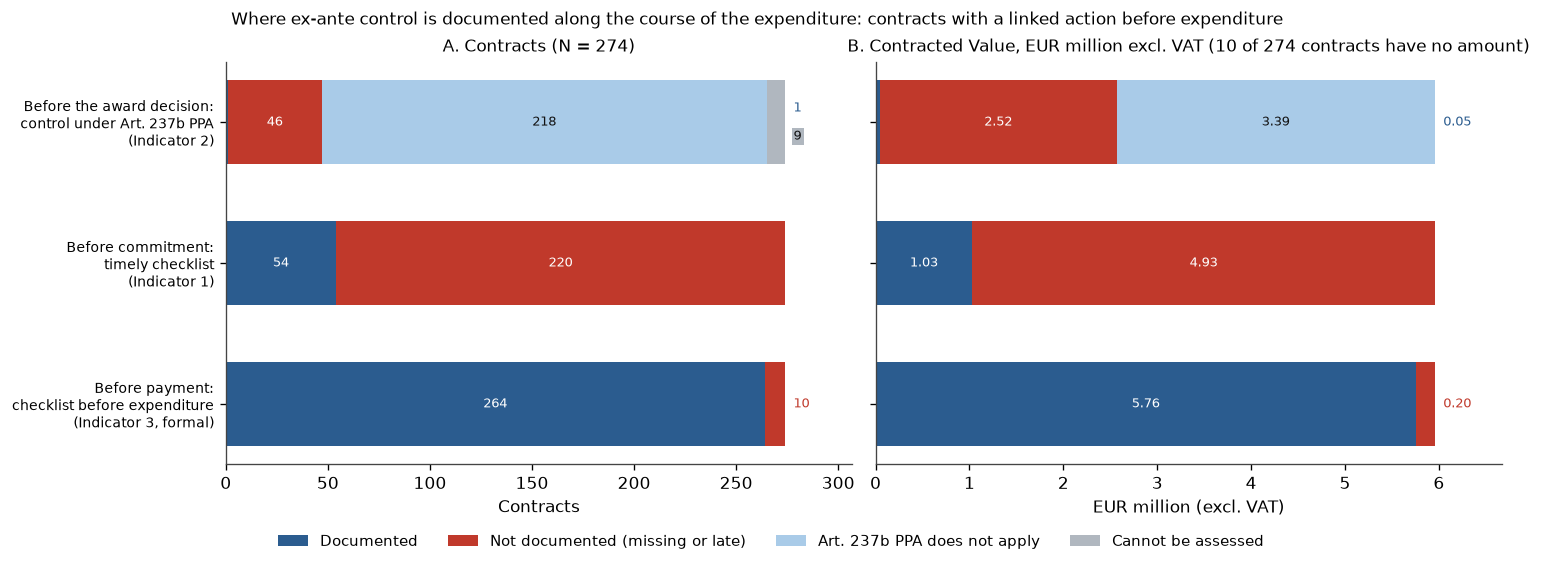

group,All contracts with a linked action before expenditure,Indicator 1 missing or late,of which: no linked action before commitment,Indicator 2 missing (Art. 237b applicable),Indicators 1 and 2 both missing,Indicator 1 present
contracts,274,220,191,46,40,54
schools,144,120,102,36,33,35
eur_excl_vat,5957290.23,4926054.38,4299237.92,2519769.53,2219260.74,1031235.85
without_amount,10,7,5,0,0,3
contracts_checklist_yes,264,212,188,44,38,52
schools_checklist_yes,140,116,102,35,32,34
eur_excl_vat_checklist_yes,5756535.02,4757917.71,4152339.86,2381774.34,2081265.55,998617.31
without_amount_checklist_yes,9,6,5,0,0,3
contracts_checklist_yes_with_payment,246,199,175,41,36,47
schools_checklist_yes_with_payment,136,110,96,33,30,32


,payment_records,contracts,schools,eur_excl_vat,without_amount
step,,,,,
Payment records of contracts with a linked action before expenditure,1530,256,140,5620445.95,8
Payment order date documented,763,224,129,4938203.39,4
... and the contract has a dated checklist,465,137,80,3240107.18,2
Signal: every dated checklist is after the payment order,114,48,41,1573204.33,0
Checklist dated on or before the payment order,351,126,73,3018465.45,2
... and invoice date documented,222,106,66,2405675.20,1
Signal: invoice dated after that checklist,64,38,29,1060989.39,0
Invoice dated on or before that checklist,158,88,60,1930136.43,1
... and protocol date documented,14,11,10,269387.17,0


,payment_records
group,
Confirmed order,11
Reversed order (signals),181
Order not verifiable (missing dates),1338


,records,documented_yyyy_mm_dd,documented_other_format,not_documented
field,,,,
checklist_date (linked actions before expenditure),455,270,0,185
payment_order_date (payment records in the chain),1530,763,5,762
invoice_date (payment records in the chain),1530,942,30,558
handover_protocol_date (payment records in the chain),1530,307,6,1217


Payment records linked: 4,273 of 7,629 (4,207 direct, 66 by document) | Linked action before expenditure: 274 contracts (checklist yes 264, no 10) | Checklist yes with Indicator 1 missing: 212 contracts, EUR 4,757,917.71 | Checklist on or before payment order: 351 of 465 comparable records | Full chain: 11 records | Unlinked checklist records: 691 before expenditure, 853 before commitment


In [12]:
pp_all = control_actions[control_actions["control_type"] == "преди_разход"]
pp_linked = pp_all[pp_all["contract_rec_id"] != MISSING_MARKER]
pp_unlinked = pp_all[pp_all["contract_rec_id"] == MISSING_MARKER]
pp_unlinked_present = pp_unlinked[pp_unlinked["checklist_present"] == "ДА"]
pp_last = pp_linked[pp_linked["is_last_of_type"] == "ДА"]
assert (len(pp_all), len(pp_linked), len(pp_last), pp_last["contract_rec_id"].nunique(), len(pp_unlinked)) == (1146, 455, 274, 274, 691)
assert (len(pp_unlinked_present), pp_unlinked_present["school"].nunique(), pp_unlinked["school"].nunique()) == (610, 145, 151)
assert set(pp_last["checklist_present"]) == {"ДА", "НЕ"}
pc_actions = control_actions[control_actions["control_type"] == "преди_поемане"]
pc_unlinked_n = int((pc_actions["contract_rec_id"] == MISSING_MARKER).sum())
assert pc_unlinked_n == 853

pay_linked = execution_payments[execution_payments["linked_contract_rec_id"] != MISSING_MARKER]
pay_direct = int((pay_linked["contract_rec_id"] == pay_linked["linked_contract_rec_id"]).sum())
pay_by_document = int((pay_linked["contract_rec_id"] == MISSING_MARKER).sum())
pay_unlinked_n = len(execution_payments) - len(pay_linked)
assert (len(execution_payments), len(pay_linked), pay_direct, pay_by_document, pay_unlinked_n) == (7629, 4273, 4207, 66, 3356)

payment_amount_num = pd.to_numeric(pay_linked["payment_amount"], errors="coerce")
payment_amount_n = int(payment_amount_num.notna().sum())
payment_amount_max = float(payment_amount_num.max())
assert payment_amount_n < len(pay_linked) and payment_amount_max > total_eur_excl_vat

pp_contracts = contracts[contracts["contract_rec_id"].isin(pp_last["contract_rec_id"])]
checklist_value = pp_contracts["contract_rec_id"].map(pp_last.set_index("contract_rec_id")["checklist_present"])
has_pc_action = pp_contracts["contract_rec_id"].isin(pc_actions.loc[pc_actions["contract_rec_id"] != MISSING_MARKER, "contract_rec_id"])
has_payment = pp_contracts["contract_rec_id"].isin(pay_linked["linked_contract_rec_id"])
ind1_missing = pp_contracts["class_10_01"] == "ДА"
ind2_missing = (pp_contracts["art_237b_applicable"] == "ДА") & (pp_contracts["class_10_04"] == "ДА")
assert len(pp_contracts) == 274 and set(pp_contracts["class_10_01"]) == {"ДА", "НЕ"}
assert ind1_missing[~has_pc_action].all()


def contract_totals(df: pd.DataFrame, suffix: str = "") -> dict:
    return {
        f"contracts{suffix}": len(df),
        f"schools{suffix}": int(df["school"].nunique()),
        f"eur_excl_vat{suffix}": round(float(df["amount_excl_vat_num"].sum()), 2),
        f"without_amount{suffix}": int(df["amount_excl_vat_num"].isna().sum()),
    }


asymmetry_groups = [
    ("All contracts with a linked action before expenditure", pd.Series(True, index=pp_contracts.index)),
    ("Indicator 1 missing or late", ind1_missing),
    ("of which: no linked action before commitment", ~has_pc_action),
    ("Indicator 2 missing (Art. 237b applicable)", ind2_missing),
    ("Indicators 1 and 2 both missing", ind1_missing & ind2_missing),
    ("Indicator 1 present", ~ind1_missing),
]
asymmetry_rows = []
for group, mask in asymmetry_groups:
    present = mask & (checklist_value == "ДА")
    asymmetry_rows.append({
        "group": group,
        **contract_totals(pp_contracts[mask]),
        **contract_totals(pp_contracts[present], "_checklist_yes"),
        **contract_totals(pp_contracts[present & has_payment], "_checklist_yes_with_payment"),
        **contract_totals(pp_contracts[mask & (checklist_value == "НЕ")], "_checklist_no"),
    })
pre_payment_asymmetry = pd.DataFrame(asymmetry_rows).set_index("group")
assert pre_payment_asymmetry["contracts"].tolist() == [274, 220, 191, 46, 40, 54]
assert pre_payment_asymmetry["eur_excl_vat"].tolist() == [5957290.23, 4926054.38, 4299237.92, 2519769.53, 2219260.74, 1031235.85]
assert pre_payment_asymmetry["without_amount"].tolist() == [10, 7, 5, 0, 0, 3]
assert (pre_payment_asymmetry["contracts_checklist_yes"] + pre_payment_asymmetry["contracts_checklist_no"]).tolist() == pre_payment_asymmetry["contracts"].tolist()
pre_payment_asymmetry.to_csv(DERIVED_DIR / "T2_pre_payment_asymmetry.csv", sep=";", encoding="utf-8", lineterminator="\n")


def documented(values: pd.Series) -> pd.Series:
    return values.notna() & (values != MISSING_MARKER)


def iso_date(values: pd.Series) -> pd.Series:
    return pd.to_datetime(values.where(documented(values)), format="%Y-%m-%d", errors="coerce")


chain = pay_linked[pay_linked["linked_contract_rec_id"].isin(pp_last["contract_rec_id"])].reset_index(drop=True)
chain["payment_day"] = iso_date(chain["payment_order_date"])
chain["invoice_day"] = iso_date(chain["invoice_date"])
chain["protocol_day"] = iso_date(chain["handover_protocol_date"])
checklists = pp_linked[pp_linked["checklist_present"] == "ДА"]
checklists = checklists.assign(checklist_day=iso_date(checklists["checklist_date"])).dropna(subset=["checklist_day"])
candidates = (
    chain[["linked_contract_rec_id", "payment_day"]]
    .rename_axis("payment_row")
    .reset_index()
    .merge(checklists[["contract_rec_id", "checklist_day"]], left_on="linked_contract_rec_id", right_on="contract_rec_id")
)
candidates = candidates[candidates["checklist_day"] <= candidates["payment_day"]]
chain["preceding_checklist_day"] = candidates.groupby("payment_row")["checklist_day"].max()

step_payment = chain["payment_day"].notna()
step_comparable = step_payment & chain["linked_contract_rec_id"].isin(checklists["contract_rec_id"])
step_checklist = chain["preceding_checklist_day"].notna()
step_invoice_dated = step_checklist & chain["invoice_day"].notna()
step_invoice = step_invoice_dated & (chain["invoice_day"] <= chain["preceding_checklist_day"])
step_protocol_dated = step_invoice & chain["protocol_day"].notna()
step_full = step_protocol_dated & (chain["protocol_day"] <= chain["invoice_day"])
signal_checklist = step_comparable & ~step_checklist
signal_invoice = step_invoice_dated & ~step_invoice
signal_protocol = step_protocol_dated & ~step_full
chain_steps = [
    ("Payment records of contracts with a linked action before expenditure", pd.Series(True, index=chain.index)),
    ("Payment order date documented", step_payment),
    ("... and the contract has a dated checklist", step_comparable),
    ("Signal: every dated checklist is after the payment order", signal_checklist),
    ("Checklist dated on or before the payment order", step_checklist),
    ("... and invoice date documented", step_invoice_dated),
    ("Signal: invoice dated after that checklist", signal_invoice),
    ("Invoice dated on or before that checklist", step_invoice),
    ("... and protocol date documented", step_protocol_dated),
    ("Signal: protocol dated after the invoice", signal_protocol),
    ("Full chain: protocol, invoice, checklist, payment order", step_full),
]
signal_any = signal_checklist | signal_invoice | signal_protocol
chain_groups = pd.DataFrame(
    {"payment_records": [int(step_full.sum()), int(signal_any.sum()), int((~(step_full | signal_any)).sum())]},
    index=pd.Index(["Confirmed order", "Reversed order (signals)", "Order not verifiable (missing dates)"], name="group"),
)
not_verifiable_parts = [
    int((~step_comparable).sum()),
    int((step_checklist & ~step_invoice_dated).sum()),
    int((step_invoice & ~step_protocol_dated).sum()),
]
assert [int(m.sum()) for m in (signal_checklist, signal_invoice, signal_protocol)] == [114, 64, 3]
assert chain_groups["payment_records"].tolist() == [11, 181, 1338] and chain_groups["payment_records"].sum() == len(chain)
assert not_verifiable_parts == [1065, 129, 144] and sum(not_verifiable_parts) == chain_groups["payment_records"].iloc[2]
chain_rows = []
for step, mask in chain_steps:
    step_contracts = contracts[contracts["contract_rec_id"].isin(chain.loc[mask, "linked_contract_rec_id"])]
    chain_rows.append({"step": step, "payment_records": int(mask.sum()), **contract_totals(step_contracts)})
payment_chain = pd.DataFrame(chain_rows).set_index("step")

date_rows = []
for field, values in [
    ("checklist_date (linked actions before expenditure)", pp_linked["checklist_date"]),
    ("payment_order_date (payment records in the chain)", chain["payment_order_date"]),
    ("invoice_date (payment records in the chain)", chain["invoice_date"]),
    ("handover_protocol_date (payment records in the chain)", chain["handover_protocol_date"]),
]:
    parsed = int(iso_date(values).notna().sum())
    date_rows.append({
        "field": field,
        "records": len(values),
        "documented_yyyy_mm_dd": parsed,
        "documented_other_format": int(documented(values).sum()) - parsed,
        "not_documented": int((~documented(values)).sum()),
    })
chain_dates = pd.DataFrame(date_rows).set_index("field")

record_conclusion("Section 8", "pre_payment_asymmetry", "payment records | all / linked / direct / by document / unlinked", f"{len(execution_payments)} / {len(pay_linked)} / {pay_direct} / {pay_by_document} / {pay_unlinked_n}")
record_conclusion("Section 8", "pre_payment_asymmetry", "actions before expenditure | all / linked / unlinked / unlinked with checklist / schools with unlinked checklist", f"{len(pp_all)} / {len(pp_linked)} / {len(pp_unlinked)} / {len(pp_unlinked_present)} / {pp_unlinked_present['school'].nunique()}")
for group, r in pre_payment_asymmetry.iterrows():
    for label, suffix in [("all", ""), ("checklist yes", "_checklist_yes"), ("checklist yes with payment record", "_checklist_yes_with_payment"), ("checklist no", "_checklist_no")]:
        record_conclusion("Section 8", "pre_payment_asymmetry", f"{group} | {label} | contracts / schools / EUR excl VAT / without amount", f"{int(r['contracts' + suffix])} / {int(r['schools' + suffix])} / {r['eur_excl_vat' + suffix]:.2f} / {int(r['without_amount' + suffix])}")
for step, r in payment_chain.iterrows():
    record_conclusion("Section 8", "pre_payment_asymmetry", f"document chain: {step} | payment records / contracts / schools / EUR excl VAT", f"{int(r['payment_records'])} / {int(r['contracts'])} / {int(r['schools'])} / {r['eur_excl_vat']:.2f}")
for group, r in chain_groups.iterrows():
    record_conclusion("Section 8", "pre_payment_asymmetry", f"document chain group: {group} | payment records", f"{int(r['payment_records'])}")
record_conclusion("Section 8", "pre_payment_asymmetry", "order not verifiable | no comparable payment order and checklist dates / no invoice date / no protocol date", " / ".join(str(n) for n in not_verifiable_parts))
for field, r in chain_dates.iterrows():
    record_conclusion("Section 8", "pre_payment_asymmetry", f"dates: {field} | records / YYYY-MM-DD / other format / not documented", f"{int(r['records'])} / {int(r['documented_yyyy_mm_dd'])} / {int(r['documented_other_format'])} / {int(r['not_documented'])}")
record_conclusion("Section 8", "pre_payment_asymmetry", "payment_amount | numeric records / linked records / maximum", f"{payment_amount_n} / {len(pay_linked)} / {payment_amount_max:.2f}")

a = pre_payment_asymmetry
base_n = len(pp_contracts)
base_eur = float(pp_contracts["amount_excl_vat_num"].sum())
base_without_amount = int(pp_contracts["amount_excl_vat_num"].isna().sum())
applicability = pp_contracts["art_237b_applicable"]
ind2_documented = (applicability == "ДА") & (pp_contracts["class_10_04"] == "НЕ")
ind2_not_applicable = applicability.isin(["НЕ", "неприложимо"])
ind2_not_assessed = applicability == MISSING_MARKER
no_row = pd.Series(False, index=pp_contracts.index)
control_points = [
    ("Before the award decision:\ncontrol under Art. 237b PPA\n(Indicator 2)", [ind2_documented, ind2_missing, ind2_not_applicable, ind2_not_assessed]),
    ("Before commitment:\ntimely checklist\n(Indicator 1)", [~ind1_missing, ind1_missing, no_row, no_row]),
    ("Before payment:\nchecklist before expenditure\n(Indicator 3, formal)", [checklist_value == "ДА", checklist_value == "НЕ", no_row, no_row]),
]
status_labels = ["Documented", "Not documented (missing or late)", "Art. 237b PPA does not apply", "Cannot be assessed"]
status_colors = ["#2b5c8f", "#c0392b", "#a9cbe8", "#b0b7bf"]
point_labels = [label for label, _ in control_points]
point_n = np.array([[int(mask.sum()) for mask in masks] for _, masks in control_points])
point_eur = np.array([[float(pp_contracts.loc[mask, "amount_excl_vat_num"].sum()) for mask in masks] for _, masks in control_points])
assert (np.array([[mask for mask in masks] for _, masks in control_points]).sum(axis=1) == 1).all()
assert point_n.sum(axis=1).tolist() == [base_n] * len(control_points)
assert np.allclose(point_eur.sum(axis=1), base_eur)
for (label, _), counts, values in zip(control_points, point_n, point_eur):
    for status, count, value in zip(status_labels, counts, values):
        record_conclusion("Section 8", "pre_payment_asymmetry", f"control point: {label.replace(chr(10), ' ')} | {status} | contracts / EUR excl VAT", f"{count} / {value:.2f}")

checklist_yes = checklist_value == "ДА"
union_totals = contract_totals(pp_contracts[checklist_yes & (ind1_missing | ind2_missing)])
assert tuple(union_totals.values()) == (218, 118, 5058426.50, 6)
assert union_totals["contracts"] == int((checklist_yes & ind1_missing).sum() + (checklist_yes & ind2_missing).sum() - (checklist_yes & ind1_missing & ind2_missing).sum())
record_conclusion("Section 8", "pre_payment_asymmetry", "checklist yes with Indicator 1 or Indicator 2 missing, each contract once | contracts / schools / EUR excl VAT / without amount", f"{union_totals['contracts']} / {union_totals['schools']} / {union_totals['eur_excl_vat']:.2f} / {union_totals['without_amount']}")

ind1_checklist_yes = checklist_yes & ind1_missing
ind1_share = ind1_checklist_yes.sum() / checklist_yes.sum()
assert (int(ind1_checklist_yes.sum()), int(checklist_yes.sum()), f"{ind1_share:.2%}") == (212, 264, "80.30%")
record_conclusion("Section 8", "pre_payment_asymmetry", "Indicator 1 missing among contracts with checklist yes | contracts / base / share", f"{int(ind1_checklist_yes.sum())} / {int(checklist_yes.sum())} / {ind1_share:.2%}")

status_without_amount = [int(pp_contracts.loc[mask, "amount_excl_vat_num"].isna().sum()) for mask in control_points[0][1]]
assert status_without_amount == [0, 0, 1, 9] and sum(status_without_amount) == base_without_amount
for status, count in zip(status_labels, status_without_amount):
    record_conclusion("Section 8", "pre_payment_asymmetry", f"Art. 237b status: {status} | contracts without amount", f"{count}")

dated_payment_ids = pay_linked.loc[iso_date(pay_linked["payment_order_date"]).notna(), "linked_contract_rec_id"]
ind1_with_record_n = int((ind1_checklist_yes & has_payment).sum())
ind1_dated_order_n = int((ind1_checklist_yes & pp_contracts["contract_rec_id"].isin(dated_payment_ids)).sum())
assert (ind1_with_record_n, ind1_dated_order_n) == (199, 176)
record_conclusion("Section 8", "pre_payment_asymmetry", "checklist yes with Indicator 1 missing | contracts / with a linked payment record / with a documented payment order date", f"{int(ind1_checklist_yes.sum())} / {ind1_with_record_n} / {ind1_dated_order_n}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.6), sharey=True, constrained_layout=True)
for ax, matrix, text_format in [(ax1, point_n.astype(float), "{:.0f}"), (ax2, point_eur / 1e6, "{:.2f}")]:
    total = matrix.sum(axis=1).max()
    left = np.zeros(len(point_labels))
    for j, (status, color) in enumerate(zip(status_labels, status_colors)):
        ax.barh(point_labels, matrix[:, j], left=left, color=color, height=0.6, label=status)
        left += matrix[:, j]
    for i, row in enumerate(matrix):
        start, outside = 0.0, []
        for j, value in enumerate(row):
            if value > 0 and value >= 0.09 * total:
                ax.text(start + value / 2, i, text_format.format(value), ha="center", va="center", fontsize=8, color="white" if j < 2 else "#111111")
            elif value > 0:
                outside.append((value, j))
            start += value
        for k, (value, j) in enumerate(outside):
            offset = (k - (len(outside) - 1) / 2) * 0.2
            ax.text(total * 1.015, i + offset, text_format.format(value), ha="left", va="center", fontsize=8, color=status_colors[j] if j < 2 else "#111111",
                    bbox={"boxstyle": "square,pad=0.15", "facecolor": status_colors[j] if j >= 2 else "white", "edgecolor": "none"})
    ax.set_xlim(0, total * 1.12)
    ax.spines[["top", "right"]].set_visible(False)
ax1.set_xlabel("Contracts")
ax1.set_title(f"A. Contracts (N = {base_n})", fontsize=10)
ax2.set_xlabel("EUR million (excl. VAT)")
ax2.set_title(f"B. Contracted Value, EUR million excl. VAT ({base_without_amount} of {base_n} contracts have no amount)", fontsize=10)
ax1.tick_params(axis="y", labelsize=8.5)
ax1.invert_yaxis()
fig.legend(*ax1.get_legend_handles_labels(), fontsize=9, loc="outside lower center", ncols=4, frameon=False)
fig.suptitle(
    "Where ex-ante control is documented along the course of the expenditure: contracts with a linked action before expenditure",
    fontsize=10,
)
save_fig_300(fig, "F7_pre_payment_asymmetry.png")
plt.show()
plt.close(fig)

display(a.astype(object).T)
display(payment_chain)
display(chain_groups)
display(chain_dates)

print(
    f"Payment records linked: {len(pay_linked):,} of {len(execution_payments):,} ({pay_direct:,} direct, {pay_by_document} by document) | "
    f"Linked action before expenditure: {len(pp_contracts)} contracts (checklist yes {a['contracts_checklist_yes'].iloc[0]}, no {a['contracts_checklist_no'].iloc[0]}) | "
    f"Checklist yes with Indicator 1 missing: {a['contracts_checklist_yes'].iloc[1]} contracts, {fmt_eur(a['eur_excl_vat_checklist_yes'].iloc[1])} | "
    f"Checklist on or before payment order: {int(step_checklist.sum())} of {int(step_comparable.sum())} comparable records | "
    f"Full chain: {int(step_full.sum())} records | Unlinked checklist records: {len(pp_unlinked)} before expenditure, {pc_unlinked_n} before commitment"
)

**Economic & Financial Control Implication:** Of 7,629 payment records, 4,273 are linked to a contract (4,207 directly and 66 by document) and 3,356 remain unlinked. Of 1,146 actions before expenditure, 455 are linked and give a last action for **274 contracts** in 144 schools (EUR 5,957,290.23 excl. VAT; 10 without an amount). In **264** of them (140 schools, EUR 5,756,535.02; 9 without an amount) the checklist is recorded as present; in the other **10** it is `НЕ` (EUR 200,755.21; 1 without an amount).

**Control asymmetry:** **212 of the 264 contracts with a checklist before expenditure (80.30%)**, in 116 schools, are in class 10.01, with a contracted value of **EUR 4,757,917.71** (6 without an amount). For 188 of them (EUR 4,152,339.86; 5 without an amount) no action before commitment is linked at all. Where Art. 237b applies, 44 contracts carry a checklist before expenditure without control under that article (EUR 2,381,774.34), and 38 of these lack both Indicator 1 and Indicator 2 (EUR 2,081,265.55). Counting each contract once, **218 of the 264 contracts with a checklist before expenditure** lack Indicator 1 or, where Art. 237b applies, Indicator 2, with a contracted value of **EUR 5,058,426.50** excl. VAT (6 without an amount). Across all 274 contracts with a linked action before expenditure, whatever the checklist value (top row of the figure above; contracted values excl. VAT), control under Art. 237b is documented for 1 contract (EUR 47,092.68), not documented for 46 (EUR 2,519,769.53), not applicable to 218 (EUR 3,390,428.02; 1 of them without a documented amount) and cannot be assessed for 9 (none of which has a documented amount). The 46 without documented control are the 44 above, which carry a checklist before expenditure, plus 2 whose checklist is `НЕ` (EUR 137,995.19). Separately, the base is all 274 contracts with a linked action before expenditure, whatever the checklist value: Indicator 1 is missing for 220 of them (EUR 4,926,054.38; 7 without an amount), including 191 without a linked action before commitment (EUR 4,299,237.92; 5 without an amount). At least one linked payment record exists for 199 of the 212 contracts (contracted value EUR 4,481,305.16; 4 without an amount), and for 176 of the 212 at least one linked record has a documented payment order date. A linked record alone does not show that payment was reached: a dated payment order is on record only for these 176 contracts, so only for them does the asymmetry demonstrably concern expenditure that has reached the point of payment.

These amounts are contracted values, not amounts paid. `payment_amount` is not summed: it is numeric in only 2,006 of the 4,273 linked payment records, and its largest value (1,000,012,348.00) exceeds the total contracted value of all contracts in the corpus, so a sum would not measure expenditure.

**Document chain** (step by step in the document-chain table above): Of the 274 contracts, 256 have linked payment records, 1,530 in total; these records fall into three groups.

| Group | Payment records | Composition |
|---|---:|---|
| Confirmed order: protocol → invoice → checklist → payment order | **11** (8 contracts, 7 schools) | every step is dated and in the expected order |
| Reversed order: signals for review | **181** | 114 where every dated checklist of the contract is later than the payment order; 64 where the invoice is dated after the checklist, which therefore precedes a document it should verify; 3 where the handover protocol is dated after the invoice |
| Order not verifiable: missing dates | **1,338** | 1,065 without a payment order date or without any dated checklist of the contract; 129 without an invoice date; 144 without a protocol date |

A checklist is dated on or before the payment order for **351 of the 465** records where both dates can be compared, and in 158 of the 222 of these with an invoice date the invoice is dated on or before the checklist, as expected. Missing dates are the main constraint: no checklist date is recorded for 185 of the 455 linked actions, and among the 1,530 payment records the payment order date is not documented for 762, the invoice date for 558 and the protocol date for 1,217. Dates recorded in another format (5, 30 and 6 records respectively) are not compared and count as missing.

*Limitation:* 691 actions before expenditure (610 of them with a checklist, in 145 schools) and 853 actions before commitment name no contract. Indicator 3 is therefore a lower bound, and part of the asymmetry and of the reversed order may reflect checklists that are undated or cannot be linked.

**Answer:** First, a checklist before expenditure is recorded for **264 of the 274 contracts** with a linked action. Second, **212 of them (EUR 4,757,917.71 contracted value)** lack Indicator 1; where Art. 237b applies, 44 lack Indicator 2 (EUR 2,381,774.34) and 38 lack both (EUR 2,081,265.55). Counted once, **218 of them (EUR 5,058,426.50 contracted value)** lack Indicator 1 or Indicator 2, the latter counted only where Art. 237b applies. Third, of 1,530 payment records the expected order is confirmed for **11**, reversed for **181** and not verifiable for **1,338**; the last group is not evidence of a breach. The financial-control priority is to require the checklist before commitment as a condition for signing the contract; where Art. 237b applies, to have the control under that article exercised after the evaluation committee's report and before the contracting authority's award decision; and to verify before each payment a dated checklist linked to the contract, the invoice and the handover protocol. These are indicators for review, not proven violations, and **Indicator 3 does not by itself prove ex-ante control**.

## 9. Recorded Results of Control by Risk Practice

**Financial-control question:** What does the corpus record of control before commitment and before expenditure for five classes of risk practices (Beluhov, 2026b) and four public-data signals (Beluhov, 2026a), and which control questions follow?

*Practices:* Classes 1.01 (*Splitting of procurements*), 1.02 (*Direct award at a value requiring a call or procedure*), 10.01 (*Commitment or payment without ex-ante control*), 10.03 (*Unestablished procedure for ex-ante control*), and 10.04 (*Unperformed ex-ante control for legality of a procurement above the threshold*). Signals: *Purchases from one supplier within 30 days, each below the threshold, together reaching it*; *Contract signed before the project start*; *Price just below BGN 50,000 (from 2024)*; *Direct award of BGN 30,000 to below 50,000 (up to 2023) although a call or procedure was required*.

*Legal basis:* Ex-ante control of legality follows a risk assessment, a cost-benefit analysis, and the guidelines of the Minister of Finance (Art. 13(3)(3) and 13(4)) (Bulgaria, 2006a). Its result is a written statement (section II); the head of the organisation takes the final decision (section III) (Ministry of Finance, 2020). The award procedure provided by law applies where its grounds are present (Art. 17(1)); splitting to apply rules for lower values is prohibited except under Art. 21(6) (Art. 21(15)), subject to the cases that do not count as splitting (Art. 21(16)) (Bulgaria, 2016a).

*Reading rules:* A contract shows an opinion of legality, an opinion with reservations, or a refusal, as recorded on its last linked checklist, or **no record**. In the terms of Section 1, these are the unqualified approval (`одобрено`), the conditional approval (`с_резерви`), the explicit refusal (`отказ`), and the missing checklist or opinion (`няма_документ`). For the five classes only, an opinion with reservations or a refusal is an **objection recorded** (corpus category caught, `уловена`), and an opinion of legality is **no objection recorded** (missed, `пропусната`). An objection recorded is what the checklist shows, not a finding of an inspection (including by ADFI) and not a proven irregularity. A class applies where its value is `ДА` (yes). No record means no document in the corpus; it does not mean that no control was performed and is not counted as a missed case. The signals are assessed for the 1,167 contracts linked to ISUN 2020 (ISUN 2020, 2026).

*Rule of Section 1:* For classes 1.01 (*Splitting of procurements*) and 1.02 (*Direct award at a value requiring a call or procedure*) and for the four signals, the strict rule of Section 1 counts as caught only a refusal before commitment on a checklist not dated after the contract; a refusal before expenditure is reported under Indicator 3 (the formal requirement of control before expenditure), read with Indicator 1 (the financial controller's documented control before commitment) and, where applicable, Indicator 2 (the control under Art. 237b PPA before the award decision). That rule remains in force. This section shows the two classes by their corpus record, which differs from it, and states the result of the rule separately.

*Missing and not assessable:* The 228 contracts not linked to ISUN 2020 (EUR 4,928,995.44; 123 without an amount) cannot be assessed for the signals. Classes 1.01 (*Splitting of procurements*) and 1.02 (*Direct award at a value requiring a call or procedure*) cannot be assessed for 368 contracts each (EUR 3,262,577.74; 162 without an amount). Class 10.03 (*Unestablished procedure for ex-ante control*) cannot be assessed for 143 (EUR 3,257,271.00; 12 without an amount). Class 10.04 (*Unperformed ex-ante control for legality of a procurement above the threshold*) cannot be assessed for 137, all without an amount, and is not applicable (`неприложимо`) to 47 (EUR 434,725.61; 25 without an amount). Among the contracts to which a practice applies, an amount is missing for 156 of class 10.01 (*Commitment or payment without ex-ante control*), 38 of class 10.03 (*Unestablished procedure for ex-ante control*), 3 of the signal *Purchases from one supplier within 30 days, each below the threshold, together reaching it*, and 1 of the signal *Contract signed before the project start*. Indicator 2 (the control under Art. 237b PPA before the award decision) cannot be assessed for 1 contract of the signal *Purchases from one supplier within 30 days, each below the threshold, together reaching it*, without an amount.

*Limitations:* A result does not state which irregularity it concerns. 853 of 1,328 checklists before commitment and 691 of 1,146 before expenditure name no contract. The checklist before expenditure is a formal condition (Executive Agency 'Programme for Education', n.d.; Ministry of Education and Science, 2023). A signal calls for verification, not a finding; Beluhov (2026a) reads the signal *Price just below BGN 50,000 (from 2024)* as an indication. Practices overlap and are not added up. Amounts are contracted EUR excl. VAT; missing amounts are not summed.

*Data fields:* `class_1_01`, `class_1_02`, `class_10_01`, `class_10_03`, `class_10_04` (class value; 10.03 *Unestablished procedure for ex-ante control* is recorded by school); `controller_opinion_pre_commitment`, `controller_opinion_pre_payment` (recorded result before commitment and before expenditure); `caught_or_missed_class_*` (corpus category of each of the five classes at each moment); `flag_split_30d`, `flag_predated`, `flag_bunching_50k`, `flag_regime_mismatch` (the four signals); `is_last_of_type` (last checklist of its kind), `delta_t_num` (days from the contract to the checklist), `art_237b_applicable` (applicability of Art. 237b PPA).

*Measurability boundary:* Five of the 52 classes in scope (53 in the classifier, without 10.02) are measured. For the other 47, all 54,802 rows of `classifier_checks` record `неприложимо` (not applicable), a data limit and not proof that checklists omit these checks.

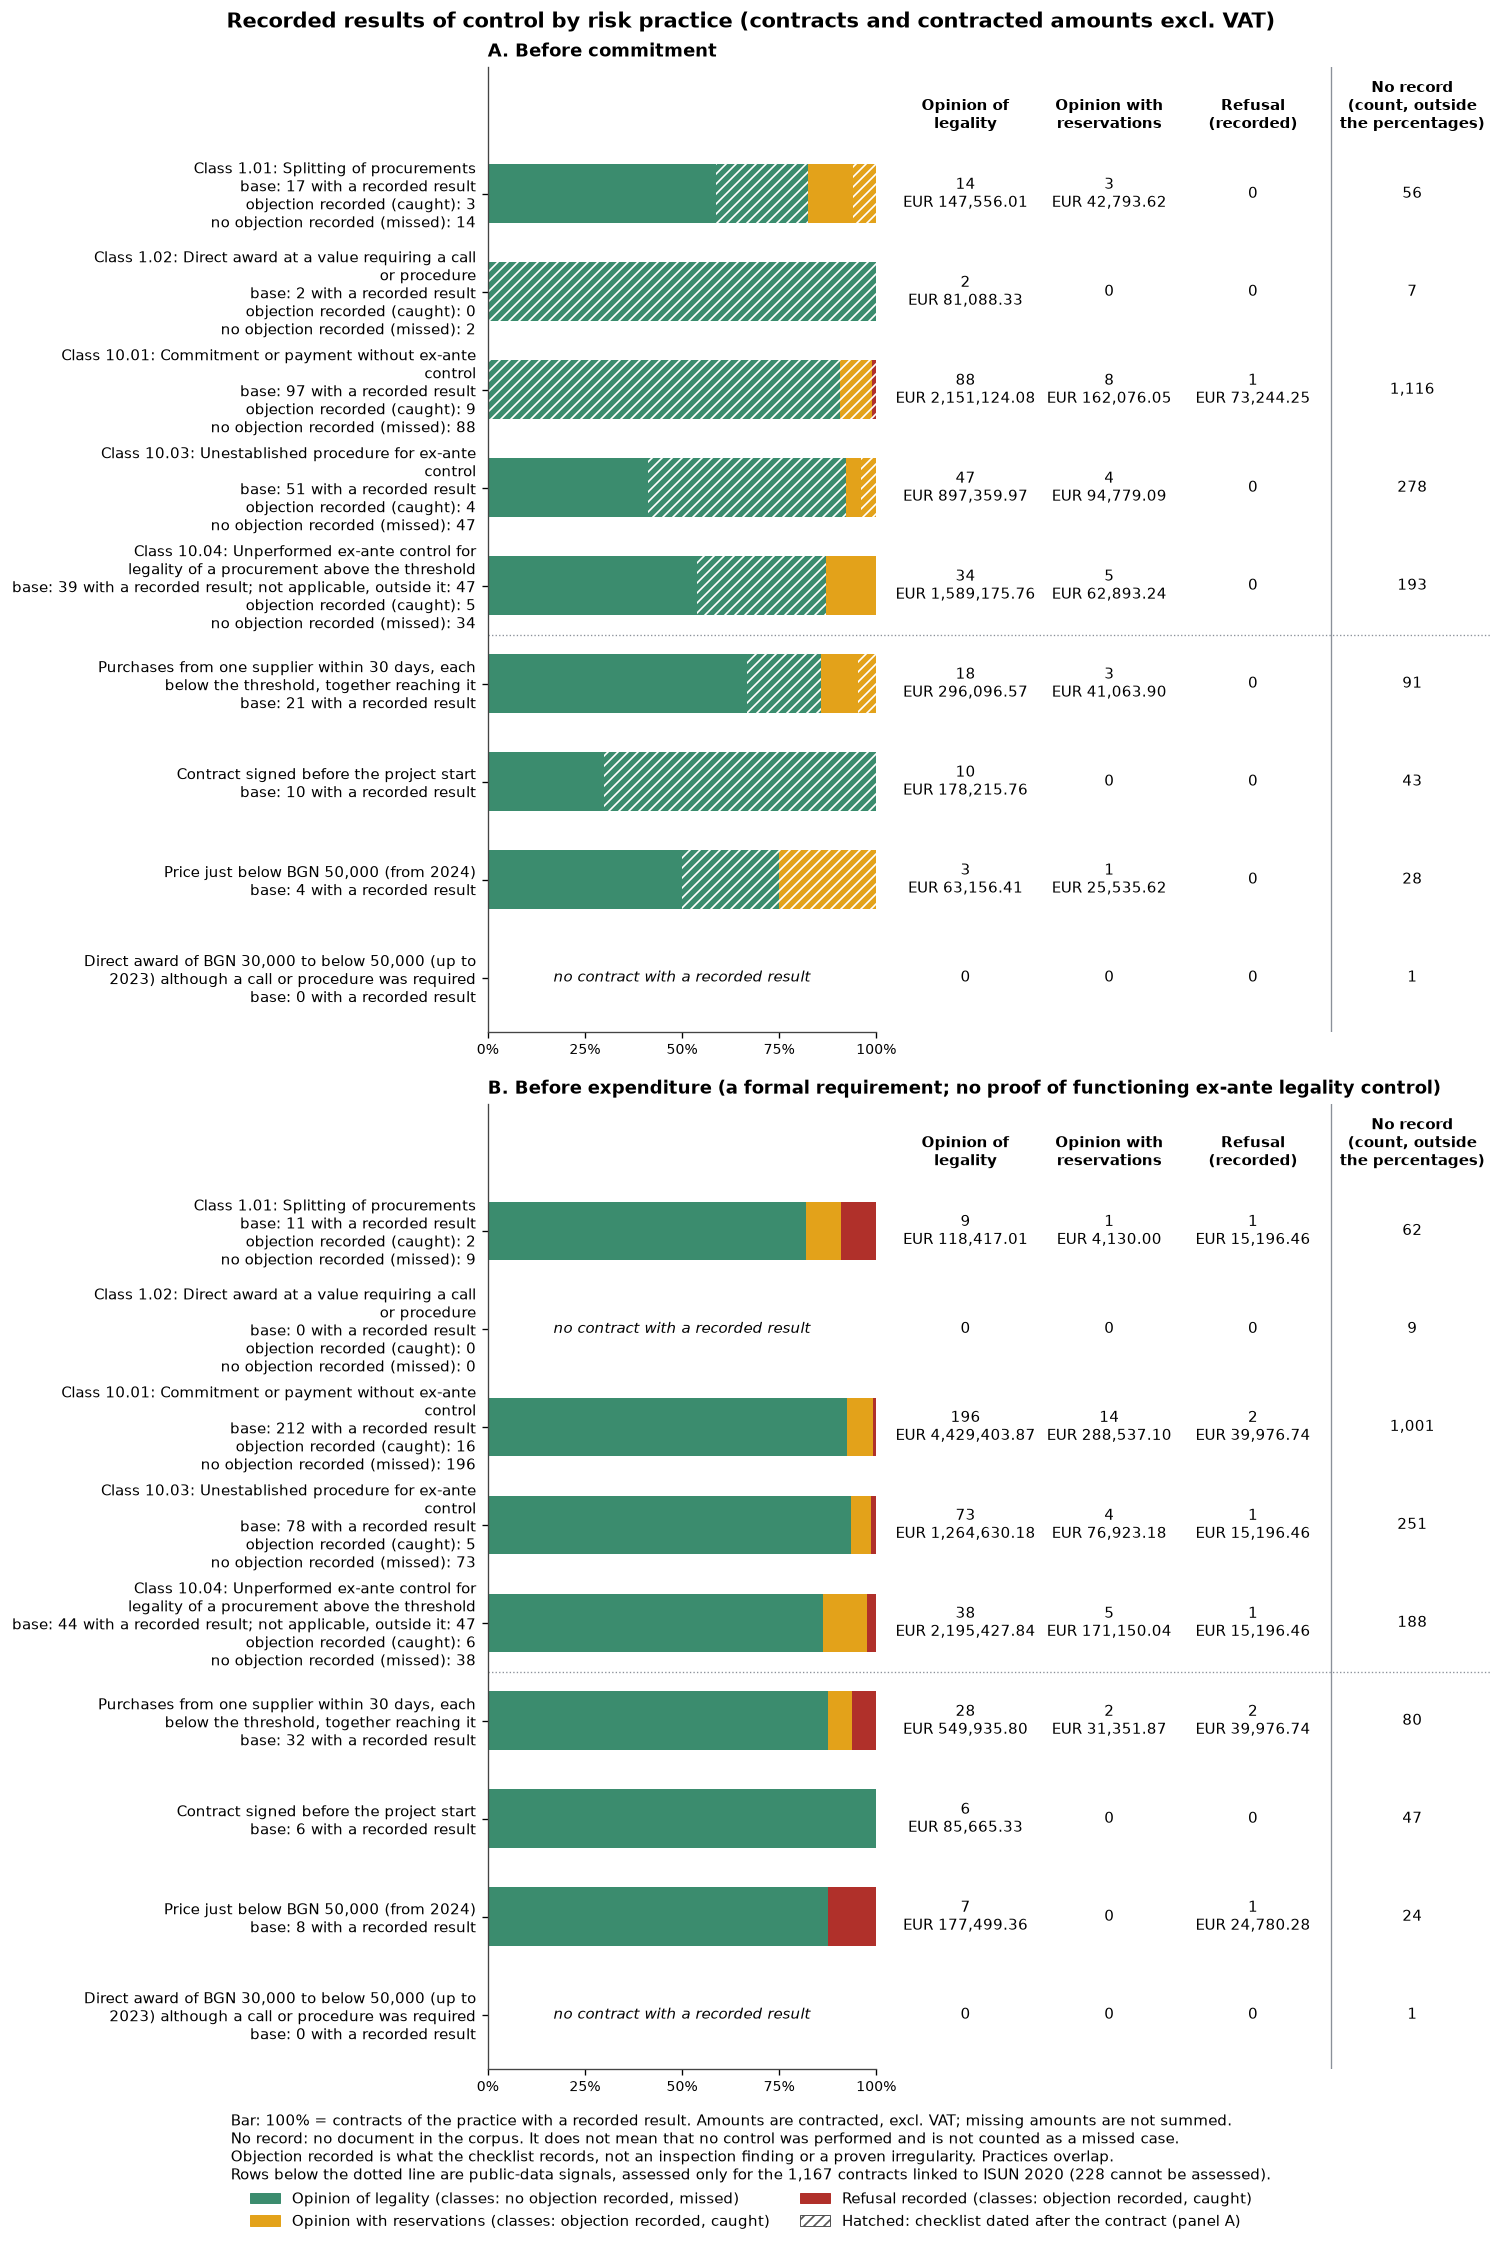

In [13]:
import textwrap

measured_classes = ["1.01", "1.02", "10.01", "10.03", "10.04"]
signal_names = ["split_30d", "predated", "bunching_50k", "regime_mismatch"]
result_values = {"opinion_of_legality": "одобрено", "opinion_with_reservations": "с_резерви", "refusal": "отказ"}
section_1_rule_practices = ["1.01", "1.02"] + signal_names
points_9 = [("before commitment", "pre_commitment", "преди_поемане"), ("before expenditure", "pre_payment", "преди_разход")]
practice_names = {
    "1.01": "Splitting of procurements",
    "1.02": "Direct award at a value requiring a call or procedure",
    "10.01": "Commitment or payment without ex-ante control",
    "10.03": "Unestablished procedure for ex-ante control",
    "10.04": "Unperformed ex-ante control for legality of a procurement above the threshold",
    "split_30d": "Purchases from one supplier within 30 days, each below the threshold, together reaching it",
    "predated": "Contract signed before the project start",
    "bunching_50k": "Price just below BGN 50,000 (from 2024)",
    "regime_mismatch": "Direct award of BGN 30,000 to below 50,000 (up to 2023) although a call or procedure was required",
}

s9 = contracts.copy()
s9["class_10_03"] = s9["school"].map(schools.set_index("school")["class_10_03"])
last_commitment = control_actions[
    (control_actions["control_type"] == "преди_поемане")
    & (control_actions["is_last_of_type"] == "ДА")
    & (control_actions["contract_rec_id"] != MISSING_MARKER)
].set_index("contract_rec_id")
assert last_commitment.index.is_unique
late_result = (s9["controller_opinion_pre_commitment"] != MISSING_MARKER) & (s9["contract_rec_id"].map(last_commitment["delta_t_num"]) > 0)
is_linked = s9["contract_rec_id"].isin(isun_linked["contract_rec_id"])


def put(row: dict, name: str, mask: pd.Series, with_missing: bool = False) -> None:
    totals = contract_totals(s9[mask])
    row[f"{name}_contracts"] = totals["contracts"]
    row[f"{name}_eur"] = round(float(totals["eur_excl_vat"]), 2)
    if with_missing:
        row[f"{name}_without_amount"] = totals["without_amount"]


def split_into(row: dict, base: pd.Series, parts: dict) -> None:
    assert (sum((base & mask).astype(int) for mask in parts.values()) == base.astype(int)).all()
    for name, mask in parts.items():
        put(row, name, base & mask)


def practice_label(practice: str) -> str:
    return f"Class {practice}: {practice_names[practice]}" if practice in measured_classes else practice_names[practice]


rows = []
section_1_rule = {}
for practice in measured_classes + signal_names:
    is_class = practice in measured_classes
    suffix = practice.replace(".", "_")
    if is_class:
        value = s9[f"class_{suffix}"]
        applies = value == "ДА"
        not_present, cannot_be_assessed, cannot_apply = value == "НЕ", value == MISSING_MARKER, value == "неприложимо"
    else:
        assert set(s9.loc[is_linked, f"flag_{practice}"]) <= {"True", "False"}
        applies = is_linked & (s9[f"flag_{practice}"] == "True")
        not_present, cannot_be_assessed, cannot_apply = is_linked & ~applies, ~is_linked, pd.Series(False, index=s9.index)
    for point, key, _ in points_9:
        opinion = s9[f"controller_opinion_{key}"]
        assert set(opinion) <= set(result_values.values()) | {MISSING_MARKER}
        no_record = opinion == MISSING_MARKER
        recorded = applies & ~no_record
        results = {name: recorded & (opinion == stored) for name, stored in result_values.items()}
        late = late_result if key == "pre_commitment" else pd.Series(False, index=s9.index)
        row = {"practice_type": "class" if is_class else "signal", "practice": practice, "practice_name": practice_names[practice], "control_point": point}
        put(row, "applies", applies, with_missing=True)
        put(row, "recorded", recorded)
        split_into(row, recorded, results)
        put(row, "no_record", applies & no_record, with_missing=True)
        assert row["recorded_contracts"] + row["no_record_contracts"] == row["applies_contracts"]
        if key == "pre_commitment":
            put(row, "checklist_after_contract", applies & late)
            for name, mask in results.items():
                row[f"{name}_after_contract_contracts"] = int((mask & late).sum())
        if is_class:
            record = s9[f"caught_or_missed_class_{suffix}_{key}"]
            rebuilt = np.select([~applies, no_record, opinion == "одобрено"], ["неприложимо", MISSING_MARKER, "пропусната"], default="уловена")
            assert (record == rebuilt).all()
            categories = {"corpus_caught": record == "уловена", "corpus_missed": record == "пропусната"}
            split_into(row, recorded, categories)
            assert row["corpus_caught_contracts"] == row["opinion_with_reservations_contracts"] + row["refusal_contracts"]
            assert row["corpus_missed_contracts"] == row["opinion_of_legality_contracts"]
            if key == "pre_commitment":
                for name, mask in categories.items():
                    row[f"{name}_after_contract_contracts"] = int((recorded & mask & late).sum())
        if practice in section_1_rule_practices:
            totals = contract_totals(s9[results["refusal"] & ~late])
            section_1_rule[(practice, point)] = (totals["contracts"], totals["eur_excl_vat"])
        put(row, "not_present", not_present, with_missing=True)
        put(row, "cannot_be_assessed", cannot_be_assessed, with_missing=True)
        put(row, "cannot_apply", cannot_apply, with_missing=True)
        assert sum(row[f"{n}_contracts"] for n in ["applies", "not_present", "cannot_be_assessed", "cannot_apply"]) == len(s9)
        if not is_class:
            article = s9["art_237b_applicable"]
            first_missing = s9["class_10_01"] == "ДА"
            second_missing = (article == "ДА") & (s9["class_10_04"] == "ДА")
            split_into(row, applies, {"indicator_1_documented": s9["class_10_01"] == "НЕ", "indicator_1_missing_or_late": first_missing})
            split_into(row, applies, {
                "indicator_2_documented": (article == "ДА") & (s9["class_10_04"] == "НЕ"),
                "indicator_2_not_documented": second_missing,
                "indicator_2_not_applicable": article.isin(["НЕ", "неприложимо"]),
                "indicator_2_cannot_be_assessed": article == MISSING_MARKER,
            })
            if key == "pre_payment":
                refused = applies & (opinion == "отказ")
                row["refusal_without_indicator_1_contracts"] = int((refused & first_missing).sum())
                row["refusal_without_indicator_2_contracts"] = int((refused & second_missing).sum())
        rows.append(row)


identity_columns = ["practice_type", "practice", "practice_name", "control_point"]
value_columns = [
    "applies_contracts",
    "applies_eur",
    "applies_without_amount",
    "recorded_contracts",
    "opinion_of_legality_contracts",
    "opinion_of_legality_eur",
    "opinion_with_reservations_contracts",
    "opinion_with_reservations_eur",
    "refusal_contracts",
    "refusal_eur",
    "no_record_contracts",
    "no_record_eur",
    "checklist_after_contract_contracts",
    "checklist_after_contract_eur",
    "opinion_of_legality_after_contract_contracts",
    "opinion_with_reservations_after_contract_contracts",
    "refusal_after_contract_contracts",
    "corpus_caught_contracts",
    "corpus_caught_eur",
    "corpus_missed_contracts",
    "cannot_be_assessed_contracts",
    "cannot_be_assessed_eur",
    "cannot_be_assessed_without_amount",
    "cannot_apply_contracts",
    "cannot_apply_eur",
    "cannot_apply_without_amount",
    "indicator_1_missing_or_late_contracts",
    "indicator_1_missing_or_late_eur",
    "indicator_2_documented_contracts",
    "indicator_2_not_documented_contracts",
    "indicator_2_not_documented_eur",
    "indicator_2_cannot_be_assessed_contracts",
    "indicator_2_cannot_be_assessed_eur",
    "refusal_without_indicator_1_contracts",
    "refusal_without_indicator_2_contracts",
]
practice_table = pd.DataFrame(rows)[identity_columns + value_columns]
for column in value_columns:
    if not column.endswith("_eur"):
        practice_table[column] = practice_table[column].astype("Int64")
assert practice_table.shape == (18, len(identity_columns) + len(value_columns))


def row_signature(row: pd.Series) -> str:
    return " ".join("-" if pd.isna(row[c]) else (f"{row[c]:.2f}" if c.endswith("_eur") else str(row[c])) for c in value_columns)


expected_rows = {
    ("1.01", "before commitment"): "73 997248.14 0 17 14 147556.01 3 42793.62 0 0.00 56 806898.51 5 67113.81 4 1 0 3 42793.62 14 368 3262577.74 162 0 0.00 0 - - - - - - - - -",
    ("1.01", "before expenditure"): "73 997248.14 0 11 9 118417.01 1 4130.00 1 15196.46 62 859504.67 - - - - - 2 19326.46 9 368 3262577.74 162 0 0.00 0 - - - - - - - - -",
    ("1.02", "before commitment"): "9 537559.86 0 2 2 81088.33 0 0.00 0 0.00 7 456471.53 2 81088.33 2 0 0 0 0.00 2 368 3262577.74 162 0 0.00 0 - - - - - - - - -",
    ("1.02", "before expenditure"): "9 537559.86 0 0 0 0.00 0 0.00 0 0.00 9 537559.86 - - - - - 0 0.00 0 368 3262577.74 162 0 0.00 0 - - - - - - - - -",
    ("10.01", "before commitment"): "1213 24831164.29 156 97 88 2151124.08 8 162076.05 1 73244.25 1116 22444719.91 97 2386444.38 88 8 1 9 235320.30 88 0 0.00 0 0 0.00 0 - - - - - - - - -",
    ("10.01", "before expenditure"): "1213 24831164.29 156 212 196 4429403.87 14 288537.10 2 39976.74 1001 20073246.58 - - - - - 16 328513.84 196 0 0.00 0 0 0.00 0 - - - - - - - - -",
    ("10.03", "before commitment"): "329 6748858.98 38 51 47 897359.97 4 94779.09 0 0.00 278 5756719.92 28 613507.56 26 2 0 4 94779.09 47 143 3257271.00 12 0 0.00 0 - - - - - - - - -",
    ("10.03", "before expenditure"): "329 6748858.98 38 78 73 1264630.18 4 76923.18 1 15196.46 251 5392109.16 - - - - - 5 92119.64 73 143 3257271.00 12 0 0.00 0 - - - - - - - - -",
    ("10.04", "before commitment"): "232 11033935.84 0 39 34 1589175.76 5 62893.24 0 0.00 193 9381866.84 13 737816.37 13 0 0 5 62893.24 34 137 0.00 137 47 434725.61 25 - - - - - - - - -",
    ("10.04", "before expenditure"): "232 11033935.84 0 44 38 2195427.84 5 171150.04 1 15196.46 188 8652161.50 - - - - - 6 186346.50 38 137 0.00 137 47 434725.61 25 - - - - - - - - -",
    ("split_30d", "before commitment"): "112 1726574.79 3 21 18 296096.57 3 41063.90 0 0.00 91 1389414.32 5 79221.51 4 1 0 - - - 228 4928995.44 123 0 0.00 0 95 1454369.15 0 15 415898.26 1 0.00 - -",
    ("split_30d", "before expenditure"): "112 1726574.79 3 32 28 549935.80 2 31351.87 2 39976.74 80 1105310.38 - - - - - - - - 228 4928995.44 123 0 0.00 0 95 1454369.15 0 15 415898.26 1 0.00 2 1",
    ("predated", "before commitment"): "53 1003841.38 1 10 10 178215.76 0 0.00 0 0.00 43 825625.62 7 64982.93 7 0 0 - - - 228 4928995.44 123 0 0.00 0 50 890608.55 0 14 492082.37 0 0.00 - -",
    ("predated", "before expenditure"): "53 1003841.38 1 6 6 85665.33 0 0.00 0 0.00 47 918176.05 - - - - - - - - 228 4928995.44 123 0 0.00 0 50 890608.55 0 14 492082.37 0 0.00 0 0",
    ("bunching_50k", "before commitment"): "32 758682.90 0 4 3 63156.41 1 25535.62 0 0.00 28 669990.87 2 50323.05 1 1 0 - - - 228 4928995.44 123 0 0.00 0 30 720313.92 0 8 202868.38 0 0.00 - -",
    ("bunching_50k", "before expenditure"): "32 758682.90 0 8 7 177499.36 0 0.00 1 24780.28 24 556403.26 - - - - - - - - 228 4928995.44 123 0 0.00 0 30 720313.92 0 8 202868.38 0 0.00 1 0",
    ("regime_mismatch", "before commitment"): "1 21813.09 0 0 0 0.00 0 0.00 0 0.00 1 21813.09 0 0.00 0 0 0 - - - 228 4928995.44 123 0 0.00 0 1 21813.09 0 0 0.00 0 0.00 - -",
    ("regime_mismatch", "before expenditure"): "1 21813.09 0 0 0 0.00 0 0.00 0 0.00 1 21813.09 - - - - - - - - 228 4928995.44 123 0 0.00 0 1 21813.09 0 0 0.00 0 0.00 0 0",
}
practice_table.to_csv(DERIVED_DIR / "T3_caught_missed_practices.csv", sep=";", index=False, float_format="%.2f", encoding="utf-8", lineterminator="\n")

for _, r in practice_table.iterrows():
    assert row_signature(r) == expected_rows[(r["practice"], r["control_point"])]
    record_conclusion("Section 9", "caught_missed_practices", f"{practice_label(r['practice'])} | {r['control_point']} | {' / '.join(value_columns)}", row_signature(r))

expected_section_1 = {('1.01', 'before commitment'): (0, 0.0), ('1.01', 'before expenditure'): (1, 15196.46), ('1.02', 'before commitment'): (0, 0.0), ('1.02', 'before expenditure'): (0, 0.0), ('split_30d', 'before commitment'): (0, 0.0), ('split_30d', 'before expenditure'): (2, 39976.74), ('predated', 'before commitment'): (0, 0.0), ('predated', 'before expenditure'): (0, 0.0), ('bunching_50k', 'before commitment'): (0, 0.0), ('bunching_50k', 'before expenditure'): (1, 24780.28), ('regime_mismatch', 'before commitment'): (0, 0.0), ('regime_mismatch', 'before expenditure'): (0, 0.0)}
assert section_1_rule == expected_section_1
for (practice, point), (count, amount) in section_1_rule.items():
    record_conclusion("Section 9", "section_1_refusal_rule", f"{practice_label(practice)} | {point} | contracts", count)
    record_conclusion("Section 9", "section_1_refusal_rule", f"{practice_label(practice)} | {point} | EUR excl. VAT", f"{amount:.2f}")

unlinked = contract_totals(s9[~is_linked])
assert unlinked == {'contracts': 228, 'schools': 75, 'eur_excl_vat': 4928995.44, 'without_amount': 123}
for measure, value in unlinked.items():
    record_conclusion("Section 9", "caught_missed_practices", f"contracts not linked to ISUN 2020 | {measure}", value)

recorded_rows = practice_table[practice_table["recorded_contracts"] > 0]
pattern = {
    "practice and control moment rows where contracts with no record are the majority": int((2 * practice_table["no_record_contracts"] > practice_table["applies_contracts"]).sum()),
    "rows with a recorded result": len(recorded_rows),
    "rows with a recorded result where opinions of legality outnumber objections": int((recorded_rows["opinion_of_legality_contracts"] > recorded_rows["opinion_with_reservations_contracts"] + recorded_rows["refusal_contracts"]).sum()),
}
assert list(pattern.values()) == [18, 15, 15]
rule_rows = practice_table[(practice_table["control_point"] == "before commitment") & practice_table["practice"].isin(section_1_rule_practices)]
rule_refusals = int(rule_rows["refusal_contracts"].sum())
assert len(rule_rows) == len(section_1_rule_practices) and rule_refusals == 0
record_conclusion("Section 9", "section_1_refusal_rule", "refusals recorded before commitment for the practices under the rule", rule_refusals)
for measure, value in pattern.items():
    record_conclusion("Section 9", "caught_missed_practices", measure, value)

checklist_counts = {}
for point, _, ctype in points_9:
    of_type = control_actions[control_actions["control_type"] == ctype]
    checklist_counts[f"checklists {point}"] = len(of_type)
    checklist_counts[f"checklists {point} naming no contract"] = int((of_type["contract_rec_id"] == MISSING_MARKER).sum())
checklist_counts["contracts linked to ISUN 2020"] = int(is_linked.sum())
assert list(checklist_counts.values()) == [1328, 853, 1146, 691, 1167]
for measure, value in checklist_counts.items():
    record_conclusion("Section 9", "caught_missed_practices", measure, value)

all_codes = set(classifier_classes["class_index"].astype(float))
beyond_codes = set(classifier_checks["class_code"].astype(float))
assert beyond_codes == all_codes - {float(c) for c in measured_classes} - {10.02}
assert (classifier_checks[[f"caught_or_missed_{k}" for k in ("pre_commitment", "pre_payment", "pre_announcement")]] == "неприложимо").all().all()
boundary = {
    "classes in the classifier": len(all_codes),
    "classes in the scope of this study": len(all_codes - {10.02}),
    "classes measured in this section": len(measured_classes),
    "classes beyond the measurability boundary": len(beyond_codes),
    "rows in classifier_checks, all not applicable": len(classifier_checks),
}
assert list(boundary.values()) == [53, 52, 5, 47, 54802]
for measure, value in boundary.items():
    record_conclusion("Section 9", "measurability_boundary", measure, value)

segment_styles = {"opinion_of_legality": "#3b8c6e", "opinion_with_reservations": "#e3a21a", "refusal": "#b0302a"}
fig, axes = plt.subplots(2, 1, figsize=(12.4, 18.6), constrained_layout=True)
panels = [("before commitment", "A. Before commitment"), ("before expenditure", "B. Before expenditure (a formal requirement; no proof of functioning ex-ante legality control)")]
column_positions = [123, 160, 197, 238]
column_headers = ["Opinion of\nlegality", "Opinion with\nreservations", "Refusal\n(recorded)", "No record\n(count, outside\nthe percentages)"]
for ax, (point, title) in zip(axes, panels):
    panel = practice_table[practice_table["control_point"] == point].reset_index(drop=True)
    labels = []
    for i, row in panel.iterrows():
        base = row["recorded_contracts"]
        left = 0.0
        drawn = 0
        for name, color in segment_styles.items():
            after = row[f"{name}_after_contract_contracts"] if point == "before commitment" else 0
            for n, hatch in [(row[f"{name}_contracts"] - after, ""), (after, "////")]:
                if n:
                    width = n * 100 / base
                    ax.barh(i, width, left=left, color=color, hatch=hatch, edgecolor="white", linewidth=0, height=0.6)
                    left += width
                    drawn += n
        assert drawn == base
        if base == 0:
            ax.text(50, i, "no contract with a recorded result", ha="center", va="center", fontsize=9, style="italic")
        for position, name in zip(column_positions, result_values):
            text = "0" if row[f"{name}_contracts"] == 0 else f"{row[f'{name}_contracts']:,}\nEUR {row[f'{name}_eur']:,.2f}"
            ax.text(position, i, text, ha="center", va="center", fontsize=9)
        ax.text(column_positions[-1], i, f"{row['no_record_contracts']:,}", ha="center", va="center", fontsize=9)
        lines = [textwrap.fill(practice_label(row["practice"]), 52), f"base: {base:,} with a recorded result"]
        if row["practice_type"] == "class":
            lines += [f"objection recorded (caught): {row['corpus_caught_contracts']:,}", f"no objection recorded (missed): {row['corpus_missed_contracts']:,}"]
            if row["cannot_apply_contracts"]:
                lines[1] += f"; not applicable, outside it: {row['cannot_apply_contracts']:,}"
        labels.append("\n".join(lines))
    for position, header in zip(column_positions, column_headers):
        ax.text(position, -0.62, header, ha="center", va="bottom", fontsize=9, fontweight="bold")
    ax.axvline(217, color="#8a9099", linewidth=0.8)
    ax.axhline(len(measured_classes) - 0.5, color="#8a9099", linewidth=0.8, linestyle=":")
    ax.set_yticks(range(len(panel)))
    ax.set_yticklabels(labels, fontsize=9)
    ax.set_ylim(len(panel) - 0.45, -1.3)
    ax.set_xlim(0, 258)
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.set_xticklabels(["0%", "25%", "50%", "75%", "100%"], fontsize=8.5)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines["bottom"].set_bounds(0, 100)
    ax.set_title(title, fontsize=11, loc="left", fontweight="bold")
legend_entries = [
    (segment_styles["opinion_of_legality"], "", "Opinion of legality (classes: no objection recorded, missed)"),
    (segment_styles["opinion_with_reservations"], "", "Opinion with reservations (classes: objection recorded, caught)"),
    (segment_styles["refusal"], "", "Refusal recorded (classes: objection recorded, caught)"),
    ("white", "////", "Hatched: checklist dated after the contract (panel A)"),
]
note = (
    "Bar: 100% = contracts of the practice with a recorded result. Amounts are contracted, excl. VAT; missing amounts are not summed.\n"
    "No record: no document in the corpus. It does not mean that no control was performed and is not counted as a missed case.\n"
    "Objection recorded is what the checklist records, not an inspection finding or a proven irregularity. Practices overlap.\n"
    f"Rows below the dotted line are public-data signals, assessed only for the {checklist_counts['contracts linked to ISUN 2020']:,} contracts linked to ISUN 2020 ({unlinked['contracts']:,} cannot be assessed)."
)
fig.legend(
    handles=[plt.Rectangle((0, 0), 1, 1, facecolor=color, hatch=hatch, edgecolor="#555555" if hatch else color, linewidth=0.6) for color, hatch, _ in legend_entries],
    labels=[label for _, _, label in legend_entries], title=note, title_fontsize=9, fontsize=9, loc="outside lower center", ncols=2, frameon=False,
)
fig.suptitle("Recorded results of control by risk practice (contracts and contracted amounts excl. VAT)", fontsize=12.5, fontweight="bold")
save_fig_300(fig, "F8_caught_missed_practices.png")
plt.show()
plt.close(fig)

**Economic & Financial Control Implication:**

**1. Splitting**
- *Numbers:* No record before commitment for 56 of 73 contracts of class 1.01 (*Splitting of procurements*) (EUR 806,898.51) and 91 of 112 of the signal *Purchases from one supplier within 30 days, each below the threshold, together reaching it* (EUR 1,389,414.32). For the signal, Indicator 1 (the financial controller's documented control before commitment) is missing or late for 95 (EUR 1,454,369.15); Indicator 2 (the control under Art. 237b PPA before the award decision) is documented for 0 and not documented for 15 (EUR 415,898.26). Before expenditure, under Indicator 3 (the formal requirement of control before expenditure), a refusal is recorded for 1 contract of class 1.01 (*Splitting of procurements*) (EUR 15,196.46) and 2 of the signal (EUR 39,976.74); both signal refusals lack Indicator 1 (the financial controller's documented control before commitment), and 1 also lacks Indicator 2 (the control under Art. 237b PPA before the award decision).
- *Economic significance:* The aggregated value of related purchases bears on the award regime, and most of these contracts reach commitment with no record of what control saw.
- *Control significance:* A refusal before expenditure without Indicator 1 (the financial controller's documented control before commitment) is the control asymmetry of Section 1.
- *Question before commitment:* Which aggregated value of related purchases was assessed, and on what ground are they awarded separately?
- *Question before expenditure:* Do the supporting documents show that this assessment preceded the contract?

**2. Award regime by value**
- *Numbers:* No record before commitment for 7 of 9 contracts of class 1.02 (*Direct award at a value requiring a call or procedure*) (EUR 456,471.53), 28 of 32 of the signal *Price just below BGN 50,000 (from 2024)* (EUR 669,990.87), and 1 of 1 of the signal *Direct award of BGN 30,000 to below 50,000 (up to 2023) although a call or procedure was required* (EUR 21,813.09). The 2 results for class 1.02 (*Direct award at a value requiring a call or procedure*) are dated after the contract (EUR 81,088.33). For the signal *Price just below BGN 50,000 (from 2024)*, Indicator 1 (the financial controller's documented control before commitment) is missing or late for 30 (EUR 720,313.92); Indicator 2 (the control under Art. 237b PPA before the award decision) is documented for 0 and not documented for 8 (EUR 202,868.38). Before expenditure, under Indicator 3 (the formal requirement of control before expenditure), that signal has 1 refusal (EUR 24,780.28), without Indicator 1 (the financial controller's documented control before commitment).
- *Economic significance:* The value of a contract determines the required procedure, and most of these contracts have no record at commitment.
- *Control significance:* A result dated after the contract could not inform the choice of procedure; the refusal without Indicator 1 (the financial controller's documented control before commitment) is again a control asymmetry.
- *Question before commitment:* Which procedure follows from the estimated value, and what supports an estimate near a threshold?
- *Question before expenditure:* Was the contract awarded under the procedure its value required?

**3. Contract signed before the project start**
- *Numbers:* The signal *Contract signed before the project start* covers 53 contracts (EUR 1,003,841.38). No record before commitment for 43 (EUR 825,625.62); the other 10 show an opinion of legality, 7 of them dated after the contract. Indicator 1 (the financial controller's documented control before commitment) is missing or late for 50 (EUR 890,608.55); Indicator 2 (the control under Art. 237b PPA before the award decision) is documented for 0 and not documented for 14 (EUR 492,082.37).
- *Economic significance:* The order of the dates places these contracted amounts under verification.
- *Control significance:* The recorded results contain no objection and do not state whether the date was examined.
- *Question before commitment:* Do the financing terms admit a contract dated before the project start?
- *Question before expenditure:* Is the expenditure under this contract eligible for project funding?

**4. Control arrangement**
- *Numbers:* No record before commitment for 1,116 of 1,213 contracts of class 10.01 (*Commitment or payment without ex-ante control*) (EUR 22,444,719.91), 278 of 329 of class 10.03 (*Unestablished procedure for ex-ante control*) (EUR 5,756,719.92), and 193 of 232 of class 10.04 (*Unperformed ex-ante control for legality of a procurement above the threshold*) (EUR 9,381,866.84). Results dated after the contract are all 97 for class 10.01 (*Commitment or payment without ex-ante control*), 28 of 51 for class 10.03 (*Unestablished procedure for ex-ante control*), and 13 of 39 for class 10.04 (*Unperformed ex-ante control for legality of a procurement above the threshold*). Before expenditure, an objection is recorded for 16 contracts (EUR 328,513.84), 5 (EUR 92,119.64), and 6 (EUR 186,346.50), respectively.
- *Economic significance:* Most contracts of these classes are committed with no record of a control result.
- *Control significance:* A result dated after the contract could not inform that commitment, and a later checklist before expenditure does not replace it.
- *Question before commitment:* Is there a dated written statement preceding the signature and, where Art. 237b PPA applies, the award decision?
- *Question before expenditure:* How has the head of the organisation decided on each recorded objection?

**Answer:** At both moments, most contracts of every practice have no record, and in every practice with a recorded result opinions of legality outnumber opinions with reservations and refusals together. The rule of Section 1 concerns class 1.01 (*Splitting of procurements*), class 1.02 (*Direct award at a value requiring a call or procedure*), and the four signals; before commitment it catches nothing, because no refusal is recorded for them at that moment. Before expenditure, the recorded refusals and reservations belong to a formal requirement and do not show functioning ex-ante legality control. The record therefore supports control questions on these practices, not a conclusion that they are irregular or that control was absent.

## References

1. Beluhov, V. (2026a) *Ex-Ante Financial Control Indicators in Public Procurement Data (BG-RRP-1.015 "School STEM Environment")* (commit `bcb7a10`). [online] Available at: <https://github.com/beluhov/stem-public-data-indicators> [Accessed on: 19.11.2026].

2. Beluhov, V. (2026b) *Violation Types and Risk Indicators in Ex-Ante Financial Control* (commit `c9bd90d`). [online] Available at: <https://github.com/beluhov/adfi-violations-classification> [Accessed on: 19.11.2026].

3. Bulgaria (2000) *Access to Public Information Act* (Закон за достъп до обществена информация). State Gazette, No. 55, 7 July 2000.

4. Bulgaria (2006a) *Financial Management and Control in the Public Sector Act* (Закон за финансовото управление и контрол в публичния сектор). State Gazette, No. 21, 10 March 2006.

5. Bulgaria (2016a) *Public Procurement Act* (Закон за обществените поръчки). State Gazette, No. 13, 16 February 2016.

6. Efron, B. and Tibshirani, R.J. (1994) *An Introduction to the Bootstrap*. New York: Chapman and Hall/CRC. doi: <https://doi.org/10.1201/9780429246593>.

7. Executive Agency 'Programme for Education' (n.d.) *General Terms and Conditions for the Provision of Funds to Final Recipients under the National Recovery and Resilience Plan* (Общи условия при предоставяне на средства на крайни получатели по Националния план за възстановяване и устойчивост). Obtained under the Access to Public Information Act.

8. ISUN 2020 (2026) *Open Data Export for Procedure BG-RRP-1.015 "School STEM Environment"* (`openData.xml`, `openData.xsd`, extracted on 10.09.2026). [online] Available at: <https://eumis2020.government.bg> [Accessed on: 10.09.2026].

9. Lecheva, I.A. (2026a) *Risk Management* (Управление на риска) [lecture slides]. Lecture at the Institute for Postgraduate Studies, University of National and World Economy, Sofia, 17 April 2026.

10. Lecheva, I.A. (2026b) *Indicators of Fraud and Irregularities* (Индикатори за измами и нередности) [lecture slides]. Lecture at the Institute for Postgraduate Studies, University of National and World Economy, Sofia, 28 April 2026.

11. Ministry of Education and Science (2023) *General Terms and Conditions of the Financing Contract under Procedure BG-RRP-1.015 "School STEM Environment"*. Sofia: Ministry of Education and Science.

12. Ministry of Finance (2020) *Guidelines for the Exercise of Ex-Ante Control of Legality in Public Sector Organisations* (Указания за осъществяване на предварителен контрол за законосъобразност в организациите от публичния сектор), approved by Order No. ZMF-184 of 6 March 2020. Sofia: Ministry of Finance.

13. Ministry of Finance (2023) *Guidelines for the Exercise of Ex-Ante Control under Art. 237b of the Public Procurement Act* (Указания за осъществяване на предварителен контрол по чл. 237б от ЗОП), issued under Art. 237b(5) of the Public Procurement Act, 20 December 2023. Sofia: Ministry of Finance.

14. Wilson, E.B. (1927) "Probable inference, the law of succession, and statistical inference". *Journal of the American Statistical Association*, *22*(158), 209–212. doi: <https://doi.org/10.1080/01621459.1927.10502953>.